# Milestone 1 — Formula 1 Podium Prediction Companion

**Goal.** Predict whether a driver will finish on the podium (`positionOrder <= 3`) using only information available **after qualifying and before the race starts**.

**Unit of analysis:** one driver entering one race, i.e. one row per `(raceId, driverId)`.

**How to run:** *Run All*. It takes about 3 minutes on CPU, needs no manual steps, and finds the dataset automatically (Kaggle input folder or a local `data/` folder).

### Results at a glance
| | |
|---|---|
| Modelling table | 8,970 driver-races (2003–2024), one row per `(raceId, driverId)`, 28 leakage-safe features |
| Split | temporal: train 2003–2016 · validation 2017–2020 · **test 2021–2024 (unseen)** |
| Selected model | Random forest (chosen on validation PR-AUC) |
| Test PR-AUC / ROC-AUC / F1 | **0.720 / 0.940 / 0.677** (grid-only baseline: 0.646 / 0.911 / 0.661) |
| Most relied-on information | qualifying and grid position, then car strength (standings) |
| Q1 | front row → podium: 68% (2003–13) vs 76% (2014–24); circuit ranking **not stable** (ρ = 0.30) |
| Q2 | **no home advantage** once grid position is controlled for (OR 0.92, 95% CI 0.78–1.08) |
| Q3 | worst reliability: Caterham, Lotus, Toro Rosso (2014–21); Alfa Romeo, Alpine, AlphaTauri (2022–24) |

### Where each requirement is (evaluation checklist)
| Requirement (from the milestone description) | Section |
|---|---|
| EDA before cleaning, with plots | **1** |
| Sentinel `\N` handling and semantic typing (dates, durations → seconds) | **2.1 – 2.3** |
| Primary-key and foreign-key checks (raw files untouched) | **2.4** |
| Grain fixed to one row per (raceId, driverId), duplicate rule explained | **2.5** |
| EDA after cleaning (effect of cleaning) | **3** |
| Data-engineering questions Q1, Q2, Q3 with plots and answers | **4** |
| Leakage-safe features (form uses past races only) and leakage tests | **5.1 – 5.3** |
| Feature selection with evidence and plots | **6.1** |
| Train / validation / test split and justification | **6** |
| Preprocessing and its effect on the data | **7** |
| Baselines, 2 statistical models, shallow NN, how they work, limitations | **8.2 – 8.7** |
| All metrics on train / validation / test, primary and secondary metric justified | **8.1, 8.6** |
| ≥ 3 modelling attempts (all trials kept) | **8.2 – 8.5** (36 trials) |
| Feature-group ablation | **9.1** |
| Preprocessing-order experiments (3) | **9.2** |
| XAI: permutation importance, SHAP (global), SHAP waterfall and LIME (local) | **10** |
| Inference function on a complete and a partially-missing record | **11.3** |
| Analytical report (answers, features and their validity, limitations) | **12** |

**Code organisation.** Reusable functions are written to a small package `f1podium/` by `%%writefile` cells, at the point where they are explained, and then imported. The code is fully visible in the notebook *and* reusable in later milestones.

## 0. Setup

In [1]:
# Install any missing library (Kaggle images normally have all of them; needs internet only if one is missing)
import sys, subprocess, importlib.util
for pkg in ['lightgbm', 'shap', 'lime', 'statsmodels', 'seaborn']:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=False)

import os, glob, json, time, warnings, random
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, roc_curve, precision_recall_curve, confusion_matrix,
                             brier_score_loss)
from sklearn.calibration import calibration_curve
import lightgbm as lgb
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.proportion import proportion_confint

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

SEED = 42
random.seed(SEED); np.random.seed(SEED)

FIG_DIR = 'figures'; OUT_DIR = 'outputs'
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)
RESULTS = {}          # key numbers collected for the written report

# Reusable code lives in the local package `f1podium/`. The notebook WRITES each module (%%writefile cells)
# at the point where it is explained, then imports it, so notebook and package can never drift apart.
# Later milestones (API, dashboard, new models) simply `import f1podium`.
import sys, importlib
os.makedirs('f1podium', exist_ok=True); os.makedirs('artifacts', exist_ok=True)
if os.path.abspath('.') not in sys.path:
    sys.path.insert(0, os.path.abspath('.'))

def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f'{name}.png'), dpi=130, bbox_inches='tight')
    plt.show()

# --- locate the dataset (Kaggle or local) ---
candidates = ['/kaggle/input/formula-1-world-championship-1950-2020', 'data', '../data', '.']
candidates += sorted({os.path.dirname(p) for p in glob.glob('/kaggle/input/**/results.csv', recursive=True)})
DATA_DIR = next(p for p in candidates if os.path.exists(os.path.join(p, 'results.csv')))
print('Data directory:', DATA_DIR)

TABLES = ['circuits', 'constructors', 'constructor_results', 'constructor_standings', 'drivers',
          'driver_standings', 'races', 'results', 'qualifying', 'lap_times', 'pit_stops',
          'sprint_results', 'seasons', 'status']
LAST_SEASON = 2024     # the assignment dataset covers 1950-2024

Data directory: data


In [2]:
%%writefile f1podium/__init__.py
"""f1podium: reusable data-engineering + modelling code for the F1 podium-prediction project.

Modules (written by the Milestone-1 notebook):
    cleaning       sentinel handling, semantic typing, scope filter, categorical canonicalisation
    grain          duplicate handling -> one row per (raceId, driverId)
    entries        joined driver-race analysis table + status taxonomy + home-race flag
    features       leakage-safe feature builder and feature groups
    preprocessing  train-fitted winsoriser / imputer / scaler pipelines
    models         shallow neural network wrapper + evaluation metrics
    pipeline       one call from raw CSV folder to the modelling table
    inference      load saved artifacts and predict a podium probability for one record
"""
__version__ = '1.0.0'

Writing f1podium/__init__.py


### 0.1 Load the raw tables as **untyped text**
Every column is read as a string and pandas is told *not* to guess missing values. This way the audit sees the file exactly as written (including the literal `\N` sentinel). The `raw` dictionary is never modified; every cleaning step works on copies.

In [3]:
raw = {t: pd.read_csv(os.path.join(DATA_DIR, f'{t}.csv'), dtype=str, keep_default_na=False, na_filter=False)
       for t in TABLES}
overview = pd.DataFrame({t: {'rows': len(df), 'columns': df.shape[1]} for t, df in raw.items()}).T
overview

,rows,columns
circuits,78,9
constructors,214,5
constructor_results,13052,5
constructor_standings,13818,7
drivers,881,9
driver_standings,35741,7
races,1172,18
results,27612,18
qualifying,11342,9
lap_times,885381,6


## 1. Data audit and EDA before cleaning
### 1.1 Sentinel ("fake missing") values
We scan every cell for tokens that commonly stand for missing data. This is a programmatic scan, not a manual look.

In [4]:
SENTINEL_TOKENS = ['\\N', '', 'NA', 'N/A', 'null', 'NULL', 'None', 'nan', '-']
rows = []
for t, df in raw.items():
    for c in df.columns:
        vc = df[c].value_counts()
        for tok in SENTINEL_TOKENS:
            n = int(vc.get(tok, 0))
            if n:
                rows.append({'table': t, 'column': c, 'token': repr(tok), 'count': n, 'share': n / len(df)})
sentinel_audit = pd.DataFrame(rows).sort_values(['table', 'share'], ascending=[True, False])
print('Tokens found:', sentinel_audit.token.value_counts().to_dict())
sentinel_audit.head(40)

Tokens found: {"'\\\\N'": 40, "'-'": 2}


,table,column,token,count,share
0,constructor_results,status,'\\N',13035,0.998698
1,constructor_standings,position,'\\N',1,0.000072
2,constructor_standings,positionText,'-',1,0.000072
8,driver_standings,position,'\\N',13,0.000364
9,driver_standings,positionText,'-',13,0.000364
3,drivers,number,'\\N',818,0.928490
4,drivers,code,'\\N',773,0.877412
5,drivers,dob,'\\N',16,0.018161
6,drivers,nationality,'\\N',16,0.018161
7,drivers,url,'\\N',16,0.018161


In [5]:
# Whitespace problems: values with leading/trailing spaces (they silently break joins and group-bys)
ws = [{'table': t, 'column': c, 'n_values_with_padding': int((df[c] != df[c].str.strip()).sum())}
      for t, df in raw.items() for c in df.columns if (df[c] != df[c].str.strip()).any()]
pd.DataFrame(ws)

,table,column,n_values_with_padding
0,drivers,nationality,1


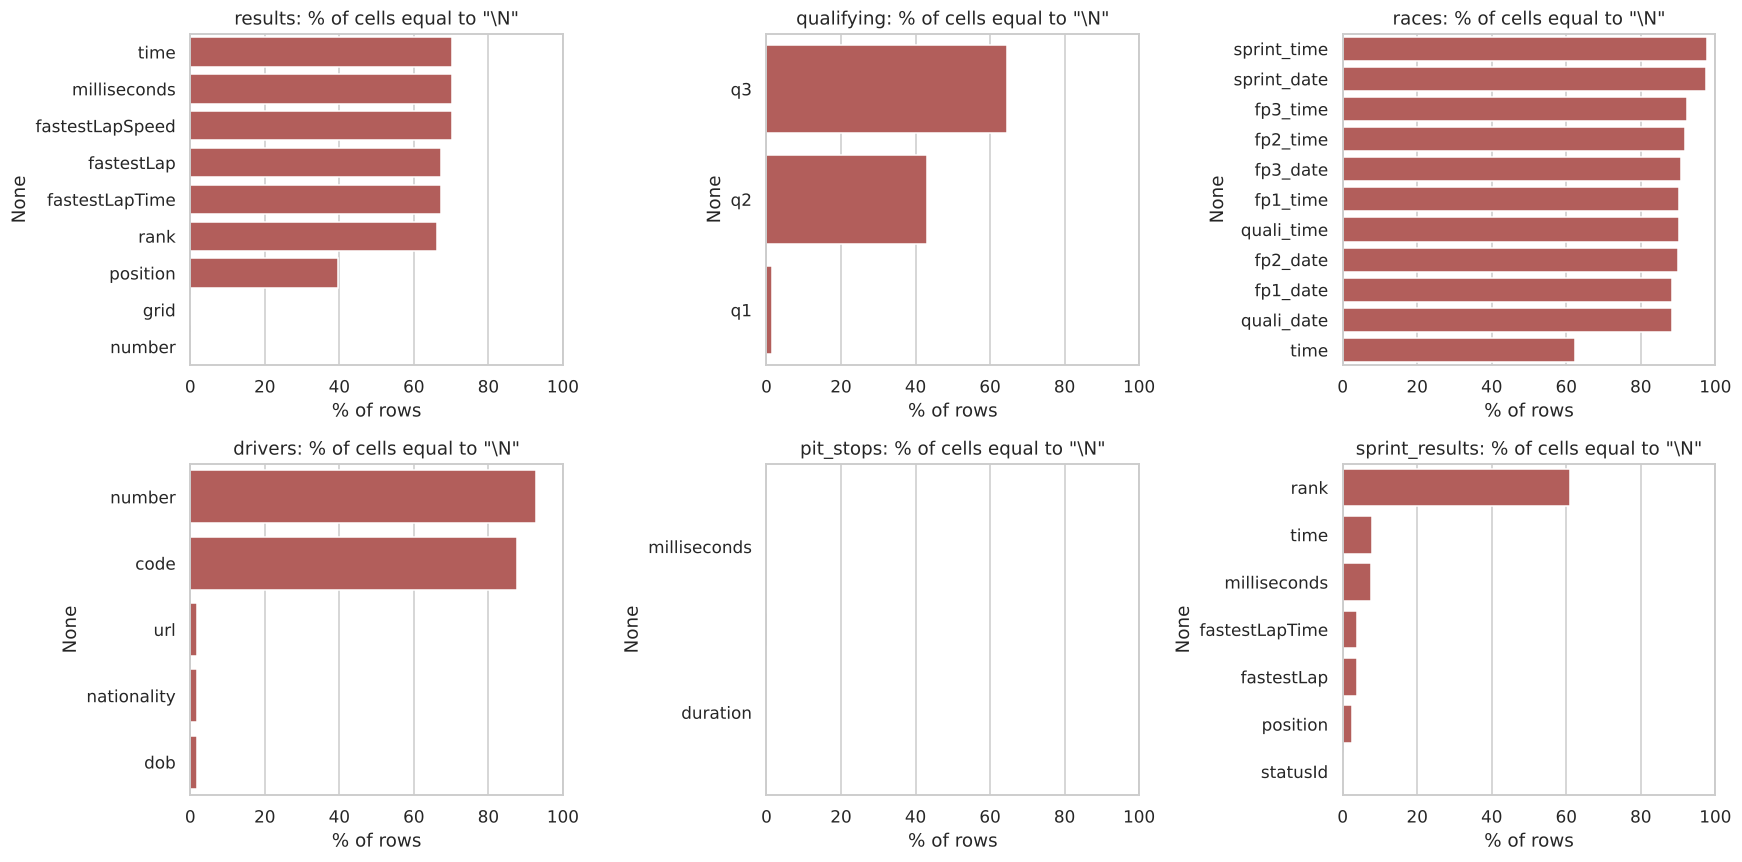

In [6]:
key_tables = ['results', 'qualifying', 'races', 'drivers', 'pit_stops', 'sprint_results']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, t in zip(axes.ravel(), key_tables):
    share = (raw[t] == '\\N').mean().sort_values(ascending=False)
    share = share[share > 0]
    if len(share):
        sns.barplot(x=share.values * 100, y=share.index, ax=ax, color='#c0504d')
    ax.set_title(f'{t}: % of cells equal to "\\N"'); ax.set_xlabel('% of rows'); ax.set_xlim(0, 100)
savefig('eda_raw_sentinels')

**What the scan shows.** The only real sentinel is the literal string `\N` (the MySQL export marker for NULL). It sits in numeric and date columns, for example `results.position` for non-finishers, `results.time`/`milliseconds` for anyone not on the lead lap, `qualifying.q2/q3` for drivers knocked out in Q1/Q2, and the session dates in `races` before 2021. Read naively, pandas would treat these columns as text, and `position` could never be compared numerically. Some text columns also have padding spaces (for example a nationality written `"Argentinian "`), which would split one category into two.

### 1.2 Coverage over time and the duplicate grain problem (raw data)

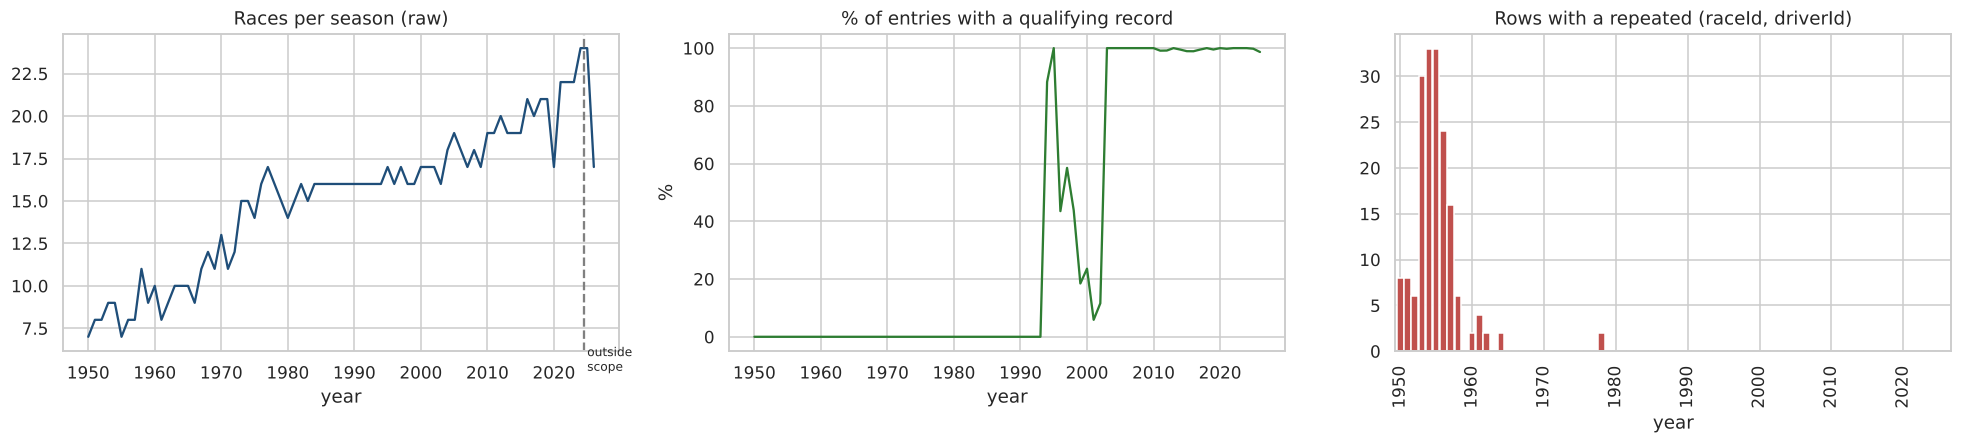

Seasons in the files: 1950 - 2026
Duplicate (raceId, driverId) rows in raw results: 176


,entries,races,quali_coverage,duplicate_rows
year,,,,
1990,542,16,0.000000,0.0
1991,539,16,0.000000,0.0
1992,478,16,0.000000,0.0
1993,412,16,0.000000,0.0
1994,444,16,0.882883,0.0
1995,418,17,1.000000,0.0
1996,340,16,0.435294,0.0
1997,376,17,0.585106,0.0
1998,349,16,0.438395,0.0


In [7]:
r_raw = raw['races'].assign(year=lambda d: d.year.astype(int), raceId=lambda d: d.raceId.astype(int))
res_raw = raw['results'].assign(raceId=lambda d: d.raceId.astype(int)).merge(r_raw[['raceId', 'year']], on='raceId')
q_raw = raw['qualifying'].assign(raceId=lambda d: d.raceId.astype(int))
res_raw = res_raw.merge(q_raw[['raceId', 'driverId']].assign(has_quali=1), on=['raceId', 'driverId'], how='left')

by_year = res_raw.groupby('year').agg(entries=('resultId', 'size'),
                                     races=('raceId', 'nunique'),
                                     quali_coverage=('has_quali', lambda s: s.notna().mean()))
dup_raw = res_raw[res_raw.duplicated(['raceId', 'driverId'], keep=False)]
by_year['duplicate_rows'] = dup_raw.groupby('year').size()
by_year = by_year.fillna({'duplicate_rows': 0})

fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
by_year['races'].plot(ax=axes[0], color='#1f4e79'); axes[0].set_title('Races per season (raw)')
axes[0].axvline(LAST_SEASON + .5, ls='--', c='grey'); axes[0].text(LAST_SEASON + 1, 5, 'outside\nscope', fontsize=8)
(by_year['quali_coverage'] * 100).plot(ax=axes[1], color='#2e7d32')
axes[1].set_title('% of entries with a qualifying record'); axes[1].set_ylabel('%')
by_year['duplicate_rows'].plot(kind='bar', ax=axes[2], color='#c0504d', width=.9)
axes[2].set_title('Rows with a repeated (raceId, driverId)')
axes[2].set_xticks(range(0, len(by_year), 10)); axes[2].set_xticklabels(by_year.index[::10])
savefig('eda_raw_coverage')
print('Seasons in the files:', by_year.index.min(), '-', by_year.index.max())
print('Duplicate (raceId, driverId) rows in raw results:', len(dup_raw))
by_year.loc[1990:2005]

**Findings that drive later decisions**
* **Qualifying coverage drift.** The `qualifying` table only starts in 1994. Between 1996 and 2002 coverage is patchy, and only from **2003** is every entry covered. Any qualifying feature is therefore only reliable from 2003 onward. This is why the modelling table uses seasons 2003–2024 (Section 5), and Section 9.3 tests this choice empirically.
* **Duplicate grain.** Some `(raceId, driverId)` pairs appear more than once, almost all in the 1950s (shared drives). They are handled in Section 2.4.
* The copy of the files used here may contain seasons after 2024. The assignment scope is 1950–2024, so later seasons are removed during cleaning (a no-op on the official Kaggle files).

> **Key takeaway:** the raw files hide missing values as the string `\N`, qualifying coverage is only complete from 2003, and 85 driver-race pairs are duplicated (1950s shared drives). Each of these is fixed or handled below.

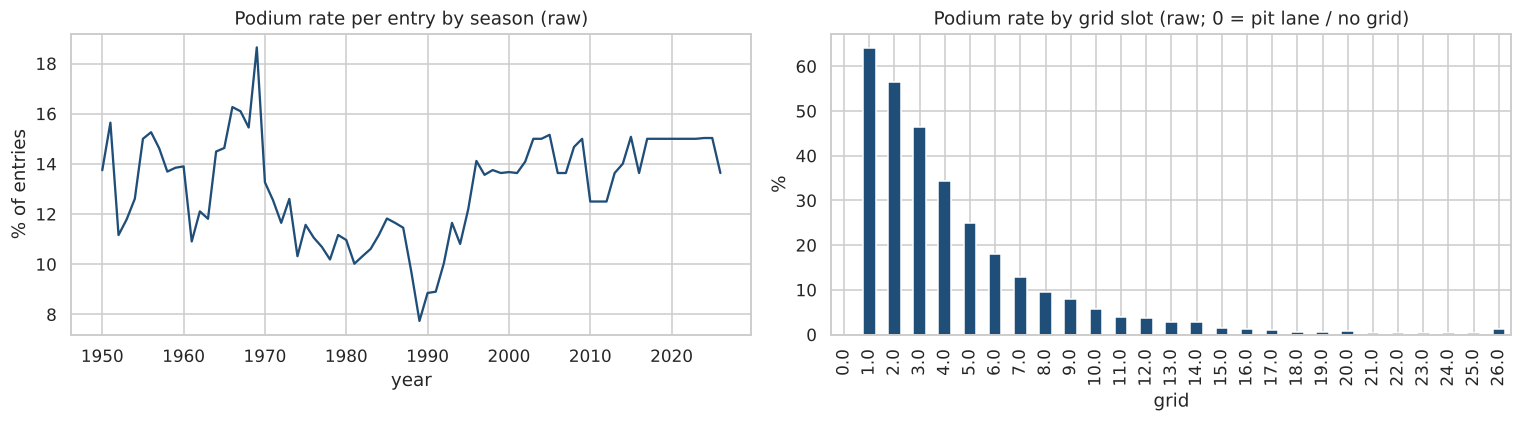

Overall podium rate: 0.127


In [8]:
# Target base rate and grid vs. finish structure in the raw data (cast on the fly, raw stays untouched)
tmp = res_raw.assign(positionOrder=res_raw.positionOrder.astype(int),
                     grid=pd.to_numeric(res_raw.grid, errors='coerce'))
tmp['podium'] = (tmp.positionOrder <= 3).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
tmp.groupby('year').podium.mean().mul(100).plot(ax=axes[0], color='#1f4e79')
axes[0].set_title('Podium rate per entry by season (raw)'); axes[0].set_ylabel('% of entries')
g = tmp[tmp.grid.between(0, 26)].groupby('grid').podium.mean().mul(100)
g.plot(kind='bar', ax=axes[1], color='#1f4e79'); axes[1].set_title('Podium rate by grid slot (raw; 0 = pit lane / no grid)')
axes[1].set_ylabel('%')
savefig('eda_raw_target')
print(f"Overall podium rate: {tmp.podium.mean():.3f}")

The positive class is rare: about 13% of entries overall. It is higher in the 1950s, when fields were small, and lower in eras with large fields. Grid position is by far the strongest visible signal. Note the **grid = 0** spike: it is not a real grid slot but a code (pit-lane start, or no grid position at all). Grid 0 needs a semantic fix, not numeric use.

## 2. Data cleaning
### 2.1 Sentinel handling and semantic typing
We declare a schema for each table: which columns are integer keys, numeric measures, calendar dates, or durations. Then each table is converted on a copy:
* `\N` and empty strings become real missing values (`NaN`/`NaT`), and text is stripped of padding.
* Keys and counts become (nullable) integers, measures become floats.
* Dates (`races.date`, session dates, `drivers.dob`) become `datetime64`.
* **Durations** (lap times like `1:27.452`, qualifying times, pit-stop durations, fastest laps) become **numeric seconds** via a parser that accepts `h:mm:ss.sss`, `m:ss.sss` and `ss.sss`.
* Seasons after 2024 are dropped (`races`) and child tables keep only races in scope.

In [9]:
%%writefile f1podium/cleaning.py
"""Cleaning: sentinel handling, semantic typing, season scope, categorical canonicalisation."""
import numpy as np
import pandas as pd

TABLES = ['circuits', 'constructors', 'constructor_results', 'constructor_standings', 'drivers',
          'driver_standings', 'races', 'results', 'qualifying', 'lap_times', 'pit_stops',
          'sprint_results', 'seasons', 'status']
RACE_CHILD_TABLES = ['results', 'qualifying', 'lap_times', 'pit_stops', 'sprint_results', 'driver_standings',
                     'constructor_standings', 'constructor_results']
COUNTRY_CANON = {'United States': 'USA', 'United Kingdom': 'UK', 'Great Britain': 'UK', 'UAE': 'United Arab Emirates'}
NAT_CANON = {'Argentinian': 'Argentine'}


def load_raw(data_dir):
    """Read every table as untyped text, exactly as written in the CSV (the \\N sentinel is kept)."""
    import os
    return {t: pd.read_csv(os.path.join(data_dir, f'{t}.csv'), dtype=str, keep_default_na=False, na_filter=False)
            for t in TABLES}


def parse_duration(series):
    """'1:27.452' -> 87.452 s ; '27.4' -> 27.4 s ; '1:02:03.5' -> 3723.5 s ; invalid/missing -> NaN"""
    def conv(x):
        if not isinstance(x, str) or not x.strip():
            return np.nan
        try:
            sec = 0.0
            for part in x.strip().split(':'):
                sec = sec * 60 + float(part)
            return sec
        except ValueError:
            return np.nan
    return series.map(conv).astype(float)

SCHEMA = {
    'circuits':  dict(int=['circuitId'], float=['lat', 'lng', 'alt']),
    'constructors': dict(int=['constructorId']),
    'constructor_results': dict(int=['constructorResultsId', 'raceId', 'constructorId'], float=['points']),
    'constructor_standings': dict(int=['constructorStandingsId', 'raceId', 'constructorId', 'position', 'wins'], float=['points']),
    'drivers': dict(int=['driverId'], float=['number'], date=['dob']),
    'driver_standings': dict(int=['driverStandingsId', 'raceId', 'driverId', 'position', 'wins'], float=['points']),
    'races': dict(int=['raceId', 'year', 'round', 'circuitId'], date=['date', 'fp1_date', 'fp2_date', 'fp3_date', 'quali_date', 'sprint_date']),
    'results': dict(int=['resultId', 'raceId', 'driverId', 'constructorId', 'positionOrder', 'laps', 'statusId'],
                    float=['number', 'grid', 'position', 'points', 'milliseconds', 'fastestLap', 'rank', 'fastestLapSpeed'],
                    duration=['fastestLapTime']),
    'qualifying': dict(int=['qualifyId', 'raceId', 'driverId', 'constructorId', 'position'], float=['number'],
                       duration=['q1', 'q2', 'q3']),
    'lap_times': dict(int=['raceId', 'driverId', 'lap', 'position'], float=['milliseconds'], duration=['time']),
    'pit_stops': dict(int=['raceId', 'driverId', 'stop', 'lap'], float=['milliseconds'], duration=['duration']),
    'sprint_results': dict(int=['resultId', 'raceId', 'driverId', 'constructorId', 'positionOrder', 'laps', 'statusId'],
                           float=['number', 'grid', 'position', 'points', 'milliseconds', 'fastestLap'],
                           duration=['fastestLapTime']),
    'seasons': dict(int=['year']),
    'status': dict(int=['statusId']),
}

def clean_table(df_raw, schema):
    """Return a typed copy of one raw table (the raw frame is never modified)."""
    df = df_raw.copy()
    for c in df.columns:
        df[c] = df[c].str.strip()
    df = df.replace({'\\N': np.nan, '': np.nan})
    for c in schema.get('int', []):
        df[c] = pd.to_numeric(df[c], errors='coerce').astype('Int64')
    for c in schema.get('float', []):
        df[c] = pd.to_numeric(df[c], errors='coerce').astype(float)
    for c in schema.get('date', []):
        df[c] = pd.to_datetime(df[c], errors='coerce')
    for c in schema.get('duration', []):
        df[c + '_s'] = parse_duration(df[c])
    return df


def apply_scope(clean, last_season):
    """Keep seasons <= last_season; child tables keep only races in scope. Returns {table: (before, after)}."""
    log = {}
    clean['races'] = clean['races'][clean['races'].year <= last_season].copy()
    clean['seasons'] = clean['seasons'][clean['seasons'].year <= last_season].copy()
    in_scope = set(clean['races'].raceId)
    for t in RACE_CHILD_TABLES:
        before = len(clean[t])
        clean[t] = clean[t][clean[t].raceId.isin(in_scope)].copy()
        log[t] = (before, len(clean[t]))
    return log


def fix_implausible_quali(clean, lo=40, hi=400):
    """Qualifying lap times outside [lo, hi] seconds are recording errors -> NaN."""
    for c in ['q1_s', 'q2_s', 'q3_s']:
        bad = (clean['qualifying'][c] < lo) | (clean['qualifying'][c] > hi)
        clean['qualifying'].loc[bad, c] = np.nan


def canonicalise(clean):
    """One spelling per country / nationality (needed for the home-race join)."""
    clean['circuits']['country'] = clean['circuits'].country.replace(COUNTRY_CANON)
    clean['drivers']['nationality'] = clean['drivers'].nationality.str.strip().replace(NAT_CANON)


def drop_duplicate_laps(clean):
    """lap_times: the same lap loaded twice (identical or 1 ms rounding) -> keep the first copy."""
    clean['lap_times'] = clean['lap_times'].drop_duplicates(['raceId', 'driverId', 'lap'], keep='first').copy()

Writing f1podium/cleaning.py


In [10]:
import f1podium.cleaning as fc; importlib.reload(fc)
from f1podium.cleaning import parse_duration, SCHEMA, clean_table

clean = {t: clean_table(raw[t], SCHEMA[t]) for t in TABLES}

# scope: seasons <= 2024; child tables follow their race
for t, (b, a) in fc.apply_scope(clean, LAST_SEASON).items():
    print(f'{t:22s}: {b:>7d} -> {a:>7d} rows after season scope filter')

clean['results'].dtypes.to_frame('dtype').T

results               :   27612 ->   26759 rows after season scope filter
qualifying            :   11342 ->   10494 rows after season scope filter
lap_times             :  885381 ->  839147 rows after season scope filter
pit_stops             :   22802 ->   21292 rows after season scope filter
sprint_results        :     612 ->     360 rows after season scope filter
driver_standings      :   35741 ->   34863 rows after season scope filter
constructor_standings :   13818 ->   13391 rows after season scope filter
constructor_results   :   13052 ->   12625 rows after season scope filter


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,fastestLapTime_s
dtype,Int64,Int64,Int64,Int64,float64,float64,float64,str,Int64,float64,Int64,str,float64,float64,float64,str,float64,Int64,float64


### 2.2 Validating the semantic typing
Parsing durations by hand only helps if the result is correct. The files store some durations twice: as text (`lap_times.time`, `pit_stops.duration`) **and** as integer milliseconds. We use the second copy as an independent check of the parser.

In [11]:
chk = []
for t, col in [('lap_times', 'time_s'), ('pit_stops', 'duration_s')]:
    d = clean[t].dropna(subset=[col, 'milliseconds'])
    err = (d[col] - d.milliseconds / 1000).abs()
    chk.append({'table': t, 'rows checked': len(d), 'max abs error (s)': err.max(), 'share exact (<1 ms)': (err < 1e-3).mean()})
display(pd.DataFrame(chk))

# plausibility of qualifying times (seconds)
qt = clean['qualifying'][['q1_s', 'q2_s', 'q3_s']]
print(qt.describe().round(2))
bad_q = ((qt < 40) | (qt > 400)).sum()
print('Implausible qualifying times (<40 s or >400 s) set to NaN:', bad_q.to_dict())
fc.fix_implausible_quali(clean)

,table,rows checked,max abs error (s),share exact (<1 ms)
0,lap_times,839147,1.000000e-03,0.999889
1,pit_stops,21289,2.273737e-13,1.000000


           q1_s     q2_s     q3_s
count  10338.00  5847.00  3629.00
mean      88.53    87.77    87.41
std       15.39    12.11    12.26
min       53.90    53.65    53.38
25%       78.77    77.94    77.24
50%       87.14    87.12    87.04
75%       95.91    95.96    95.63
max     1002.64   132.47   129.78
Implausible qualifying times (<40 s or >400 s) set to NaN: {'q1_s': 1, 'q2_s': 0, 'q3_s': 0}


The text-to-seconds parser matches the millisecond column on every lap and pit stop (up to rounding), so the typed durations can be trusted. Very long "pit stops" (several minutes) are real: they are red-flag stoppages recorded as stops. We keep them in the typed table but never use pit stops as features (they happen during the race, so they are leakage).

### 2.3 Categorical consistency
Two text problems would quietly break later joins: the same country written two ways in `circuits.country` (`USA` vs `United States`), and padded or missing nationalities in `drivers`. Both are standardised here because Q2 (home race) joins on them.

In [12]:
print('circuit countries before:', sorted(clean['circuits'].country.dropna().unique()))
fc.canonicalise(clean)   # COUNTRY_CANON / NAT_CANON in f1podium/cleaning.py
print('circuit countries after: ', sorted(clean['circuits'].country.dropna().unique()))
print('drivers with missing nationality:', clean['drivers'].nationality.isna().sum())
print('distinct nationalities:', clean['drivers'].nationality.nunique())

circuit countries before: ['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA', 'United States']
circuit countries after:  ['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UK', 'USA', 'United Arab Emirates']
drivers with missing nationality: 16
distinct nationalities: 42


### 2.4 Key integrity: primary keys and foreign keys

In [13]:
PK = {'circuits': ['circuitId'], 'constructors': ['constructorId'], 'drivers': ['driverId'], 'races': ['raceId'],
      'seasons': ['year'], 'status': ['statusId'], 'results': ['resultId'], 'qualifying': ['qualifyId'],
      'sprint_results': ['resultId'], 'driver_standings': ['driverStandingsId'],
      'constructor_standings': ['constructorStandingsId'], 'constructor_results': ['constructorResultsId'],
      'lap_times': ['raceId', 'driverId', 'lap'], 'pit_stops': ['raceId', 'driverId', 'stop']}
NATURAL = {'results': ['raceId', 'driverId'], 'qualifying': ['raceId', 'driverId'], 'races': ['year', 'round'],
           'driver_standings': ['raceId', 'driverId'], 'constructor_standings': ['raceId', 'constructorId'],
           'sprint_results': ['raceId', 'driverId']}

def pk_report(tables):
    out = []
    for t, cols in PK.items():
        df = tables[t]
        out.append({'table': t, 'key': '+'.join(cols), 'kind': 'primary', 'rows': len(df),
                    'null keys': int(df[cols].isna().any(axis=1).sum()),
                    'duplicate keys': int(df.duplicated(cols).sum())})
    for t, cols in NATURAL.items():
        df = tables[t]
        out.append({'table': t, 'key': '+'.join(cols), 'kind': 'natural / grain', 'rows': len(df),
                    'null keys': int(df[cols].isna().any(axis=1).sum()),
                    'duplicate keys': int(df.duplicated(cols).sum())})
    return pd.DataFrame(out)

pk_table = pk_report(clean)
pk_table

,table,key,kind,rows,null keys,duplicate keys
0,circuits,circuitId,primary,78,0,0
1,constructors,constructorId,primary,214,0,0
2,drivers,driverId,primary,881,0,0
3,races,raceId,primary,1125,0,0
4,seasons,year,primary,75,0,0
5,status,statusId,primary,143,0,0
6,results,resultId,primary,26759,0,0
7,qualifying,qualifyId,primary,10494,0,0
8,sprint_results,resultId,primary,360,0,0
9,driver_standings,driverStandingsId,primary,34863,0,0


In [14]:
# Every primary-key violation is examined, not just counted
lt = clean['lap_times']
lt_d = lt[lt.duplicated(['raceId', 'driverId', 'lap'], keep=False)].merge(clean['races'][['raceId', 'year']], on='raceId')
if len(lt_d):
    print('lap_times duplicate rows by season:', {int(k): int(v) for k, v in lt_d.year.value_counts().items()})
    print('exact duplicates:', int(lt.duplicated().sum()))
    g = lt_d.groupby(['raceId', 'driverId', 'lap']).milliseconds.agg(lambda s: s.max() - s.min())
    print('max time disagreement inside a duplicated lap (ms):', g.max())
    display(lt_d.sort_values(['raceId', 'driverId', 'lap']).head(6))
    # Same lap loaded twice (identical or 1 ms rounding difference) -> keep the first copy
    fc.drop_duplicate_laps(clean)
    print('lap_times rows after de-duplication:', len(clean['lap_times']))
# drivers with no nationality / dob: do they ever appear in a race result?
nat_missing = clean['drivers'][clean['drivers'].nationality.isna()]
print('drivers with missing nationality:', len(nat_missing), '| of them with any race entry:',
      int(nat_missing.driverId.isin(clean['results'].driverId).sum()))
pk_table = pk_report(clean)
pk_table[pk_table['duplicate keys'] > 0]

lap_times duplicate rows by season: {1989: 2082, 1988: 1876}


exact duplicates: 1707
max time disagreement inside a duplicated lap (ms): 13927.0


,raceId,driverId,lap,position,time,milliseconds,time_s,year
1589,356,65,1,8,1:45.968,105968.0,105.968,1989
2917,356,65,1,8,1:45.968,105968.0,105.968,1989
1590,356,65,2,8,1:37.405,97405.0,97.405,1989
2918,356,65,2,8,1:37.405,97405.0,97.405,1989
1591,356,65,3,8,1:36.617,96617.0,96.617,1989
2919,356,65,3,8,1:36.616,96616.0,96.616,1989


lap_times rows after de-duplication: 837168
drivers with missing nationality: 16 | of them with any race entry: 0


,table,key,kind,rows,null keys,duplicate keys
14,results,raceId+driverId,natural / grain,26759,0,91


**Primary-key findings.**
* `lap_times`: a block of laps from the 1988–1989 seasons was loaded twice. The copies are identical or differ by 1 ms of rounding, so we keep the first copy and the composite key `(raceId, driverId, lap)` becomes unique.
* `drivers`: the records with `\N` nationality/date of birth are reserve and practice-only drivers who never started a race. They cannot affect any race-level analysis, so they are kept with missing values.
* `driver_standings.position` is `\N` (with `positionText = '-'`) for a handful of rows. These are drivers excluded from a championship (e.g. a disqualification from the standings). They stay missing, and no standings feature reads them as rank 0.
* The only remaining duplicate key is the grain of `results`, handled in 2.5.

In [15]:
FK = [('results', 'raceId', 'races', 'raceId'), ('results', 'driverId', 'drivers', 'driverId'),
      ('results', 'constructorId', 'constructors', 'constructorId'), ('results', 'statusId', 'status', 'statusId'),
      ('qualifying', 'raceId', 'races', 'raceId'), ('qualifying', 'driverId', 'drivers', 'driverId'),
      ('qualifying', 'constructorId', 'constructors', 'constructorId'),
      ('races', 'circuitId', 'circuits', 'circuitId'), ('races', 'year', 'seasons', 'year'),
      ('driver_standings', 'raceId', 'races', 'raceId'), ('driver_standings', 'driverId', 'drivers', 'driverId'),
      ('constructor_standings', 'raceId', 'races', 'raceId'),
      ('constructor_standings', 'constructorId', 'constructors', 'constructorId'),
      ('constructor_results', 'raceId', 'races', 'raceId'),
      ('constructor_results', 'constructorId', 'constructors', 'constructorId'),
      ('lap_times', 'raceId', 'races', 'raceId'), ('lap_times', 'driverId', 'drivers', 'driverId'),
      ('pit_stops', 'raceId', 'races', 'raceId'), ('pit_stops', 'driverId', 'drivers', 'driverId'),
      ('sprint_results', 'raceId', 'races', 'raceId'), ('sprint_results', 'driverId', 'drivers', 'driverId'),
      ('sprint_results', 'constructorId', 'constructors', 'constructorId'),
      ('sprint_results', 'statusId', 'status', 'statusId')]

def fk_report(tables):
    out = []
    for child, ccol, parent, pcol in FK:
        vals = tables[child][ccol].dropna()
        orphan = ~vals.isin(set(tables[parent][pcol].dropna()))
        out.append({'child': f'{child}.{ccol}', 'parent': f'{parent}.{pcol}', 'child rows': len(vals),
                    'orphans': int(orphan.sum()), 'null FK': int(tables[child][ccol].isna().sum())})
    # composite: every lap / pit stop / qualifying row should belong to an entry in results
    ent = set(map(tuple, tables['results'][['raceId', 'driverId']].astype(int).values))
    for child in ['lap_times', 'pit_stops', 'qualifying']:
        keys = list(map(tuple, tables[child][['raceId', 'driverId']].astype(int).values))
        out.append({'child': f'{child}.(raceId,driverId)', 'parent': 'results.(raceId,driverId)', 'child rows': len(keys),
                    'orphans': int(sum(k not in ent for k in keys)), 'null FK': 0})
    return pd.DataFrame(out)

fk_table = fk_report(clean)
fk_table

,child,parent,child rows,orphans,null FK
0,results.raceId,races.raceId,26759,0,0
1,results.driverId,drivers.driverId,26759,0,0
2,results.constructorId,constructors.constructorId,26759,0,0
3,results.statusId,status.statusId,26759,0,0
4,qualifying.raceId,races.raceId,10494,0,0
5,qualifying.driverId,drivers.driverId,10494,0,0
6,qualifying.constructorId,constructors.constructorId,10494,0,0
7,races.circuitId,circuits.circuitId,1125,0,0
8,races.year,seasons.year,1125,0,0
9,driver_standings.raceId,races.raceId,34863,0,0


In [16]:
# Resolve orphans (if any): rows that point to a parent that does not exist cannot be joined, so they are dropped
# (single-column FKs). Composite orphans are only reported: a qualifying row without a race entry is a DNQ/withdrawal.
n_drop = 0
for child, ccol, parent, pcol in FK:
    mask = clean[child][ccol].notna() & ~clean[child][ccol].isin(set(clean[parent][pcol].dropna()))
    n_drop += int(mask.sum()); clean[child] = clean[child][~mask].copy()
print('Rows dropped for broken single-column foreign keys:', n_drop)
RESULTS['fk_orphans_dropped'] = n_drop

Rows dropped for broken single-column foreign keys: 0


**Key integrity.** All surrogate primary keys (`resultId`, `raceId`, `driverId`, …) are unique and non-null, and the composite keys of `lap_times` and `pit_stops` are unique. The foreign-key table above checks every reference against its parent. After the season-scope filter, every key that should resolve does resolve, and any orphan would be dropped by the cell above. The one key that is **not** unique is the natural grain of `results`: `(raceId, driverId)`. That is the duplicate problem handled next.

### 2.5 Fixing the grain: one row per (raceId, driverId)

In [17]:
res_c = clean['results'].merge(clean['races'][['raceId', 'year', 'name']], on='raceId')
dmask = res_c.duplicated(['raceId', 'driverId'], keep=False)
dups = res_c[dmask].sort_values(['raceId', 'driverId', 'resultId'])
print(f'{dmask.sum()} rows belong to {dups.groupby(["raceId","driverId"]).ngroups} duplicated (raceId, driverId) pairs')
print('Seasons affected:', {int(k): int(v) for k, v in dups.year.value_counts().sort_index().items()})
dups[['raceId', 'year', 'name', 'driverId', 'constructorId', 'number', 'grid', 'positionOrder', 'points', 'laps', 'statusId']].head(12)

176 rows belong to 85 duplicated (raceId, driverId) pairs
Seasons affected: {1950: 8, 1951: 8, 1952: 6, 1953: 30, 1954: 33, 1955: 33, 1956: 24, 1957: 16, 1958: 6, 1960: 2, 1961: 4, 1962: 2, 1964: 2, 1978: 2}


,raceId,year,name,driverId,constructorId,number,grid,positionOrder,points,laps,statusId
13188,540,1978,Italian Grand Prix,229,54,10.0,0.0,26,0.0,0,81
13191,540,1978,Italian Grand Prix,229,57,23.0,0.0,29,0.0,0,97
17362,717,1964,United States Grand Prix,373,172,1.0,1.0,7,0.0,102,60
24298,717,1964,United States Grand Prix,373,172,2.0,1.0,12,0.0,54,98
17740,733,1962,British Grand Prix,465,172,48.0,0.0,22,0.0,0,54
17743,733,1962,British Grand Prix,465,97,50.0,0.0,25,0.0,0,54
17961,742,1961,British Grand Prix,475,102,26.0,20.0,19,0.0,56,2
17963,742,1961,British Grand Prix,475,172,28.0,5.0,21,0.0,44,23
18062,745,1961,United States Grand Prix,418,172,22.0,11.0,17,0.0,23,6
24297,745,1961,United States Grand Prix,418,172,21.0,15.0,11,0.0,92,18


**What the duplicates are.** In early F1 a driver could hand over or take over a car mid-race (**shared drive**). Each car they drove gets its own result row, often with different car numbers, grid slots, laps and finishing positions. Usually the second row has `grid = 0`, because they did not start in that car.

**Rule chosen (one row per pair):**
1. **Pre-race attributes** (constructor, car number, grid) come from the row of the car the driver **started** in: the row with the smallest valid grid (`grid > 0`), and the lowest `resultId` if tied. A prediction is made before the race, so the only pre-race facts that exist are those of the starting car.
2. **Outcome** (`positionOrder`, used only for the target and for *past* form features) is the **best classified result across the driver's rows**, and points are summed. The official records credit a shared drive to every driver involved, so a driver who took over a car and brought it home 2nd *did* finish on the podium.
3. The number of merged rows is kept in `n_entries` for traceability.

Simpler options were rejected. "Keep the first row" would keep the outcome of the car the driver abandoned, mislabelling official podiums. "Drop all duplicated pairs" would delete real drivers from 1950s races and distort field sizes. Either way, this only affects 1950s–1970s races, which fall outside the 2003–2024 modelling window. The rule matters for Q2 (all eras) and for career-history features.

> **Key takeaway (cleaning):** `\N` becomes real NaN; dates and durations are typed and the duration parser is verified against the millisecond columns; all primary and foreign keys are checked (0 orphans); doubled 1988–89 laps are removed; results go from 26,759 rows to **26,668 unique driver-races**.

In [18]:
%%writefile f1podium/grain.py
"""Grain fix: exactly one row per (raceId, driverId)."""
import numpy as np
import pandas as pd


def dedupe_results(res):
    """Shared drives -> one row. Pre-race attributes from the car the driver STARTED (lowest valid grid,
    then lowest resultId); outcome = best positionOrder over the driver's rows; points summed; n_entries kept."""
    r = res.copy()
    r['_g'] = r.grid.where(r.grid > 0, np.inf)
    r = r.sort_values(['raceId', 'driverId', '_g', 'resultId'])
    agg = r.groupby(['raceId', 'driverId']).agg(positionOrder_best=('positionOrder', 'min'),
                                                points_total=('points', 'sum'),
                                                n_entries=('resultId', 'size')).reset_index()
    first = r.drop_duplicates(['raceId', 'driverId'], keep='first').drop(columns='_g')
    out = first.merge(agg, on=['raceId', 'driverId'])
    out['positionOrder'] = out['positionOrder_best'].astype('Int64')
    out['points'] = out['points_total']
    return out.drop(columns=['positionOrder_best', 'points_total'])

Writing f1podium/grain.py


In [19]:
import f1podium.grain as fg; importlib.reload(fg)
from f1podium.grain import dedupe_results
results_u = dedupe_results(clean['results'])
assert not results_u.duplicated(['raceId', 'driverId']).any()
print(f'results: {len(clean["results"])} rows -> {len(results_u)} unique driver-race rows '
      f'({len(clean["results"]) - len(results_u)} rows merged)')
changed = results_u[results_u.n_entries > 1]
print('Pairs whose podium label differs between "first row" and the chosen rule:',
      int(((dups.drop_duplicates(["raceId", "driverId"]).set_index(["raceId", "driverId"]).positionOrder <= 3).astype(int)
           != (changed.set_index(["raceId", "driverId"]).positionOrder <= 3).astype(int)).sum()))
RESULTS['dup_rows'] = int(dmask.sum()); RESULTS['dup_pairs'] = int(dups.groupby(["raceId", "driverId"]).ngroups)
RESULTS['results_rows_clean'] = len(results_u)
clean['results_u'] = results_u

results: 26759 rows -> 26668 unique driver-race rows (91 rows merged)
Pairs whose podium label differs between "first row" and the chosen rule: 16


## 3. EDA after cleaning: what the cleaning changed

,detected missing BEFORE (%),detected missing AFTER (%)
grid,0.0,0.00
position,0.0,40.91
time,0.0,71.22
milliseconds,0.0,71.22
fastestLapTime,0.0,69.06
number,0.0,0.02


,raw dtype,clean dtype
grid,str,float64
position,str,float64
time,str,str
milliseconds,str,float64
fastestLapTime,str,str
number,str,float64


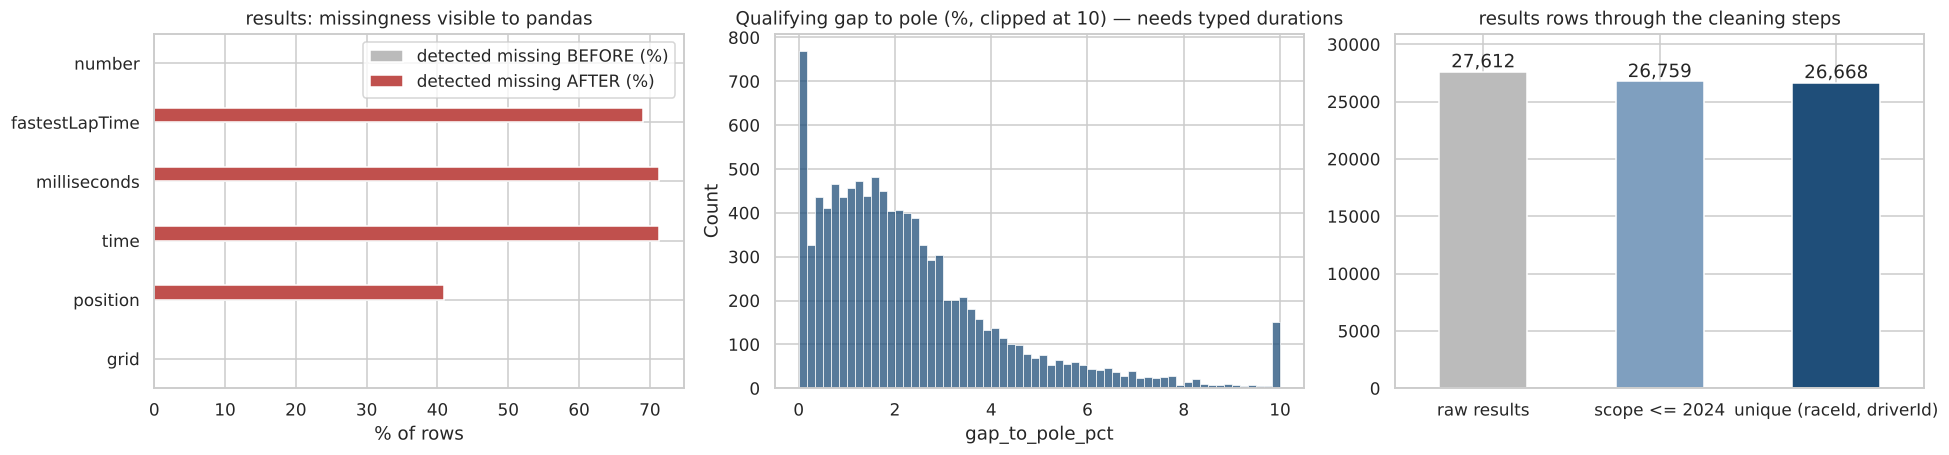

In [20]:
# (a) Missingness: before cleaning pandas sees zero missing cells (the \N strings look like valid text)
cols = ['grid', 'position', 'time', 'milliseconds', 'fastestLapTime', 'number']
before = raw['results'][cols].replace('', np.nan).isna().mean() * 100      # pandas' default view of the raw strings
after = clean['results_u'][cols].isna().mean() * 100
miss_cmp = pd.DataFrame({'detected missing BEFORE (%)': before, 'detected missing AFTER (%)': after}).round(2)
display(miss_cmp)
dtype_cmp = pd.DataFrame({'raw dtype': raw['results'][cols].dtypes.astype(str),
                          'clean dtype': clean['results_u'][cols].dtypes.astype(str)})
display(dtype_cmp)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
miss_cmp.plot(kind='barh', ax=axes[0], color=['#bbbbbb', '#c0504d'])
axes[0].set_title('results: missingness visible to pandas'); axes[0].set_xlabel('% of rows')

# (b) qualifying best time in seconds (only possible after duration typing)
q = clean['qualifying'].copy()
q['best_q_s'] = q[['q1_s', 'q2_s', 'q3_s']].min(axis=1)
q = q.merge(clean['races'][['raceId', 'year']], on='raceId')
q['gap_to_pole_pct'] = (q.best_q_s / q.groupby('raceId').best_q_s.transform('min') - 1) * 100
sns.histplot(q.gap_to_pole_pct.clip(upper=10), bins=60, ax=axes[1], color='#1f4e79')
axes[1].set_title('Qualifying gap to pole (%, clipped at 10) — needs typed durations')

# (c) row funnel through the cleaning steps
funnel = pd.Series({'raw results': len(raw['results']), 'scope <= 2024': len(clean['results']),
                    'unique (raceId, driverId)': len(clean['results_u'])})
funnel.plot(kind='bar', ax=axes[2], color=['#bbbbbb', '#7f9fbf', '#1f4e79'], rot=0)
for i, v in enumerate(funnel.values):
    axes[2].text(i, v, f'{v:,}', ha='center', va='bottom')
axes[2].set_title('results rows through the cleaning steps'); axes[2].set_ylim(0, funnel.max() * 1.12)
savefig('eda_clean_effect')

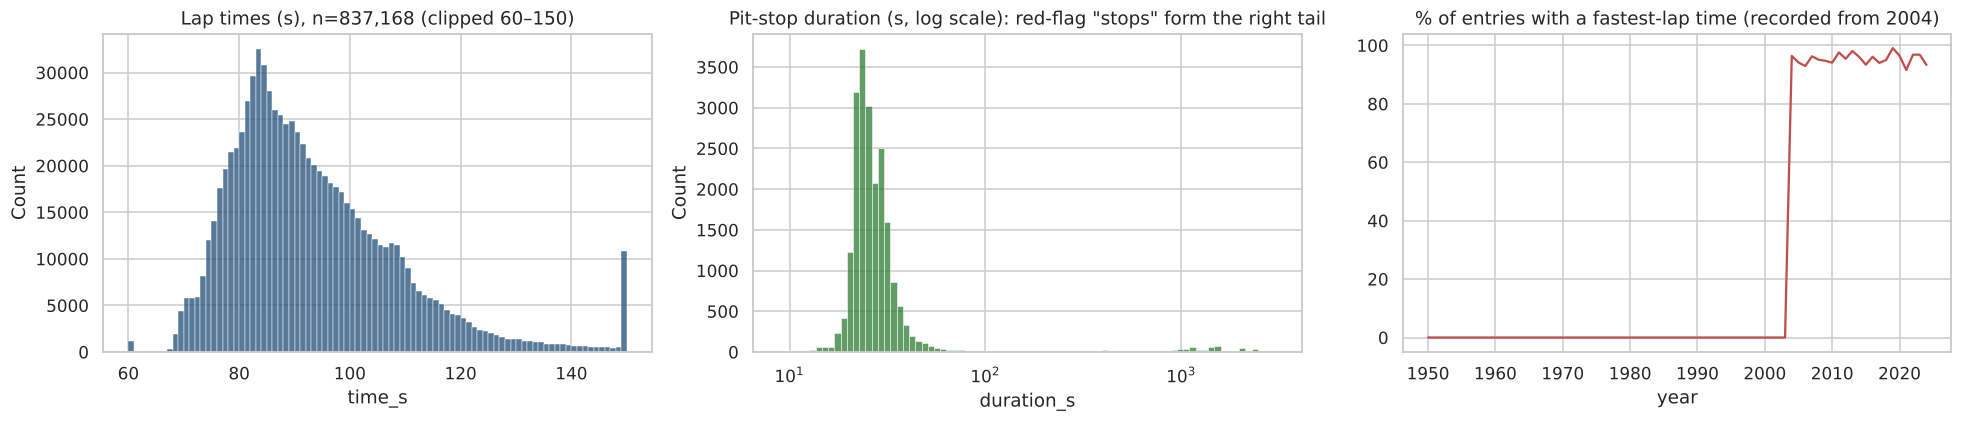

In [21]:
# Distributions of the other typed durations
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
lt = clean['lap_times'].merge(clean['races'][['raceId', 'year']], on='raceId')
sns.histplot(lt.time_s.clip(60, 150), bins=90, ax=axes[0], color='#1f4e79')
axes[0].set_title(f'Lap times (s), n={len(lt):,} (clipped 60–150)')
ps = clean['pit_stops']
sns.histplot(ps.duration_s, bins=80, log_scale=True, ax=axes[1], color='#2e7d32')
axes[1].set_title('Pit-stop duration (s, log scale): red-flag "stops" form the right tail')
fl = clean['results_u'].merge(clean['races'][['raceId', 'year']], on='raceId')
fl.groupby('year').fastestLapTime_s.apply(lambda s: s.notna().mean() * 100).plot(ax=axes[2], color='#c0504d')
axes[2].set_title('% of entries with a fastest-lap time (recorded from 2004)')
savefig('eda_clean_durations')

**Effect of cleaning.**
* Before cleaning, pandas reported **0% missing** in `results` because every `\N` was a valid-looking string, and numeric columns were stored as text. After cleaning, the real structure shows: about 40% of `position` is missing (non-classified finishers), about 70% of race `time` is missing (anyone not on the lead lap), and `grid` is now numeric, so grid 0 can be handled on purpose.
* Duration typing is what makes features such as the **qualifying gap to pole** possible. Its distribution is right-skewed with a long tail (backmarkers, wet sessions, missing Q1 times). This suggests clipping or a rank-based treatment.
* The fastest-lap columns only exist from 2004 and describe the race being predicted, so they are excluded from features anyway.

> **Key takeaway:** before cleaning, pandas saw 0% missing data. After cleaning, the true missingness (non-finishers, lapped cars, Q2/Q3 knock-outs) is visible and every column has its proper type.

### 3.1 The analysis table: one row per driver-race, joined across tables
The data-engineering questions and the features all start from one joined table: `results_u` (unique grain) ⨝ `races` ⨝ `circuits` ⨝ `drivers` ⨝ `constructors` ⨝ `status` ⨝ `qualifying`.

In [22]:
%%writefile f1podium/entries.py
"""Joined driver-race analysis table, status taxonomy and home-race flag."""
import numpy as np
import pandas as pd

FINISHED_PATTERN = r'^(Finished|\+\d+ Laps?|Lapped)$'
# Mechanical retirement = a component of the car failed (no crash, no driver error, no regulation decision)
MECHANICAL = {'Engine', 'Gearbox', 'Transmission', 'Clutch', 'Hydraulics', 'Electrical', 'Radiator', 'Suspension',
              'Brakes', 'Differential', 'Overheating', 'Mechanical', 'Driveshaft', 'Fuel pressure', 'Water pressure',
              'Throttle', 'Steering', 'Technical', 'Electronics', 'Exhaust', 'Oil leak', 'Water leak', 'Fuel pump',
              'Oil pressure', 'Engine fire', 'Engine misfire', 'Pneumatics', 'Fuel system', 'Oil line', 'Power loss',
              'Drivetrain', 'Ignition', 'Battery', 'Halfshaft', 'Crankshaft', 'Alternator', 'Oil pump', 'Fuel leak',
              'Injection', 'Distributor', 'Turbo', 'CV joint', 'Water pump', 'Spark plugs', 'Fuel pipe', 'Oil pipe',
              'Axle', 'Water pipe', 'Magneto', 'Supercharger', 'Power Unit', 'ERS', 'Brake duct', 'Cooling system',
              'Wheel bearing', 'Wheel rim', 'Wheel', 'Heat shield fire', 'Launch control', 'Vibrations', 'Vibration',
              'Handling', 'Seat', 'Driver Seat', 'Safety belt', 'Undertray', 'Chassis', 'Fuel'}
NOT_STARTED = {'Did not qualify', 'Did not prequalify', 'Did not start', 'Withdrew', '107% Rule', 'Excluded'}

# nationality adjective -> circuit country name(s) (dual nationalities count both)
NAT2COUNTRY = {'British': ['UK'], 'German': ['Germany'], 'East German': ['Germany'], 'Spanish': ['Spain'],
               'Finnish': ['Finland'], 'Japanese': ['Japan'], 'French': ['France'], 'Polish': ['Poland'],
               'Brazilian': ['Brazil'], 'Italian': ['Italy'], 'Australian': ['Australia'], 'Austrian': ['Austria'],
               'American': ['USA'], 'Dutch': ['Netherlands'], 'Colombian': ['Colombia'], 'Portuguese': ['Portugal'],
               'Canadian': ['Canada'], 'Indian': ['India'], 'Hungarian': ['Hungary'], 'Irish': ['Ireland'],
               'Danish': ['Denmark'], 'Argentine': ['Argentina'], 'Czech': ['Czech Republic'], 'Malaysian': ['Malaysia'],
               'Swiss': ['Switzerland'], 'Belgian': ['Belgium'], 'Monegasque': ['Monaco'], 'Swedish': ['Sweden'],
               'Venezuelan': ['Venezuela'], 'New Zealander': ['New Zealand'], 'Chilean': ['Chile'], 'Mexican': ['Mexico'],
               'South African': ['South Africa'], 'Liechtensteiner': ['Liechtenstein'], 'Rhodesian': ['Rhodesia'],
               'American-Italian': ['USA', 'Italy'], 'Argentine-Italian': ['Argentina', 'Italy'], 'Uruguayan': ['Uruguay'],
               'Thai': ['Thailand'], 'Russian': ['Russia'], 'Indonesian': ['Indonesia'], 'Chinese': ['China'],
               'Emirati': ['United Arab Emirates'], 'Saudi': ['Saudi Arabia'], 'Moroccan': ['Morocco'], 'Turkish': ['Turkey']}


def is_home(nat, country):
    """True if the circuit is in (one of) the driver's nationality countries."""
    return isinstance(nat, str) and country in NAT2COUNTRY.get(nat, [])


def status_table(status):
    s = status.copy()
    s['is_finished'] = s.status.str.match(FINISHED_PATTERN)
    s['is_mechanical'] = s.status.isin(MECHANICAL)
    s['is_started'] = ~s.status.isin(NOT_STARTED)
    return s


def build_entries(clean):
    """results_u (unique grain) + races + circuits + drivers + constructors + status + qualifying. One row per driver-race."""
    status = status_table(clean['status'])
    races_x = clean['races'].merge(clean['circuits'][['circuitId', 'circuitRef', 'name', 'country']]
                                   .rename(columns={'name': 'circuit_name', 'country': 'circuit_country'}), on='circuitId')
    e = (clean['results_u']
         .merge(races_x[['raceId', 'year', 'round', 'date', 'name', 'circuitId', 'circuitRef', 'circuit_name', 'circuit_country']], on='raceId')
         .merge(clean['drivers'][['driverId', 'driverRef', 'forename', 'surname', 'dob', 'nationality']], on='driverId')
         .merge(clean['constructors'][['constructorId', 'name']].rename(columns={'name': 'constructor'}), on='constructorId')
         .merge(status, on='statusId')
         .merge(clean['qualifying'][['raceId', 'driverId', 'position', 'q1_s', 'q2_s', 'q3_s']]
                .rename(columns={'position': 'quali_pos'}), on=['raceId', 'driverId'], how='left'))
    e['podium'] = (e.positionOrder <= 3).astype(int)
    e['home_race'] = [is_home(n, c) for n, c in zip(e.nationality, e.circuit_country)]
    e = e.sort_values(['date', 'raceId', 'positionOrder']).reset_index(drop=True)
    assert not e.duplicated(['raceId', 'driverId']).any() and len(e) == len(clean['results_u'])
    return e

Writing f1podium/entries.py


In [23]:
import f1podium.entries as fe; importlib.reload(fe)
from f1podium.entries import MECHANICAL, NOT_STARTED, NAT2COUNTRY, status_table, build_entries
status = status_table(clean['status'])
FINISHED = set(status.status[status.is_finished])
unclassified = status[~status.is_finished & ~status.is_mechanical]
print(f'{len(FINISHED)} finishing codes, {len(MECHANICAL & set(status.status))} mechanical codes; '
      f'non-mechanical retirement codes include: {sorted(unclassified.status)[:40]}')
entries = build_entries(clean)
print('entries:', entries.shape)

35 finishing codes, 68 mechanical codes; non-mechanical retirement codes include: ['107% Rule', 'Accident', 'Broken wing', 'Collision', 'Collision damage', 'Damage', 'Debris', 'Did not prequalify', 'Did not qualify', 'Did not start', 'Disqualified', 'Driver unwell', 'Excluded', 'Eye injury', 'Fatal accident', 'Fire', 'Front wing', 'Fuel rig', 'Illness', 'Injured', 'Injury', 'Not classified', 'Not restarted', 'Out of fuel', 'Physical', 'Puncture', 'Rear wing', 'Refuelling', 'Retired', 'Safety', 'Safety concerns', 'Safety switch', 'Spun off', 'Stalled', 'Track rod', 'Tyre', 'Tyre puncture', 'Underweight', 'Wheel nut', 'Withdrew']
entries: (26668, 44)


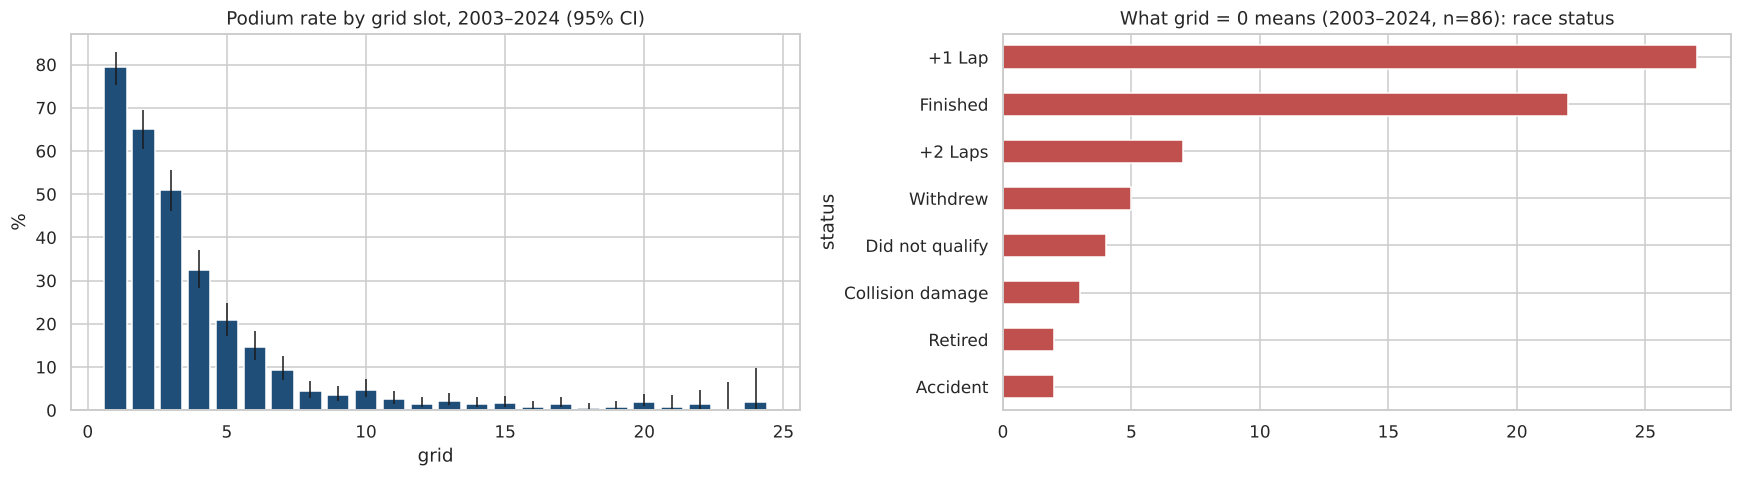

In [24]:
def ci_err(rate, lo, hi):
    """asymmetric error bars in percentage points, clipped at 0 (Wilson bounds can round past the estimate)"""
    rate, lo, hi = map(np.asarray, (rate, lo, hi))
    return np.clip(np.vstack([rate - lo, hi - rate]) * 100, 0, None)

# Grid vs. finish after cleaning (2003+, real grid slots only), podium rate with 95% Wilson intervals
e03 = entries[(entries.year >= 2003)]
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
gg = e03[e03.grid > 0].groupby('grid').podium.agg(['sum', 'count'])
gg = gg[gg['count'] >= 30]
lo, hi = proportion_confint(gg['sum'], gg['count'], method='wilson')
axes[0].bar(gg.index, gg['sum'] / gg['count'] * 100, color='#1f4e79')
axes[0].errorbar(gg.index, gg['sum'] / gg['count'] * 100, yerr=ci_err(gg['sum'] / gg['count'], lo, hi),
                 fmt='none', c='k', lw=1)
axes[0].set_title('Podium rate by grid slot, 2003–2024 (95% CI)'); axes[0].set_xlabel('grid'); axes[0].set_ylabel('%')
g0 = e03[e03.grid == 0].status.value_counts().head(8)
g0.plot(kind='barh', ax=axes[1], color='#c0504d'); axes[1].invert_yaxis()
axes[1].set_title(f'What grid = 0 means (2003–2024, n={int((e03.grid == 0).sum())}): race status')
savefig('eda_clean_grid')

After cleaning, `grid = 0` turns out to mean "no grid slot": pit-lane starters, plus entrants who did not start (DNS, withdrawn). In the feature table it becomes a **pit-lane flag** plus a grid value of "back of the field", so the model never reads it as "better than pole". Podium probability falls off steeply after the top 3–4 slots, which is the main structure the model has to learn.

> **Key takeaway:** grid position is the strongest raw signal (P1 → podium about 65% of the time, P10 → about 5%), and grid = 0 is a code, not a position.

## 4. Data-engineering questions
### Q1. Which circuits convert a front-row start into a podium most often, and does the ranking change after the 2014 hybrid era?
**Tables joined:** `results` (grid, finishing order) ⨝ `qualifying` (qualifying position) ⨝ `races` (season, circuit key) ⨝ `circuits` (name).
**Grain:** one row per driver-race. A front-row start is a row with position ≤ 2.
**Qualifying vs grid:** the qualifying position is the session result. The grid is the actual starting slot after penalties (gearbox/engine penalties, pit-lane starts, disqualification from qualifying). We compute the conversion rate both ways and count the cases where the two disagree.
**Window and missingness:** qualifying is only complete from 2003 (Section 1.2), so we compare **2003–2013 (pre-hybrid)** with **2014–2024 (hybrid)**. To limit noise, only circuits with at least 10 front-row starts in an era are ranked, and rates carry Wilson 95% intervals.
**Cutoff:** grid and qualifying position are known before the race; only the podium outcome is post-race, as the definition requires.

In [25]:
q1 = entries[entries.year >= 2003].copy()
q1['era'] = np.where(q1.year >= 2014, '2014–2024 hybrid', '2003–2013 pre-hybrid')
q1['front_row_grid'] = q1.grid.between(1, 2)
q1['front_row_quali'] = q1.quali_pos.between(1, 2)
print('Rows with missing qualifying position (2003+):', int(q1.quali_pos.isna().sum()))
mis = pd.crosstab(q1.front_row_quali, q1.front_row_grid, rownames=['front row in qualifying'], colnames=['front row on grid'])
display(mis)
print('Qualified on the front row but started further back (penalty/pit lane):',
      int((q1.front_row_quali & ~q1.front_row_grid).sum()),
      '| promoted onto the front row by others\' penalties:', int((~q1.front_row_quali & q1.front_row_grid).sum()))

def conversion(df, flag, min_n=10):
    t = df[df[flag]].groupby(['era', 'circuit_name']).podium.agg(podiums='sum', starts='count').reset_index()
    t = t[t.starts >= min_n].copy()
    t['rate'] = t.podiums / t.starts
    t['lo'], t['hi'] = proportion_confint(t.podiums, t.starts, method='wilson')
    t['rank'] = t.groupby('era').rate.rank(ascending=False, method='min')
    return t

conv_grid = conversion(q1, 'front_row_grid')
conv_quali = conversion(q1, 'front_row_quali')
overall = q1.groupby('era').apply(lambda d: pd.Series({
    'grid front-row conversion': d[d.front_row_grid].podium.mean(),
    'quali front-row conversion': d[d.front_row_quali].podium.mean()}))
display(overall.round(3))

wide = conv_grid.pivot(index='circuit_name', columns='era', values='rate')
both = wide.dropna()
rho, p_rho = stats.spearmanr(both.iloc[:, 0], both.iloc[:, 1])
print(f'Circuits ranked in both eras: {len(both)} | Spearman rank correlation between eras: rho={rho:.2f} (p={p_rho:.3f})')
for era in conv_grid.era.unique():
    print(f'\nTop 8 circuits, {era} (grid-based):')
    display(conv_grid[conv_grid.era == era].sort_values('rate', ascending=False).head(8)[['circuit_name', 'podiums', 'starts', 'rate', 'lo', 'hi']].round(3))
RESULTS['q1'] = dict(overall=overall.round(3).to_dict(), spearman=float(rho), spearman_p=float(p_rho), n_both=int(len(both)),
                     top_pre=conv_grid[conv_grid.era.str.startswith('2003')].nlargest(5, 'rate')[['circuit_name', 'rate', 'starts']].round(3).values.tolist(),
                     top_post=conv_grid[conv_grid.era.str.startswith('2014')].nlargest(5, 'rate')[['circuit_name', 'rate', 'starts']].round(3).values.tolist(),
                     quali_not_grid=int((q1.front_row_quali & ~q1.front_row_grid).sum()),
                     grid_not_quali=int((~q1.front_row_quali & q1.front_row_grid).sum()))

Rows with missing qualifying position (2003+): 24


front row on grid,False,True
front row in qualifying,,
False,8054,36
True,38,818


Qualified on the front row but started further back (penalty/pit lane): 38 | promoted onto the front row by others' penalties: 36


,grid front-row conversion,quali front-row conversion
era,,
2003–2013 pre-hybrid,0.68,0.672
2014–2024 hybrid,0.76,0.737


Circuits ranked in both eras: 14 | Spearman rank correlation between eras: rho=0.30 (p=0.292)

Top 8 circuits, 2003–2013 pre-hybrid (grid-based):


,circuit_name,podiums,starts,rate,lo,hi
9,Circuit de Nevers Magny-Cours,11,12,0.917,0.646,0.985
16,Istanbul Park,11,14,0.786,0.524,0.924
8,Circuit de Monaco,17,22,0.773,0.566,0.899
2,Autodromo Nazionale di Monza,17,22,0.773,0.566,0.899
23,Silverstone Circuit,16,22,0.727,0.518,0.868
24,Suzuka Circuit,13,18,0.722,0.491,0.875
10,Circuit de Spa-Francorchamps,13,18,0.722,0.491,0.875
13,Hockenheimring,10,14,0.714,0.454,0.883



Top 8 circuits, 2014–2024 hybrid (grid-based):


,circuit_name,podiums,starts,rate,lo,hi
57,Suzuka Circuit,16,18,0.889,0.672,0.969
58,Yas Marina Circuit,19,22,0.864,0.667,0.953
40,Circuit de Monaco,17,20,0.850,0.640,0.948
41,Circuit de Spa-Francorchamps,18,22,0.818,0.615,0.927
39,Circuit de Barcelona-Catalunya,18,22,0.818,0.615,0.927
56,Sochi Autodrom,13,16,0.812,0.570,0.934
42,Circuit of the Americas,16,20,0.800,0.584,0.919
33,Autódromo José Carlos Pace,15,19,0.789,0.567,0.915


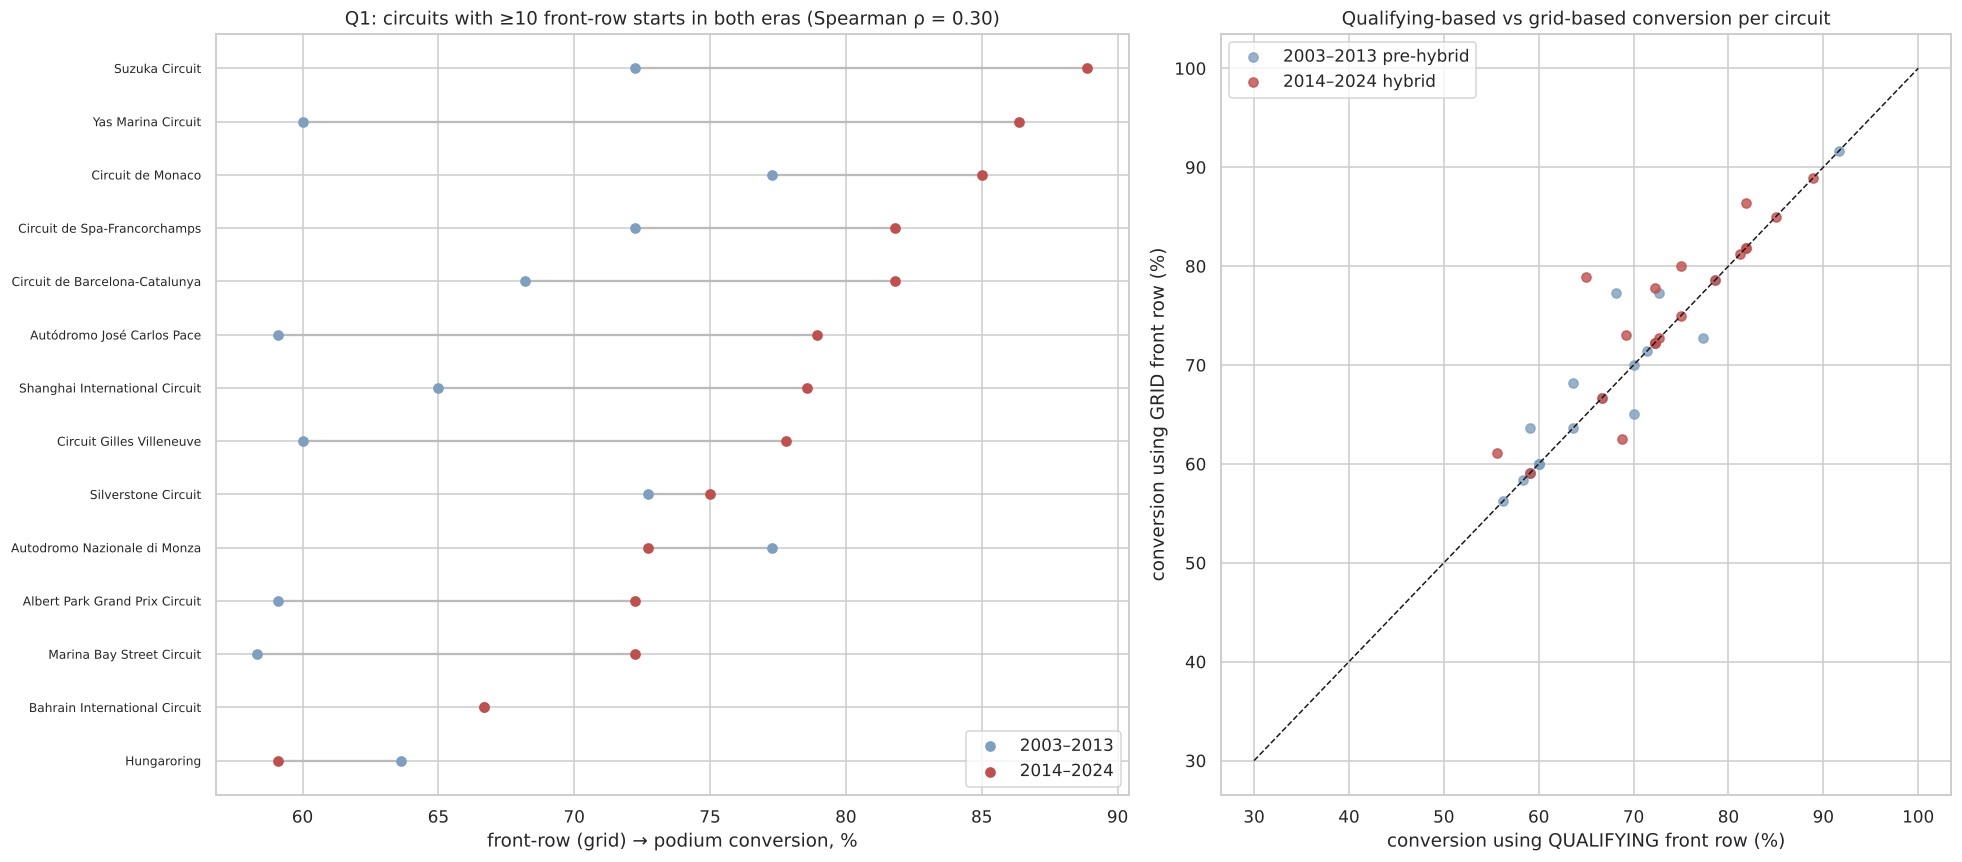

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={'width_ratios': [1.25, 1]})
plot_df = both.copy(); plot_df.columns = ['pre', 'post']
plot_df = plot_df.sort_values('post')
yy = np.arange(len(plot_df))
axes[0].hlines(yy, plot_df.pre * 100, plot_df.post * 100, color='#bbbbbb')
axes[0].scatter(plot_df.pre * 100, yy, color='#7f9fbf', label='2003–2013', zorder=3)
axes[0].scatter(plot_df.post * 100, yy, color='#c0504d', label='2014–2024', zorder=3)
axes[0].set_yticks(yy); axes[0].set_yticklabels(plot_df.index, fontsize=8)
axes[0].set_xlabel('front-row (grid) → podium conversion, %'); axes[0].legend(loc='lower right')
axes[0].set_title(f'Q1: circuits with ≥10 front-row starts in both eras (Spearman ρ = {rho:.2f})')
cmp_q = conv_grid.merge(conv_quali, on=['era', 'circuit_name'], suffixes=('_grid', '_quali'))
for era, col in zip(sorted(cmp_q.era.unique()), ['#7f9fbf', '#c0504d']):
    d = cmp_q[cmp_q.era == era]
    axes[1].scatter(d.rate_quali * 100, d.rate_grid * 100, label=era, color=col, alpha=.8)
axes[1].plot([30, 100], [30, 100], 'k--', lw=1)
axes[1].set_xlabel('conversion using QUALIFYING front row (%)'); axes[1].set_ylabel('conversion using GRID front row (%)')
axes[1].set_title('Qualifying-based vs grid-based conversion per circuit'); axes[1].legend()
savefig('q1_front_row_conversion')

**Q1 answer.**
* **Overall:** a front-row grid slot became a podium **68%** of the time in 2003–2013 and **76%** in 2014–2024. The hybrid era's dominant teams (Mercedes 2014–2020, Red Bull 2022–2023) made the front row a near-guarantee.
* **Top circuits.** Pre-hybrid: Magny-Cours (11/12), Istanbul Park, Monaco and Monza (≈77–92%). Hybrid: Suzuka (16/18 = 89%), Yas Marina (86%), Monaco (85%), Spa and Barcelona (82%).
* **Does the ranking change? Yes.** For the 14 circuits with ≥10 front-row starts in both eras, the Spearman rank correlation is only **ρ ≈ 0.30 (p ≈ 0.29)**, which is statistically indistinguishable from no relationship. Monaco stays near the top in both eras, consistent with how hard overtaking is there. Most other circuits move a lot, and the wide Wilson intervals (10–22 starts per circuit) show that much of the ordering is noise.
* **Qualifying vs grid.** They disagree for 74 driver-races: 38 front-row qualifiers started further back (grid penalties, pit-lane starts), and 36 drivers were promoted onto the front row by others' penalties. Grid-based conversion is slightly higher than qualifying-based (0.68 vs 0.67, 0.76 vs 0.74), because a qualifying front-row man demoted by a penalty seldom recovers to the podium. **The grid is the better pre-race signal, and the gap between qualifying and grid (the penalty) carries information**, which motivates the `grid_penalty` feature.

### Q2. Do drivers podium more often at home, after controlling for starting position?
**Tables joined:** `results` ⨝ `drivers` (nationality) ⨝ `races` ⨝ `circuits` (country).
**Home race:** the driver's nationality maps to the country of the circuit. Nationality adjectives are mapped to circuit-country names with an explicit dictionary, and dual nationalities such as "American-Italian" count both countries.
**Control for starting position:** we compare home and away podium rates **within grid bands** (1, 2–3, 4–6, 7–10, 11+). This gives a stratified Cochran–Mantel–Haenszel (CMH) pooled odds ratio and test, plus a logistic regression `podium ~ home + C(grid band) + C(decade)`.
**Grain, missingness and cutoff:** one row per driver-race. Rows with grid 0 (no grid slot) and drivers with unmappable nationality are excluded (counts printed). Home status and grid are both known before the race.

In [27]:
# NAT2COUNTRY and is_home() live in f1podium/entries.py (home_race is already computed in `entries`)
unmapped = sorted(set(entries.nationality.dropna()) - set(NAT2COUNTRY))
print('Nationalities without a mapping:', unmapped)

q2 = entries[(entries.grid > 0) & entries.nationality.isin(NAT2COUNTRY)].copy()
print(f'Q2 rows: {len(q2):,} (excluded: grid=0 -> {int((entries.grid <= 0).sum()):,}; unmapped nationality -> '
      f'{int(((entries.grid > 0) & ~entries.nationality.isin(NAT2COUNTRY)).sum())})')
q2['grid_band'] = pd.cut(q2.grid, [0, 1, 3, 6, 10, 99], labels=['P1', 'P2-3', 'P4-6', 'P7-10', 'P11+'])
q2['decade'] = (q2.year // 10 * 10).astype(str)
print(f"Home entries: {int(q2.home_race.sum()):,} ({q2.home_race.mean():.1%})")
print('Raw (uncontrolled) podium rate: home', round(q2[q2.home_race].podium.mean(), 3), '| away', round(q2[~q2.home_race].podium.mean(), 3))
print('Mean grid: home', round(q2[q2.home_race].grid.mean(), 2), '| away', round(q2[~q2.home_race].grid.mean(), 2))

def q2_analysis(df, label):
    tabs = []
    for band, d in df.groupby('grid_band', observed=True):
        t = pd.crosstab(d.home_race, d.podium).reindex(index=[True, False], columns=[1, 0], fill_value=0).values
        tabs.append(t)
    st = StratifiedTable(tabs)
    test = st.test_null_odds()
    m = smf.logit('podium ~ home_race + C(grid_band) + C(decade)', data=df.assign(home_race=df.home_race.astype(int))).fit(disp=0)
    ci = np.exp(m.conf_int().loc['home_race'])
    out = {'sample': label, 'n': len(df), 'home n': int(df.home_race.sum()),
           'CMH pooled OR': st.oddsratio_pooled, 'CMH p-value': test.pvalue,
           'logit OR (home)': np.exp(m.params['home_race']), 'logit 95% CI': f'[{ci[0]:.2f}, {ci[1]:.2f}]',
           'logit p-value': m.pvalues['home_race']}
    return out

q2_tab = pd.DataFrame([q2_analysis(q2, 'All seasons 1950–2024'),
                       q2_analysis(q2[q2.year >= 2003], '2003–2024 (modelling era)')])
display(q2_tab.round(4))
strat = (q2.groupby(['grid_band', 'home_race'], observed=True).podium.agg(['sum', 'count']).reset_index())
strat['rate'] = strat['sum'] / strat['count']
strat['lo'], strat['hi'] = proportion_confint(strat['sum'], strat['count'], method='wilson')
display(strat.pivot(index='grid_band', columns='home_race', values=['rate', 'count']).round(3))
RESULTS['q2'] = q2_tab.round(4).to_dict(orient='records')
RESULTS['q2_raw'] = dict(home=float(q2[q2.home_race].podium.mean()), away=float(q2[~q2.home_race].podium.mean()),
                         grid_home=float(q2[q2.home_race].grid.mean()), grid_away=float(q2[~q2.home_race].grid.mean()))

Nationalities without a mapping: []
Q2 rows: 25,033 (excluded: grid=0 -> 1,635; unmapped nationality -> 0)
Home entries: 2,324 (9.3%)
Raw (uncontrolled) podium rate: home 0.114 | away 0.138
Mean grid: home 13.33 | away 11.7


,sample,n,home n,CMH pooled OR,CMH p-value,logit OR (home),logit 95% CI,logit p-value
0,All seasons 1950–2024,25033,2324,0.9363,0.4157,0.9184,"[0.78, 1.08]",0.3058
1,2003–2024 (modelling era),8884,364,0.7645,0.1771,0.7611,"[0.51, 1.13]",0.1761


rate           count        
home_race  False  True     False   True 
grid_band                               
P1         0.647  0.589   1040.0    95.0
P2-3       0.510  0.529   2078.0   172.0
P4-6       0.261  0.242   3114.0   264.0
P7-10      0.092  0.085   4116.0   389.0
P11+       0.017  0.016  12361.0  1404.0

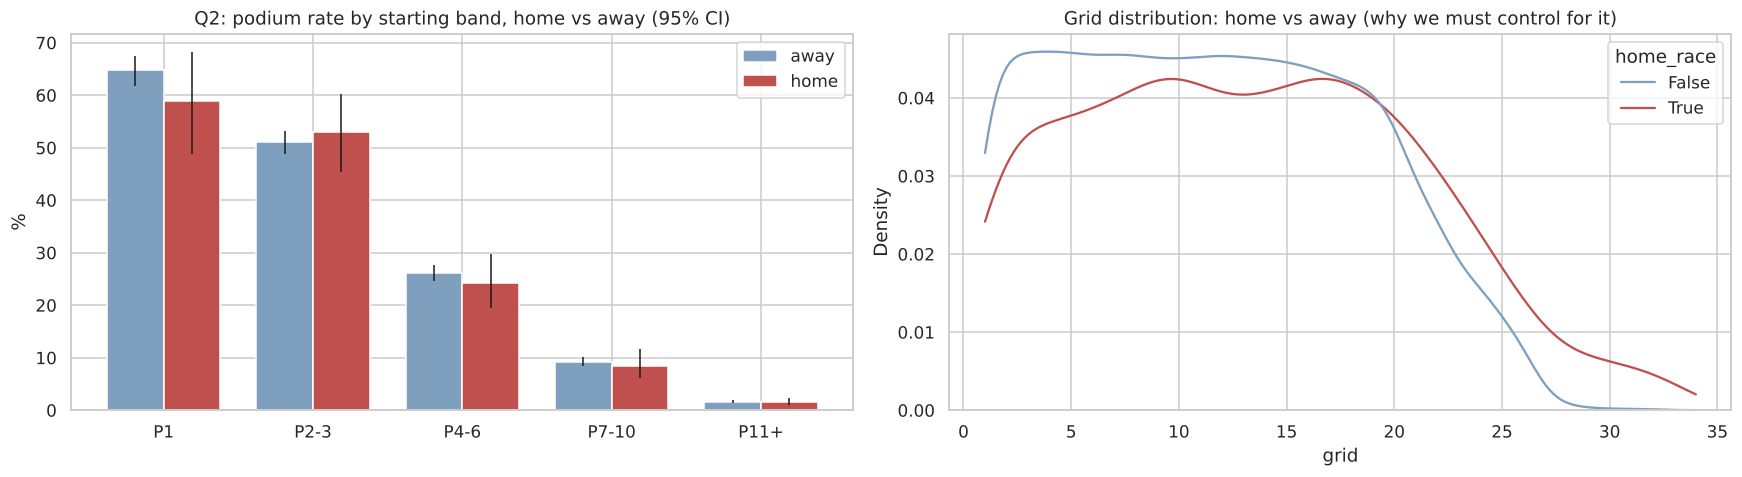

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
w = .38
bands = strat.grid_band.cat.categories
for i, (h, col, lab) in enumerate([(False, '#7f9fbf', 'away'), (True, '#c0504d', 'home')]):
    d = strat[strat.home_race == h].set_index('grid_band').reindex(bands)
    x = np.arange(len(bands)) + (i - .5) * w
    axes[0].bar(x, d.rate * 100, w, color=col, label=lab)
    axes[0].errorbar(x, d.rate * 100, yerr=ci_err(d.rate, d.lo, d.hi), fmt='none', c='k', lw=1)
axes[0].set_xticks(range(len(bands))); axes[0].set_xticklabels(bands); axes[0].legend()
axes[0].set_title('Q2: podium rate by starting band, home vs away (95% CI)'); axes[0].set_ylabel('%')
sns.kdeplot(data=q2, x='grid', hue='home_race', common_norm=False, ax=axes[1], clip=(1, 34), palette=['#7f9fbf', '#c0504d'])
axes[1].set_title('Grid distribution: home vs away (why we must control for it)')
savefig('q2_home_advantage')

**Q2 answer: no, there is no measurable home advantage once starting position is controlled for.**
* Raw comparison: home drivers podium *less* often (11.4% vs 13.8%), but they also start further back on average (grid 13.3 vs 11.7). Many home entries are local drivers in midfield or backmarker cars, especially in the 1950s–80s.
* Within the same grid band the rates are almost identical (e.g. P2–3: 52.9% home vs 51.0% away; P7–10: 8.5% vs 9.2%).
* Pooled over bands: CMH odds ratio **0.94 (p = 0.42)**. Logistic regression with grid band and decade: **OR = 0.92, 95% CI [0.78, 1.08]**. In the 2003–2024 modelling era: OR = 0.76, CI [0.51, 1.13]. Every interval contains 1.
* Conclusion: the apparent difference comes from *where home drivers start*, not from racing at home. For modelling, `home_race` is a weak candidate feature, kept only to test it in the ablation and importance analysis.
* Caveats: nationality ≠ home (residence, team base), and the home sample at the front of the grid is small (95 home pole-sitters), so a small effect cannot be excluded.

### Q3. Which constructors have the highest mechanical-retirement rate, 2014–2021 vs 2022–2024?
**Tables joined:** `results` ⨝ `status` (retirement reason) ⨝ `constructors` (name) ⨝ `races` (season).
**Definition:** a *mechanical retirement* is a **race start** whose status is a component failure (engine, gearbox, power unit, hydraulics, brakes, suspension, electrics, …). Excluded: crashes and collisions (`Accident`, `Collision`, `Collision damage`, `Spun off`, `Damage`, `Debris`), driver-related causes (`Physical`, `Illness`) and regulation decisions (`Disqualified`, `Excluded`, `Underweight`). The full list is the `MECHANICAL` set in 3.1.
**Denominator:** race starts, so rows with `Did not start`, `Withdrew` or `Did not qualify` are removed. Rate = mechanical retirements / starts, per constructor and era.
**Missingness / ambiguity:** the generic code `Retired` gives no cause. It is excluded from the main rate (it cannot be proven mechanical) and shown separately as an **upper bound** sensitivity analysis.

In [29]:
q3 = entries[(entries.year >= 2014) & entries.is_started].copy()
q3['era'] = np.where(q3.year <= 2021, '2014–2021', '2022–2024')
q3['mech'] = q3.is_mechanical
q3['retired_generic'] = q3.status.eq('Retired')
rates = (q3.groupby(['era', 'constructor']).agg(starts=('mech', 'size'), mech=('mech', 'sum'), generic=('retired_generic', 'sum'))
         .reset_index())
rates = rates[rates.starts >= 30].copy()
rates['mech_rate'] = rates.mech / rates.starts
rates['upper_bound_rate'] = (rates.mech + rates.generic) / rates.starts
rates['lo'], rates['hi'] = proportion_confint(rates.mech, rates.starts, method='wilson')
print('Overall mechanical-retirement rate per start:', q3.groupby('era').mech.mean().round(4).to_dict())
print('Share of starts ending with the uninformative "Retired" code:', q3.groupby('era').retired_generic.mean().round(4).to_dict())
for era in ['2014–2021', '2022–2024']:
    print(f'\n{era}: constructors ranked by mechanical-retirement rate (≥30 starts)')
    display(rates[rates.era == era].sort_values('mech_rate', ascending=False)[['constructor', 'starts', 'mech', 'mech_rate', 'lo', 'hi', 'upper_bound_rate']].round(3))
RESULTS['q3'] = {era: rates[rates.era == era].sort_values('mech_rate', ascending=False)[['constructor', 'starts', 'mech', 'mech_rate']]
                 .round(3).values.tolist() for era in ['2014–2021', '2022–2024']}
RESULTS['q3_overall'] = q3.groupby('era').mech.mean().round(4).to_dict()
top_causes = q3[q3.mech].groupby('era').status.value_counts().groupby(level=0).head(6)
display(top_causes.to_frame('count'))

Overall mechanical-retirement rate per start: {'2014–2021': 0.0958, '2022–2024': 0.0598}
Share of starts ending with the uninformative "Retired" code: {'2014–2021': 0.0117, '2022–2024': 0.0089}

2014–2021: constructors ranked by mechanical-retirement rate (≥30 starts)


,constructor,starts,mech,mech_rate,lo,hi,upper_bound_rate
4,Caterham,34,8,0.235,0.124,0.400,0.324
8,Lotus F1,75,13,0.173,0.104,0.274,0.213
17,Toro Rosso,242,39,0.161,0.120,0.213,0.178
11,McLaren,318,46,0.145,0.110,0.188,0.160
15,Renault,200,28,0.140,0.099,0.195,0.150
16,Sauber,200,22,0.110,0.074,0.161,0.130
14,Red Bull,319,34,0.107,0.077,0.145,0.113
1,AlphaTauri,78,8,0.103,0.053,0.190,0.115
10,Marussia,31,3,0.097,0.033,0.249,0.097
13,Racing Point,76,7,0.092,0.045,0.178,0.092



2022–2024: constructors ranked by mechanical-retirement rate (≥30 starts)


,constructor,starts,mech,mech_rate,lo,hi,upper_bound_rate
19,Alfa Romeo,88,11,0.125,0.071,0.210,0.125
21,Alpine F1 Team,136,15,0.110,0.068,0.174,0.110
20,AlphaTauri,88,7,0.080,0.039,0.155,0.080
23,Ferrari,136,9,0.066,0.035,0.121,0.081
30,Williams,134,8,0.060,0.031,0.113,0.082
22,Aston Martin,133,6,0.045,0.021,0.095,0.053
24,Haas F1 Team,135,6,0.044,0.021,0.094,0.044
26,Mercedes,136,6,0.044,0.020,0.093,0.044
27,RB F1 Team,48,2,0.042,0.012,0.140,0.104
25,McLaren,136,5,0.037,0.016,0.083,0.037


count
era       status           
2014–2021 Engine         59
          Brakes         45
          Power Unit     35
          Gearbox        33
          Suspension     24
          Electrical     13
2022–2024 Engine         22
          Gearbox         9
          Power Unit      7
          Hydraulics      5
          Undertray       4
          Brakes          4

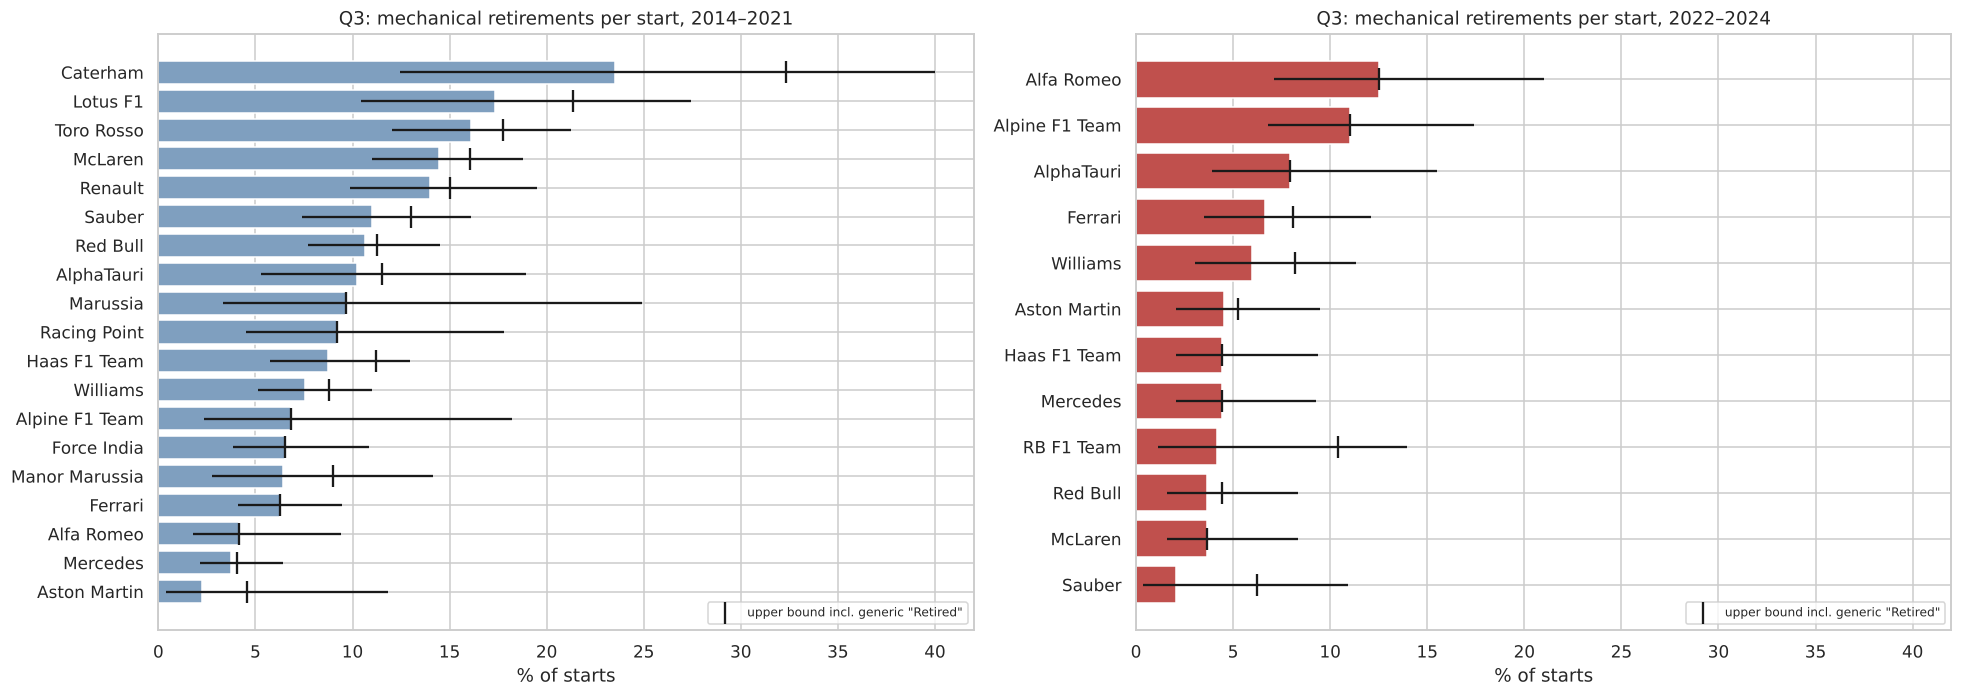

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), sharex=True)
for ax, era, col in zip(axes, ['2014–2021', '2022–2024'], ['#7f9fbf', '#c0504d']):
    d = rates[rates.era == era].sort_values('mech_rate')
    ax.barh(d.constructor, d.mech_rate * 100, color=col, xerr=ci_err(d.mech_rate, d.lo, d.hi), ecolor='k')
    ax.scatter(d.upper_bound_rate * 100, d.constructor, marker='|', s=200, c='k', label='upper bound incl. generic "Retired"')
    ax.set_title(f'Q3: mechanical retirements per start, {era}'); ax.set_xlabel('% of starts'); ax.legend(loc='lower right', fontsize=8)
savefig('q3_mechanical_retirements')

**Q3 answer.**
* **Reliability improved:** mechanical retirements fell from **9.6% of starts (2014–2021)** to **6.0% (2022–2024)**.
* **2014–2021 (≥30 starts):** worst were **Caterham (23.5%)**, **Lotus F1 (17.3%)**, **Toro Rosso (16.1%)**, **McLaren (14.5%)** (the Honda power-unit years 2015–2017) and **Renault (14.0%)**. Best were Mercedes (3.8%) and Ferrari (6.2%). The top causes, *Engine*, *Power Unit*, *Gearbox* and *Brakes*, fit the immature early hybrid power units.
* **2022–2024:** worst were **Alfa Romeo (12.5%)**, **Alpine (11.0%)** and **AlphaTauri (8.0%)**. Red Bull and McLaren were the most reliable (3.7%). The ranking reshuffled: McLaren went from 4th-worst to among the best, while Alfa Romeo went from among the best (4.2%) to the worst.
* The generic `Retired` code (about 1% of starts) could only move a few teams (e.g. RB F1 Team 4.2% → 10.4% upper bound). The top of each ranking holds under that sensitivity check. Teams with 30–80 starts have wide intervals, so neighbouring ranks are not significantly different.
* Relevance for prediction: car reliability varies by team and era. This motivates a leakage-safe **constructor recent-DNF-rate** feature computed from *past* races only.

## 5. Feature engineering (leakage-safe)
### 5.1 The prediction cutoff decides what is allowed
A prediction is made **after qualifying and before lights out**. Each candidate column is classified below. Anything produced by the race itself, including the post-race standings of *this* race, is leakage and is forbidden.

In [31]:
leakage_audit = pd.DataFrame([
    ('results.positionOrder / position / positionText', 'race outcome', 'TARGET only (never a feature)'),
    ('results.points, laps, time, milliseconds, statusId', 'race outcome', 'forbidden (current race); allowed only from PAST races'),
    ('results.fastestLap, rank, fastestLapTime, fastestLapSpeed', 'race outcome', 'forbidden'),
    ('pit_stops.*, lap_times.*', 'happen during the race', 'forbidden'),
    ('driver_standings / constructor_standings of raceId', 'computed AFTER the race', 'forbidden; use standings of the PREVIOUS round'),
    ('constructor_results of raceId', 'race outcome', 'forbidden'),
    ('sprint_results (same weekend)', 'Saturday sprint (often after quali)', 'not used (only 2021+, would create era-specific missingness)'),
    ('results.grid', 'starting grid after penalties, published before the start', 'allowed'),
    ('qualifying.position, q1/q2/q3', 'qualifying session', 'allowed'),
    ('drivers.dob, nationality; circuits.country', 'static', 'allowed'),
    ('history of results/standings before this race', 'past', 'allowed (shifted by one race)'),
], columns=['source', 'when it is known', 'decision'])
leakage_audit

,source,when it is known,decision
0,results.positionOrder / position / positionText,race outcome,TARGET only (never a feature)
1,"results.points, laps, time, milliseconds, stat...",race outcome,forbidden (current race); allowed only from PA...
2,"results.fastestLap, rank, fastestLapTime, fast...",race outcome,forbidden
3,"pit_stops.*, lap_times.*",happen during the race,forbidden
4,driver_standings / constructor_standings of ra...,computed AFTER the race,forbidden; use standings of the PREVIOUS round
5,constructor_results of raceId,race outcome,forbidden
6,sprint_results (same weekend),Saturday sprint (often after quali),"not used (only 2021+, would create era-specifi..."
7,results.grid,"starting grid after penalties, published befor...",allowed
8,"qualifying.position, q1/q2/q3",qualifying session,allowed
9,"drivers.dob, nationality; circuits.country",static,allowed


### 5.2 Feature construction
Every history-based feature is computed on data sorted by race date and **shifted by one race** (`shift(1)` before any rolling or expanding window). A row therefore only sees races strictly before it. Standings are taken from the **previous round** of the same season. The function is written once and re-used by the leakage test in 5.3.

| group | features | idea |
|---|---|---|
| grid | `grid_pos`, `pitlane_start` | actual starting slot (grid 0 → back of field + flag) |
| qualifying | `quali_pos`, `quali_gap_pct`, `grid_penalty`, `teammate_quali_diff` | raw pace and penalties (Q1 finding) |
| standings | `drv_pts_share`, `drv_champ_pos`, `drv_season_wins`, `con_pts_share`, `con_champ_pos`, `prev_season_drv_pos`, `prev_season_con_pos`, `first_round` | season-level strength *before* this race; points normalised by the leader so 10-point and 25-point eras are comparable |
| driver_form | `drv_podium_rate_5`, `drv_avg_finish_5`, `drv_dnf_rate_5`, `drv_avg_grid_5` | last 5 races of the driver |
| constructor_form | `con_podium_rate_5`, `con_best_finish_5`, `con_mech_dnf_rate_10` | car competitiveness and reliability (Q3 finding) |
| experience | `drv_prior_starts`, `drv_career_podium_rate`, `drv_circuit_starts`, `drv_circuit_podium_rate`, `driver_age` | career and track-specific history |
| context | `home_race`, `field_size` | Q2 finding, size of the field |

In [32]:
%%writefile f1podium/features.py
"""Leakage-safe feature builder. Every history feature is shifted by one race; standings come from the previous round."""
import numpy as np
import pandas as pd


def build_features(ent, ds, cs, races):
    """ent: output of entries.build_entries; ds/cs: driver/constructor standings; races: clean races table.
    Returns one row per (raceId, driverId) for all seasons with all FEATURES (pre-race information only)."""
    df = ent.copy().sort_values(['date', 'raceId']).reset_index(drop=True)
    df['positionOrder_f'] = df.positionOrder.astype(float)
    # ---- context / grid -------------------------------------------------------------
    df['field_size'] = df.groupby('raceId').driverId.transform('size')
    df['pitlane_start'] = (df.grid.fillna(0) <= 0).astype(int)
    df['grid_pos'] = df.grid.where(df.grid > 0, df.field_size).astype(float)
    df['home_race'] = df.home_race.astype(int)
    df['driver_age'] = (df.date - df.dob).dt.days / 365.25
    # ---- qualifying -----------------------------------------------------------------
    df['quali_pos'] = df.quali_pos.astype(float)
    best = df[['q1_s', 'q2_s', 'q3_s']].min(axis=1)
    df['quali_gap_pct'] = (best / best.groupby(df.raceId).transform('min') - 1) * 100
    df['grid_penalty'] = df.grid_pos - df.quali_pos
    grp = df.groupby(['raceId', 'constructorId']).quali_pos
    mate_mean = (grp.transform('sum') - df.quali_pos) / (grp.transform('count') - 1)
    df['teammate_quali_diff'] = df.quali_pos - mate_mean.replace([np.inf, -np.inf], np.nan)
    # ---- standings BEFORE the race (= after the previous round) -------------------
    rr = races[['raceId', 'year', 'round']].sort_values(['year', 'round']).copy()
    rr['prev_raceId'] = rr.groupby('year').raceId.shift(1)
    df = df.merge(rr[['raceId', 'prev_raceId']], on='raceId', how='left')
    d_ = ds[['raceId', 'driverId', 'points', 'position', 'wins']].copy()
    d_['leader'] = d_.groupby('raceId').points.transform('max')
    d_ = d_.rename(columns={'raceId': 'prev_raceId', 'points': 'drv_pts', 'position': 'drv_champ_pos', 'wins': 'drv_season_wins', 'leader': 'drv_leader'})
    c_ = cs[['raceId', 'constructorId', 'points', 'position']].copy()
    c_['leader'] = c_.groupby('raceId').points.transform('max')
    c_ = c_.rename(columns={'raceId': 'prev_raceId', 'points': 'con_pts', 'position': 'con_champ_pos', 'leader': 'con_leader'})
    df = df.merge(d_, on=['prev_raceId', 'driverId'], how='left').merge(c_, on=['prev_raceId', 'constructorId'], how='left')
    df['first_round'] = df.prev_raceId.isna().astype(int)
    df['drv_pts_share'] = (df.drv_pts / df.drv_leader.replace(0, np.nan)).fillna(0)
    df['con_pts_share'] = (df.con_pts / df.con_leader.replace(0, np.nan)).fillna(0)
    df['drv_season_wins'] = df.drv_season_wins.fillna(0)
    df['drv_champ_pos'] = df.drv_champ_pos.astype(float)
    df['con_champ_pos'] = df.con_champ_pos.astype(float)
    # final standings of the previous season
    last = rr.groupby('year').raceId.last().reset_index().rename(columns={'raceId': 'last_raceId'})
    fd = ds.merge(last, left_on='raceId', right_on='last_raceId')[['year', 'driverId', 'position']]
    fd = fd.assign(year=fd.year + 1).rename(columns={'position': 'prev_season_drv_pos'})
    fc = cs.merge(last, left_on='raceId', right_on='last_raceId')[['year', 'constructorId', 'position']]
    fc = fc.assign(year=fc.year + 1).rename(columns={'position': 'prev_season_con_pos'})
    df = df.merge(fd, on=['year', 'driverId'], how='left').merge(fc, on=['year', 'constructorId'], how='left')
    df[['prev_season_drv_pos', 'prev_season_con_pos']] = df[['prev_season_drv_pos', 'prev_season_con_pos']].astype(float)
    df = df.sort_values(['date', 'raceId']).reset_index(drop=True)
    # ---- driver form & experience (past races only) --------------------------------
    df['dnf'] = (~df.is_finished).astype(int)
    df['mech_dnf'] = df.is_mechanical.astype(int)
    gd = df.groupby('driverId')
    past_mean = lambda col, w: gd[col].transform(lambda s: s.shift(1).rolling(w, min_periods=1).mean())
    df['drv_podium_rate_5'] = past_mean('podium', 5)
    df['drv_avg_finish_5'] = past_mean('positionOrder_f', 5)
    df['drv_dnf_rate_5'] = past_mean('dnf', 5)
    df['drv_avg_grid_5'] = past_mean('grid_pos', 5)
    df['drv_prior_starts'] = gd.cumcount()
    df['drv_career_podium_rate'] = gd['podium'].transform(lambda s: s.shift(1).expanding().mean())
    gdc = df.groupby(['driverId', 'circuitId'])
    df['drv_circuit_starts'] = gdc.cumcount()
    df['drv_circuit_podium_rate'] = gdc['podium'].transform(lambda s: s.shift(1).expanding().mean())
    # ---- constructor form (aggregate per race first, so the team-mate's CURRENT result never leaks) ----
    cr = (df.groupby(['raceId', 'constructorId'], as_index=False)
            .agg(date=('date', 'first'), c_pod=('podium', 'sum'), c_n=('podium', 'size'),
                 c_mech=('mech_dnf', 'sum'), c_best=('positionOrder_f', 'min'))
            .sort_values(['date', 'raceId']))
    gc = cr.groupby('constructorId')
    past_sum = lambda col, w: gc[col].transform(lambda s: s.shift(1).rolling(w, min_periods=1).sum())
    cr['con_podium_rate_5'] = past_sum('c_pod', 5) / past_sum('c_n', 5)
    cr['con_mech_dnf_rate_10'] = past_sum('c_mech', 10) / past_sum('c_n', 10)
    cr['con_best_finish_5'] = gc['c_best'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    df = df.merge(cr[['raceId', 'constructorId', 'con_podium_rate_5', 'con_mech_dnf_rate_10', 'con_best_finish_5']],
                  on=['raceId', 'constructorId'], how='left')
    return df.sort_values(['date', 'raceId', 'grid_pos']).reset_index(drop=True)

FEATURE_GROUPS = {
    'grid': ['grid_pos', 'pitlane_start'],
    'qualifying': ['quali_pos', 'quali_gap_pct', 'grid_penalty', 'teammate_quali_diff'],
    'standings': ['drv_pts_share', 'drv_champ_pos', 'drv_season_wins', 'con_pts_share', 'con_champ_pos',
                  'prev_season_drv_pos', 'prev_season_con_pos', 'first_round'],
    'driver_form': ['drv_podium_rate_5', 'drv_avg_finish_5', 'drv_dnf_rate_5', 'drv_avg_grid_5'],
    'constructor_form': ['con_podium_rate_5', 'con_best_finish_5', 'con_mech_dnf_rate_10'],
    'experience': ['drv_prior_starts', 'drv_career_podium_rate', 'drv_circuit_starts', 'drv_circuit_podium_rate', 'driver_age'],
    'context': ['home_race', 'field_size'],
}
FEATURES = [f for g in FEATURE_GROUPS.values() for f in g]
META = ['raceId', 'driverId', 'constructorId', 'year', 'round', 'date', 'name', 'driverRef', 'constructor', 'grid', 'positionOrder']
TARGET = 'podium'

Writing f1podium/features.py


In [33]:
import f1podium.features as ff; importlib.reload(ff)
from f1podium.features import build_features, FEATURE_GROUPS, FEATURES, META, TARGET

t0 = time.time()
feat_all = build_features(entries, clean['driver_standings'], clean['constructor_standings'], clean['races'])
print(f'feature table (all seasons): {feat_all.shape}, built in {time.time() - t0:.1f}s; {len(FEATURES)} features')
assert not feat_all.duplicated(['raceId', 'driverId']).any()

feature table (all seasons): (26668, 78), built in 4.5s; 28 features


### 5.3 Leakage tests
Two automated checks:
1. **Perturbation test.** Pick a test-period race, scramble its outcome (finishing order, status, podium flags) and delete its post-race standings. Rebuild the features. The features of *that* race must be identical, while the next race of an affected driver must change (proving the test can detect dependence).
2. **Correlation check.** No feature should be a near-copy of the target.

In [34]:
def scramble(ent, ds, cs, race_id, seed=0):
    rng = np.random.default_rng(seed)
    e = ent.copy(); m = e.raceId == race_id
    perm = rng.permutation(m.sum())
    e.loc[m, 'positionOrder'] = e.loc[m, 'positionOrder'].values[perm]
    e.loc[m, 'podium'] = (e.loc[m, 'positionOrder'] <= 3).astype(int)
    e.loc[m, 'is_finished'] = e.loc[m, 'is_finished'].values[rng.permutation(m.sum())]
    e.loc[m, 'is_mechanical'] = ~e.loc[m, 'is_mechanical'].values
    return e, ds[ds.raceId != race_id], cs[cs.raceId != race_id]

test_race = int(entries[(entries.year == 2022) & (entries['round'] == 10)].raceId.iloc[0])
e2, ds2, cs2 = scramble(entries, clean['driver_standings'], clean['constructor_standings'], test_race)
feat_pert = build_features(e2, ds2, cs2, clean['races'])
a = feat_all[feat_all.raceId == test_race].set_index('driverId')[FEATURES].sort_index()
b = feat_pert[feat_pert.raceId == test_race].set_index('driverId')[FEATURES].sort_index()
same_race_equal = np.allclose(a.values.astype(float), b.values.astype(float), equal_nan=True)
nxt = clean['races'].sort_values('date'); nxt_id = int(nxt[nxt.date > nxt.loc[nxt.raceId == test_race, 'date'].iloc[0]].raceId.iloc[0])
a2 = feat_all[feat_all.raceId == nxt_id].set_index('driverId')[FEATURES].sort_index()
b2 = feat_pert[feat_pert.raceId == nxt_id].set_index('driverId')[FEATURES].sort_index()
next_race_changed = not np.allclose(a2.values.astype(float), b2.values.astype(float), equal_nan=True)
print(f'Scrambled race {test_race}: its own features unchanged -> {same_race_equal}; next race features changed -> {next_race_changed}')
assert same_race_equal and next_race_changed, 'LEAKAGE TEST FAILED'
corr_t = feat_all[feat_all.year >= 2003][FEATURES + [TARGET]].corr(method='spearman')[TARGET].drop(TARGET).abs().sort_values(ascending=False)
print('Highest |Spearman| with target:', corr_t.head(3).round(3).to_dict())
assert corr_t.max() < 0.9
RESULTS['leakage_test'] = dict(race=test_race, unchanged=bool(same_race_equal), next_changed=bool(next_race_changed))

Scrambled race 1083: its own features unchanged -> True; next race features changed -> True


Highest |Spearman| with target: {'drv_podium_rate_5': 0.522, 'con_podium_rate_5': 0.513, 'quali_pos': 0.501}


Both tests pass. Changing everything that happened in a race does not change a single feature of that race, so the features use only pre-race information. The same change does flow into the *next* race's form and standings features, as it should. No feature is a proxy for the target.

> **Key takeaway:** the features use only information available before the race. This is proven by an automated test, not just claimed.

### 5.4 Modelling window
Qualifying data is complete only from **2003** (Section 1.2). Before that, qualifying features would be missing for 40–95% of rows *because of how the data was collected*, not because of anything about the driver. We therefore model **2003–2024**: 22 seasons and about 9,000 driver-races. Earlier seasons are still used *as history* for the form and experience features of 2003+ rows. Section 9.3 compares this window with 1994–2024 empirically.

In [35]:
MODEL_START = 2003
df_model = feat_all[feat_all.year.between(MODEL_START, LAST_SEASON)].reset_index(drop=True)
print('modelling table:', df_model.shape, '| unique (raceId, driverId):', not df_model.duplicated(['raceId', 'driverId']).any())
print(f'podium rate: {df_model[TARGET].mean():.3f}')
miss = df_model[FEATURES].isna().mean().mul(100).round(2)
display(miss[miss > 0].sort_values(ascending=False).to_frame('% missing'))
df_model[META + FEATURES + [TARGET]].to_csv(os.path.join(OUT_DIR, 'modelling_table.csv'), index=False)
RESULTS['model_table'] = dict(rows=len(df_model), features=len(FEATURES), podium_rate=float(df_model[TARGET].mean()))

modelling table: (8970, 78) | unique (raceId, driverId): True
podium rate: 0.143


,% missing
drv_circuit_podium_rate,22.40
prev_season_drv_pos,18.18
prev_season_con_pos,11.75
drv_champ_pos,6.76
con_champ_pos,5.51
quali_gap_pct,1.65
drv_career_podium_rate,0.99
drv_avg_finish_5,0.99
drv_podium_rate_5,0.99
drv_avg_grid_5,0.99


Remaining missingness is **structural** and meaningful. `drv_champ_pos` / `con_champ_pos` are empty in round 1 or for a driver's first race of the season. `prev_season_*` is empty for rookies and new constructor IDs. `drv_circuit_podium_rate` is empty on a driver's first visit to a circuit. `teammate_quali_diff` is empty when the team-mate has no qualifying time. The imputer in Section 7 therefore adds **missing-indicator** columns, so "no history" stays visible as information instead of being disguised as an average value.

## 6. Train / validation / test split
**Choice: a temporal split by season.** Train = 2003–2016, Validation = 2017–2020, Test = 2021–2024 (unseen).

Why not a random split?
* Rows of the same race are dependent: exactly three podiums per race, and team-mates share a car. A random split puts drivers of the same race on both sides.
* Form and standings features carry information from neighbouring races. With a random split, the model would be trained on races *after* the ones it is tested on, which is a subtle form of future leakage.
* The real use case is predicting **future** races, so a forward-in-time split measures exactly that, including drift from regulation changes. The test period contains the 2022 ground-effect regulations, which are new to the model, so it is a deliberately hard and honest test.

The validation seasons are used for model selection, hyper-parameters and the probability threshold. The test seasons are touched **once**, for final reporting.

> **Key takeaway:** train 5,591 rows · validation 1,580 · test 1,799. The podium rate is about 14–15% in every split, so the splits are comparable.

,seasons,races,rows,podium_rate
split,,,,
train,2003–2016,259,5591,0.139
val,2017–2020,79,1580,0.150
test,2021–2024,90,1799,0.150


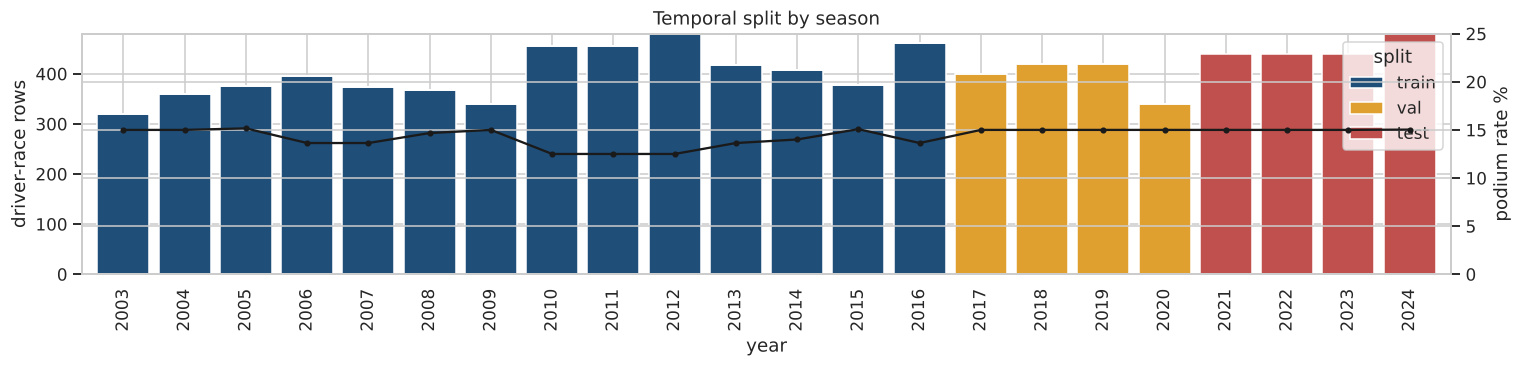

In [36]:
TRAIN_YEARS, VAL_YEARS, TEST_YEARS = (2003, 2016), (2017, 2020), (2021, 2024)
split = np.select([df_model.year.between(*TRAIN_YEARS), df_model.year.between(*VAL_YEARS), df_model.year.between(*TEST_YEARS)],
                  ['train', 'val', 'test'], default='other')
df_model['split'] = split
tr, va, te = (df_model[df_model.split == s].reset_index(drop=True) for s in ['train', 'val', 'test'])
X_tr, y_tr = tr[FEATURES], tr[TARGET].values
X_va, y_va = va[FEATURES], va[TARGET].values
X_te, y_te = te[FEATURES], te[TARGET].values
split_tab = df_model.groupby('split').agg(seasons=('year', lambda s: f'{s.min()}–{s.max()}'), races=('raceId', 'nunique'),
                                          rows=(TARGET, 'size'), podium_rate=(TARGET, 'mean')).loc[['train', 'val', 'test']]
display(split_tab.round(3))
RESULTS['split'] = split_tab.round(4).reset_index().to_dict(orient='records')

fig, ax = plt.subplots(figsize=(14, 3.5))
yr = df_model.groupby(['year', 'split']).size().unstack().reindex(columns=['train', 'val', 'test'])
yr.plot(kind='bar', stacked=True, ax=ax, color=['#1f4e79', '#e0a030', '#c0504d'], width=.85)
ax2 = ax.twinx(); df_model.groupby('year')[TARGET].mean().mul(100).reset_index(drop=True).plot(ax=ax2, color='k', marker='o', ms=3)
ax2.set_ylabel('podium rate %'); ax2.set_ylim(0, 25); ax.set_ylabel('driver-race rows'); ax.set_title('Temporal split by season')
savefig('split')

### 6.1 Feature selection evidence (computed on the TRAINING split only)
Each feature group was proposed from an EDA hypothesis (grid structure in 3; penalties in Q1; reliability in Q3; home effect in Q2). Here we check each feature against the target, **using training data only**, with three kinds of evidence:
* the univariate ROC-AUC of the raw feature (orientation-free: max(AUC, 1−AUC));
* mutual information with the podium label;
* podium rate across feature bins (plots).

,feature,group,univariate AUC,direction,missing %,mutual information
0,quali_pos,qualifying,0.907,−,0.340,0.161
1,grid_pos,grid,0.904,−,0.000,0.165
2,quali_gap_pct,qualifying,0.886,−,1.878,0.138
3,drv_champ_pos,standings,0.886,−,7.673,0.130
4,con_best_finish_5,constructor_form,0.879,−,0.608,0.123
5,drv_avg_grid_5,driver_form,0.872,−,1.180,0.133
6,con_podium_rate_5,constructor_form,0.865,+,0.608,0.122
7,drv_avg_finish_5,driver_form,0.855,−,1.180,0.117
8,con_champ_pos,standings,0.855,−,5.974,0.114
9,con_pts_share,standings,0.852,+,0.000,0.123


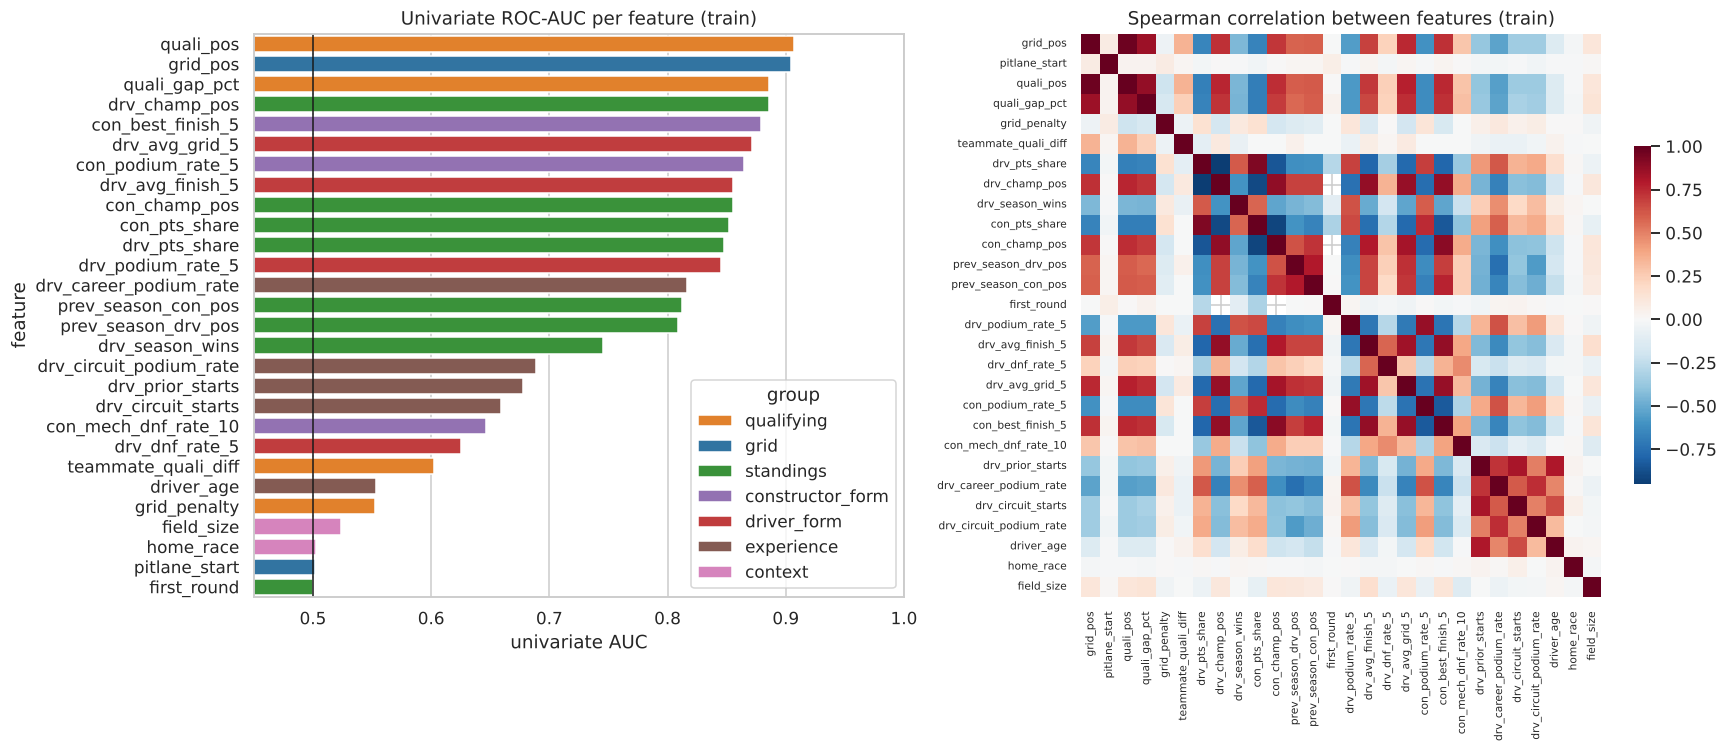

In [37]:
ev = []
for f in FEATURES:
    x = X_tr[f]; m = x.notna()
    auc = roc_auc_score(y_tr[m], x[m]) if x[m].nunique() > 1 else np.nan
    ev.append({'feature': f, 'group': next(g for g, fs in FEATURE_GROUPS.items() if f in fs),
               'univariate AUC': max(auc, 1 - auc), 'direction': '+' if auc >= .5 else '−', 'missing %': (~m).mean() * 100})
mi = mutual_info_classif(SimpleImputer(strategy='median').fit_transform(X_tr), y_tr, random_state=SEED)
evidence = pd.DataFrame(ev); evidence['mutual information'] = mi
evidence = evidence.sort_values('univariate AUC', ascending=False).reset_index(drop=True)
display(evidence.round(3))
evidence.to_csv(os.path.join(OUT_DIR, 'feature_evidence.csv'), index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
pal = dict(zip(FEATURE_GROUPS, sns.color_palette('tab10', len(FEATURE_GROUPS))))
sns.barplot(data=evidence, y='feature', x='univariate AUC', hue='group', dodge=False, palette=pal, ax=axes[0])
axes[0].axvline(.5, c='k', lw=1); axes[0].set_xlim(.45, 1); axes[0].set_title('Univariate ROC-AUC per feature (train)')
cm = X_tr.corr(method='spearman')
sns.heatmap(cm, cmap='RdBu_r', center=0, ax=axes[1], cbar_kws={'shrink': .6}, xticklabels=True, yticklabels=True)
axes[1].set_title('Spearman correlation between features (train)'); axes[1].tick_params(labelsize=7)
savefig('feature_evidence')

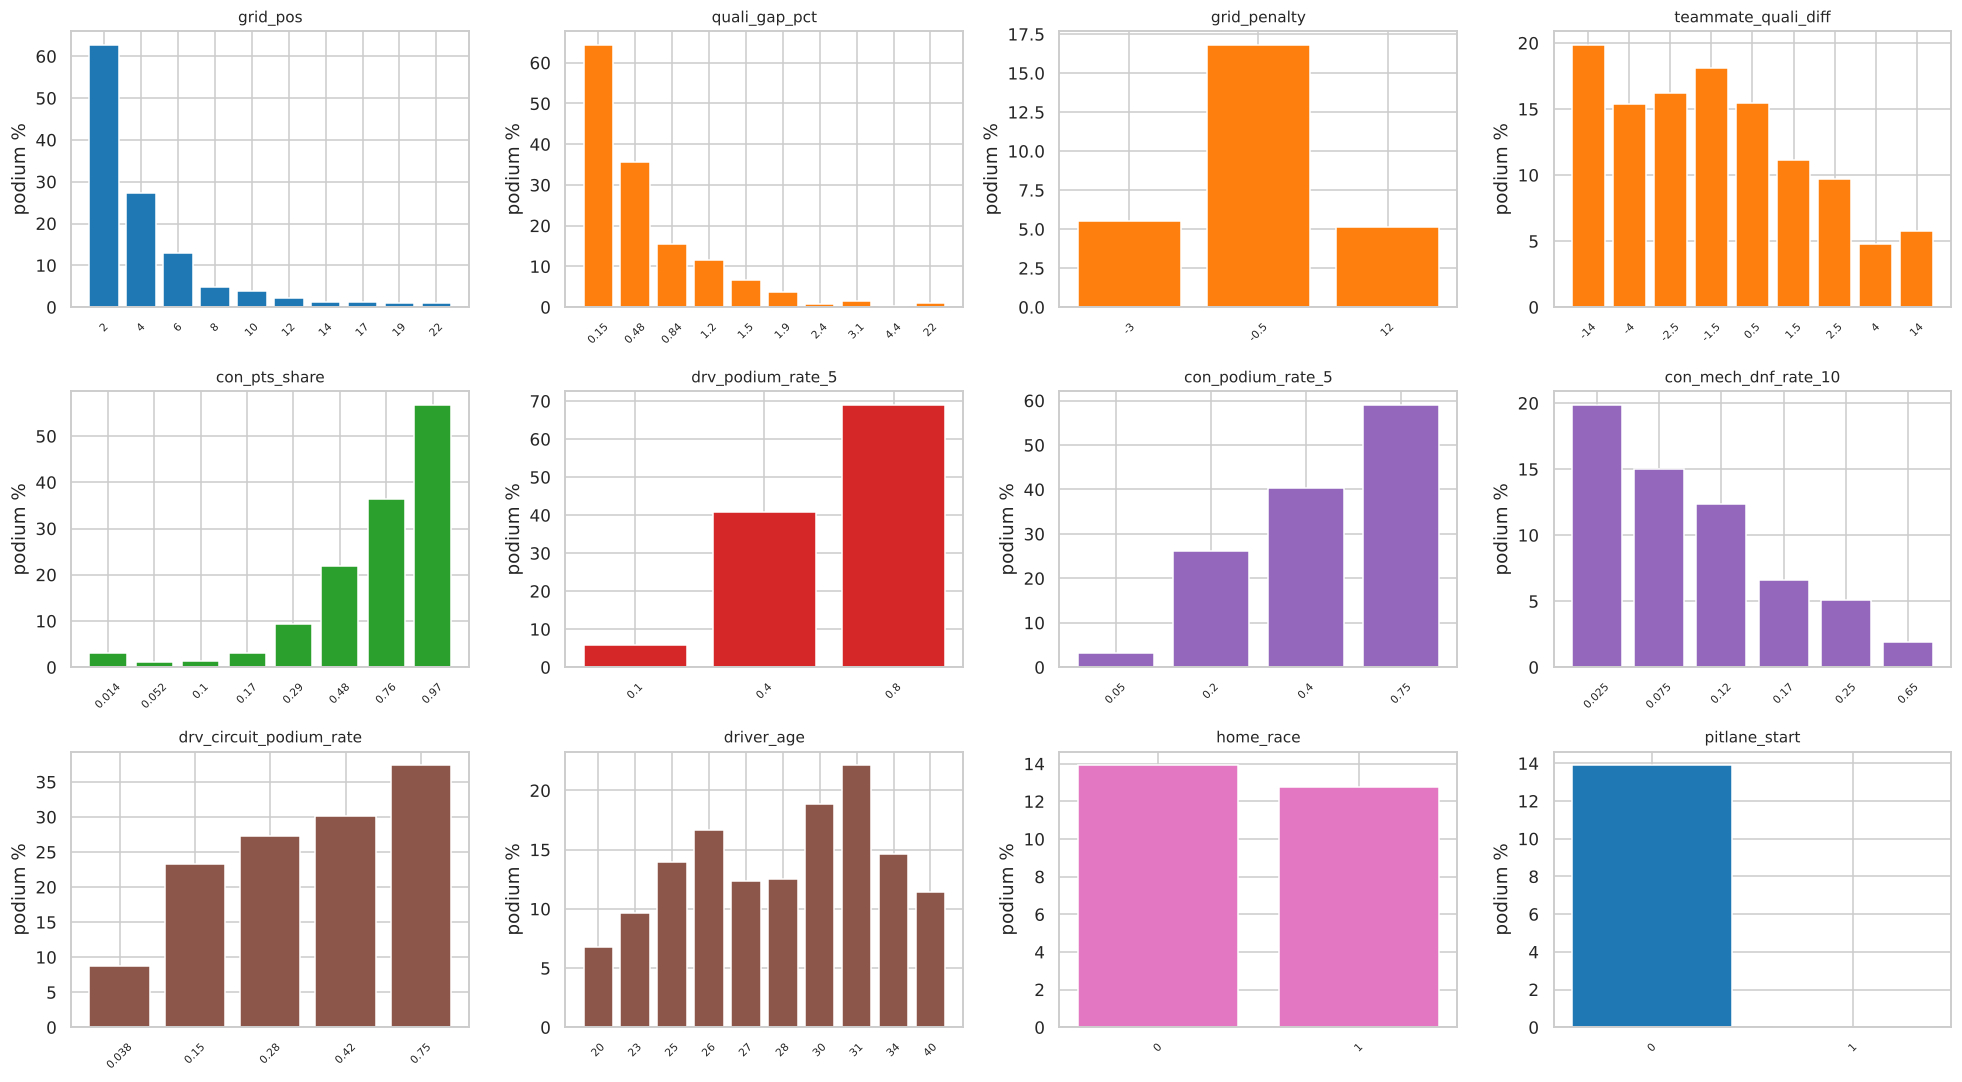

In [38]:
show = ['grid_pos', 'quali_gap_pct', 'grid_penalty', 'teammate_quali_diff', 'con_pts_share', 'drv_podium_rate_5',
        'con_podium_rate_5', 'con_mech_dnf_rate_10', 'drv_circuit_podium_rate', 'driver_age', 'home_race', 'pitlane_start']
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, f in zip(axes.ravel(), show):
    d = tr[[f, TARGET]].dropna()
    if d[f].nunique() <= 6:
        r = d.groupby(f)[TARGET].agg(['mean', 'count'])
    else:
        bins = pd.qcut(d[f], 10, duplicates='drop')
        r = d.groupby(bins, observed=True)[TARGET].agg(['mean', 'count'])
        r.index = [f'{iv.mid:.2g}' for iv in r.index]
    ax.bar(range(len(r)), r['mean'] * 100, color=pal[next(g for g, fs in FEATURE_GROUPS.items() if f in fs)])
    ax.set_xticks(range(len(r))); ax.set_xticklabels(r.index, rotation=45, fontsize=7)
    ax.set_title(f, fontsize=10); ax.set_ylabel('podium %')
savefig('feature_bins')

**Feature-selection decisions (with the evidence above).**
* **Grid & qualifying** are the strongest single predictors (univariate AUC above 0.9 for `grid_pos`, `quali_pos` and `quali_gap_pct`). Podium probability falls monotonically by bin. They are strongly correlated with each other (Spearman ≈ 0.9), but `grid_penalty` and `quali_gap_pct` carry *different* information: the penalty effect from Q1, and the margin, which a rank hides. They are kept, and models with regularisation or trees can handle the redundancy.
* **Standings and constructor form** (points share, recent constructor podium rate) are nearly as strong. They encode car strength, which in F1 dominates driver skill. The bins show sharp jumps at the top teams.
* **Driver form and experience** add moderate signal (AUC around 0.7–0.85). `drv_circuit_podium_rate` is a track-specific prior.
* **Constructor reliability** (`con_mech_dnf_rate_10`, motivated by Q3) and **driver age** are weak but monotone-ish. We keep them and let the ablation test decide.
* **`home_race`** has practically no univariate signal, which is consistent with Q2. **`field_size`**, **`pitlane_start`** (only about 0.3% of rows) and **`first_round`** (a flag that only matters in combination with the zeroed standings) are weak on their own too. Both are kept *on purpose* as candidate features so the ablation and permutation importance can confirm or reject them after training. They are cheap, leakage-free and documented.
* No feature was removed before training. Instead, removal is decided **empirically** in Section 9 (ablation and a k-best selection trial), so that no decision rests on univariate statistics alone.

> **Key takeaway:** grid and qualifying (AUC about 0.90), standings and constructor form (about 0.85) are strong. Driver form and experience are moderate. Home race and field size are weak and are kept only so Section 9 can test them.

## 7. Preprocessing and its effect on the data
The pipeline is fitted on the **training split only**:
1. **Winsorising** (`quali_gap_pct`, `teammate_quali_diff`, `grid_penalty`) at the 1st and 99th training percentiles. Wet sessions and missing laps create extreme gaps (Section 3) that would dominate a linear model or a neural network.
2. **Median imputation + missing indicators.** Medians are robust to the skew, and the indicators keep "no history / no team-mate time" visible.
3. **Standardisation** (z-scores) for the logistic regression and the neural network, which are scale-sensitive. Tree models skip this step because they are invariant to monotone transformations.

In [39]:
%%writefile f1podium/preprocessing.py
"""Preprocessing pipelines (always fitted on the training split only)."""
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.base import BaseEstimator, TransformerMixin

class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip selected columns to [q_low, q_high] quantiles learned on the training data."""
    def __init__(self, columns=None, q=(0.01, 0.99)):
        self.columns, self.q = columns, q
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.bounds_ = {c: X[c].quantile(list(self.q)).values for c in (self.columns or []) if c in X.columns}
        return self
    def transform(self, X):
        X = pd.DataFrame(X).copy()
        for c, (lo, hi) in self.bounds_.items():
            X[c] = X[c].clip(lo, hi)
        return X

WINSOR_COLS = ['quali_gap_pct', 'teammate_quali_diff', 'grid_penalty']

def make_prep(scale=True):
    steps = [('winsor', Winsorizer(WINSOR_COLS)), ('impute', SimpleImputer(strategy='median', add_indicator=True))]
    if scale:
        steps.append(('scale', StandardScaler()))
    return Pipeline(steps)

Writing f1podium/preprocessing.py


28 raw features -> 45 model inputs (17 missing indicators)


,raw min,raw max,raw missing %,after mean,after std,after min,after max,after missing %
grid_pos,1.0,24.0,0.00,0.0,1.0,-1.64,2.00,0.0
pitlane_start,0.0,1.0,0.00,-0.0,1.0,-0.05,19.96,0.0
quali_pos,1.0,24.0,0.34,0.0,1.0,-1.64,2.01,0.0
quali_gap_pct,0.0,37.8,1.88,0.0,1.0,-1.04,4.96,0.0
grid_penalty,-5.0,23.0,0.34,0.0,1.0,-1.65,6.09,0.0
teammate_quali_diff,-23.0,23.0,0.66,-0.0,1.0,-2.86,2.86,0.0
drv_pts_share,0.0,1.0,0.00,0.0,1.0,-0.78,2.56,0.0
drv_champ_pos,1.0,27.0,7.67,-0.0,1.0,-1.65,2.46,0.0
drv_season_wins,0.0,13.0,0.00,0.0,1.0,-0.32,9.92,0.0
con_pts_share,0.0,1.0,0.00,0.0,1.0,-0.85,2.16,0.0


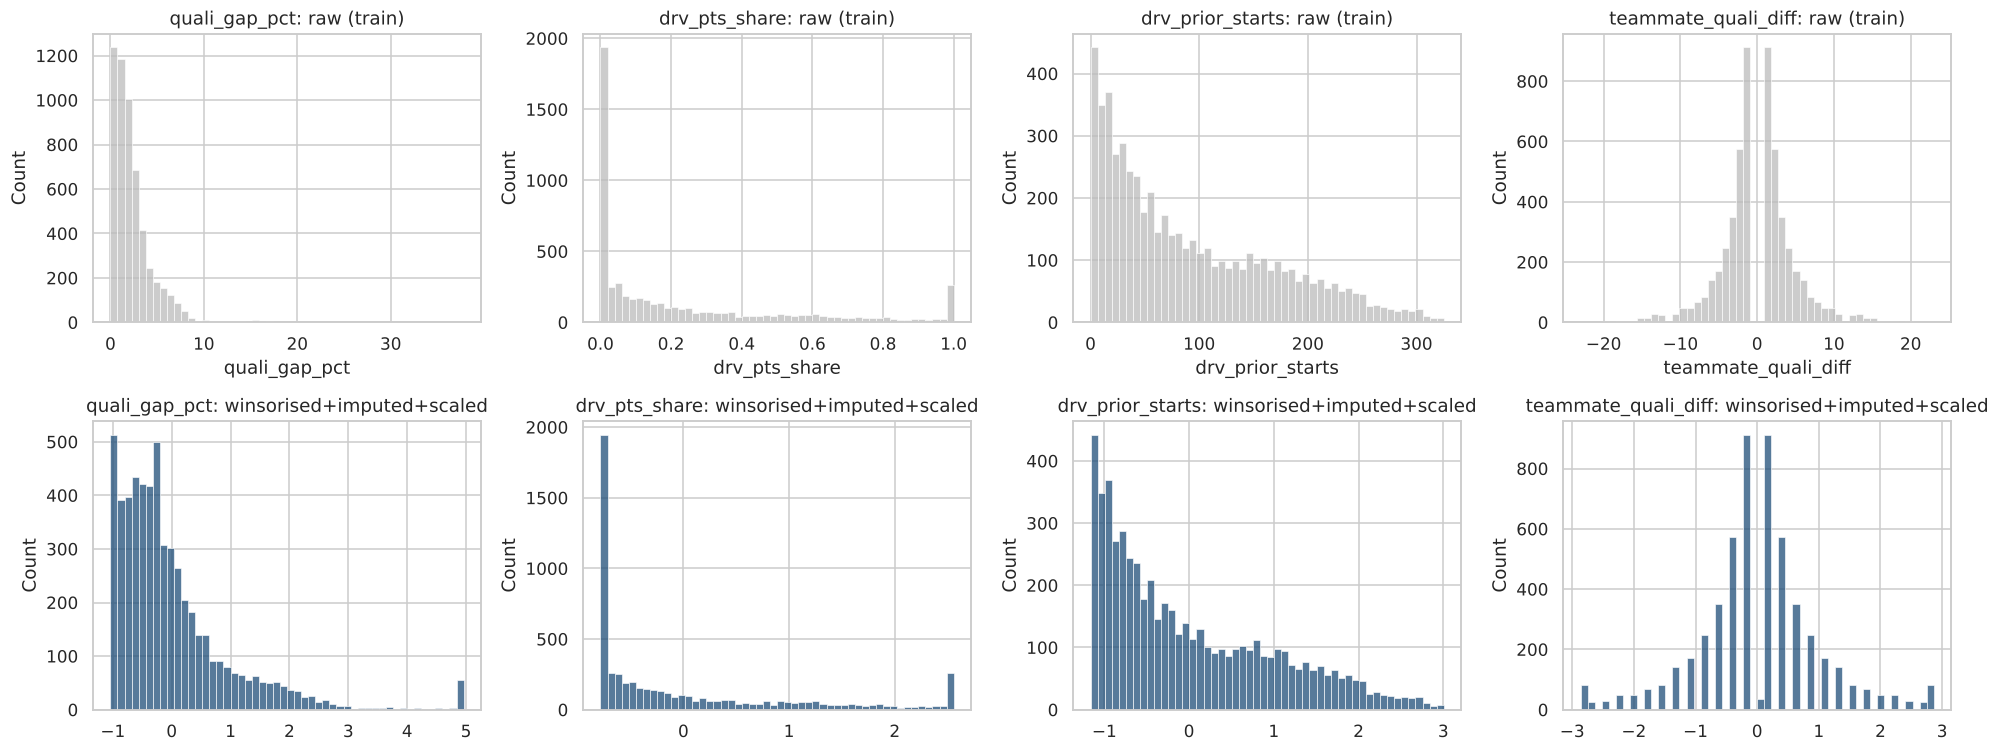

In [40]:
import f1podium.preprocessing as fp; importlib.reload(fp)
from f1podium.preprocessing import Winsorizer, WINSOR_COLS, make_prep

prep_demo = make_prep(scale=True).fit(X_tr)
Z_tr = prep_demo.transform(X_tr)
names_out = FEATURES + [f'missing_{FEATURES[i]}' for i in prep_demo.named_steps['impute'].indicator_.features_]
print(f'{X_tr.shape[1]} raw features -> {Z_tr.shape[1]} model inputs ({Z_tr.shape[1] - X_tr.shape[1]} missing indicators)')

before_after = pd.DataFrame({'raw min': X_tr.min(), 'raw max': X_tr.max(), 'raw missing %': X_tr.isna().mean() * 100,
                             'after mean': Z_tr[:, :len(FEATURES)].mean(0), 'after std': Z_tr[:, :len(FEATURES)].std(0),
                             'after min': Z_tr[:, :len(FEATURES)].min(0), 'after max': Z_tr[:, :len(FEATURES)].max(0),
                             'after missing %': np.isnan(Z_tr[:, :len(FEATURES)]).mean(0) * 100}).round(2)
display(before_after)

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for j, f in enumerate(['quali_gap_pct', 'drv_pts_share', 'drv_prior_starts', 'teammate_quali_diff']):
    sns.histplot(X_tr[f].dropna(), bins=50, ax=axes[0, j], color='#bbbbbb'); axes[0, j].set_title(f'{f}: raw (train)')
    sns.histplot(Z_tr[:, FEATURES.index(f)], bins=50, ax=axes[1, j], color='#1f4e79'); axes[1, j].set_title(f'{f}: winsorised+imputed+scaled')
savefig('preprocessing_effect')

**Effect of preprocessing.** After the pipeline, each feature has mean 0 and standard deviation 1 on the training data, and there are no missing values left. The heavy right tail of `quali_gap_pct` (values above 10% from wet or disrupted sessions) is cut at the 99th percentile, so it no longer stretches the scale. Missing values are replaced by the median **plus** a 0/1 indicator column (the spike at a single value in some histograms is the imputed median). The bimodal shape of `drv_pts_share` (many drivers with zero points) is kept: scaling changes units, not shape. Validation and test data are transformed with the training statistics only.

> **Key takeaway:** 28 features become 45 model inputs (28 scaled features + 17 missing-indicator flags), with no missing values left, all fitted on training data only.

## 8. Predictive modelling
### 8.1 Metrics, and the primary / secondary choice
Every model is scored with the same five metrics on train, validation and test:

| metric | what it tells us here |
|---|---|
| **PR-AUC** (average precision) | how well true podium finishers are ranked above the rest; insensitive to the large number of easy negatives |
| **ROC-AUC** | overall separation of the two classes |
| **F1** | balance of precision and recall at the chosen threshold |
| **Precision** | of the drivers we call "podium", how many make it |
| **Recall** | of the real podium finishers, how many we catch |

* **Primary metric: PR-AUC.** Podiums are only about 14–15% of rows. ROC-AUC looks very high almost automatically, because most backmarkers are trivially easy negatives. PR-AUC focuses on the hard part: ordering the ~6–8 realistic contenders of each race. It is threshold-free, so it is the fairest basis for model selection.
* **Secondary metric: F1 at a threshold chosen on validation.** A companion app has to make a yes/no call. F1 measures the quality of that call, and its threshold is chosen on **validation only** (the F1-maximising cut), never on test.
* Additional domain check (not used for selection): the **top-3 hit rate**. In each race, take the three drivers with the highest probability and count how many actually finished on the podium.

Every model gets **identical rows and identical input features**, so the scores are directly comparable.

In [41]:
%%writefile f1podium/models.py
"""Evaluation helpers and a shallow feed-forward neural network with a scikit-learn interface."""
import copy
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             precision_recall_curve, log_loss)
from f1podium.preprocessing import make_prep

METRICS = ['ROC-AUC', 'PR-AUC', 'F1', 'Precision', 'Recall']


def best_f1_threshold(y, p):
    """Threshold maximising F1 (to be computed on VALIDATION data only)."""
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    i = int(np.nanargmax(f1[:-1]))
    return float(thr[i])


def evaluate(y, p, thr):
    yhat = (p >= thr).astype(int)
    return {'ROC-AUC': roc_auc_score(y, p), 'PR-AUC': average_precision_score(y, p),
            'F1': f1_score(y, yhat, zero_division=0), 'Precision': precision_score(y, yhat, zero_division=0),
            'Recall': recall_score(y, yhat, zero_division=0)}


def top3_hit_rate(race_ids, y, p):
    """Per race: share of the 3 highest-probability drivers that actually finished on the podium."""
    d = pd.DataFrame({'race': np.asarray(race_ids), 'y': np.asarray(y), 'p': np.asarray(p)})
    d['rk'] = d.groupby('race').p.rank(ascending=False, method='first')
    return float(d[d.rk <= 3].y.mean())


class ShallowNN(BaseEstimator, ClassifierMixin):
    """Feed-forward network with 1-2 hidden ReLU layers (scikit-learn MLP, Adam, L2 penalty `alpha`).
    Preprocessing (winsorise -> median impute + indicators -> standardise) is part of the estimator.
    Trained epoch by epoch with early stopping on the supplied VALIDATION set (best epoch restored)."""

    def __init__(self, hidden=(64, 32), alpha=1e-4, lr=1e-3, batch_size=128, max_epochs=200, patience=20, seed=42):
        self.hidden, self.alpha, self.lr, self.batch_size = hidden, alpha, lr, batch_size
        self.max_epochs, self.patience, self.seed = max_epochs, patience, seed

    def fit(self, X, y, X_val=None, y_val=None):
        y = np.asarray(y)
        self.prep_ = make_prep(scale=True).fit(X)
        Xt = self.prep_.transform(X)
        Xv = self.prep_.transform(X_val) if X_val is not None else None
        net = MLPClassifier(hidden_layer_sizes=self.hidden, activation='relu', solver='adam', alpha=self.alpha,
                            learning_rate_init=self.lr, batch_size=self.batch_size, random_state=self.seed)
        rng = np.random.default_rng(self.seed)
        self.history_, best, wait = [], -np.inf, 0
        self.classes_ = np.array([0, 1])
        for epoch in range(1, self.max_epochs + 1):
            idx = rng.permutation(len(Xt))
            net.partial_fit(Xt[idx], y[idx], classes=self.classes_)
            rec = {'epoch': epoch, 'train_loss': log_loss(y, net.predict_proba(Xt)[:, 1], labels=[0, 1])}
            if Xv is not None:
                pv = net.predict_proba(Xv)[:, 1]
                rec.update(val_loss=log_loss(y_val, pv, labels=[0, 1]), val_pr_auc=average_precision_score(y_val, pv))
                score = rec['val_pr_auc']
            else:
                score = -rec['train_loss']
            self.history_.append(rec)
            if score > best + 1e-4:
                best, wait, self.net_, self.best_epoch_ = score, 0, copy.deepcopy(net), epoch
            else:
                wait += 1
                if wait >= self.patience:
                    break
        self.history_ = pd.DataFrame(self.history_)
        return self

    def predict_proba(self, X):
        return self.net_.predict_proba(self.prep_.transform(X))

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

Writing f1podium/models.py


In [42]:
import f1podium.models as fm; importlib.reload(fm)
from f1podium.models import METRICS, best_f1_threshold, evaluate, top3_hit_rate, ShallowNN

ALL_RUNS = []        # every modelling attempt, kept for transparency

def run_model(name, family, model, Xtr=None, Xva=None, Xte=None, nn=False, record=True):
    """Fit on TRAIN, choose the threshold on VALIDATION, report train / val / test."""
    Xtr = X_tr if Xtr is None else Xtr; Xva = X_va if Xva is None else Xva; Xte = X_te if Xte is None else Xte
    t = time.time()
    if nn:
        model.fit(Xtr, y_tr, Xva, y_va)
    else:
        model.fit(Xtr, y_tr)
    p = {s: model.predict_proba(X)[:, 1] for s, X in [('train', Xtr), ('val', Xva), ('test', Xte)]}
    thr = best_f1_threshold(y_va, p['val'])
    res = {'model': name, 'family': family, 'threshold': thr, 'fit_s': time.time() - t}
    for s, y in [('train', y_tr), ('val', y_va), ('test', y_te)]:
        for k, v in evaluate(y, p[s], thr).items():
            res[f'{s} {k}'] = v
    res['val top3'] = top3_hit_rate(va.raceId, y_va, p['val']); res['test top3'] = top3_hit_rate(te.raceId, y_te, p['test'])
    if record:
        ALL_RUNS.append(res)
    return res, model, p

def show_runs(runs, cols=('val PR-AUC', 'val ROC-AUC', 'val F1', 'train PR-AUC')):
    return pd.DataFrame(runs)[['model', *cols]].sort_values('val PR-AUC', ascending=False).round(4)

### 8.2 Baselines
* **Baseline 0, a heuristic rule:** "the higher you start, the likelier the podium". The score is `-grid_pos` and the threshold is tuned on validation (it ends up near "grid ≤ 3"). Any model has to beat this to justify itself.
* **Baseline 1, logistic regression (the required statistical baseline).** A linear model of the log-odds, `log(p/(1-p)) = w·x + b`, fitted by maximising the L2-penalised likelihood. It is fast, well calibrated and interpretable, but it can only learn additive, monotone effects in the (scaled) features. Trials: the penalty strength `C` × class weighting.

In [43]:
class GridRule:
    """Baseline 0: probability-like score that decreases with grid position (no learning)."""
    def fit(self, X, y): return self
    def predict_proba(self, X):
        s = 1 / X['grid_pos'].values
        return np.c_[1 - s, s]

res_rule, rule, p_rule = run_model('Baseline 0: grid rule', 'heuristic', GridRule())
print({k: round(v, 4) for k, v in res_rule.items() if k.startswith('val') or k == 'threshold'})

lr_runs = []
for C in [0.01, 0.1, 1, 10]:
    for cw in [None, 'balanced']:
        m = Pipeline([('prep', make_prep(scale=True)), ('clf', LogisticRegression(C=C, class_weight=cw, max_iter=2000))])
        r, _, _ = run_model(f'LogReg C={C} cw={cw}', 'logistic regression', m)
        lr_runs.append(r)
show_runs(lr_runs)

{'threshold': 0.3333, 'val ROC-AUC': 0.9255, 'val PR-AUC': 0.6851, 'val F1': 0.7146, 'val Precision': 0.7161, 'val Recall': 0.7131, 'val top3': 0.7173}


,model,val PR-AUC,val ROC-AUC,val F1,train PR-AUC
4,LogReg C=1 cw=None,0.7082,0.9408,0.7229,0.6961
6,LogReg C=10 cw=None,0.7080,0.9406,0.7206,0.6966
2,LogReg C=0.1 cw=None,0.7065,0.9407,0.7216,0.6936
5,LogReg C=1 cw=balanced,0.7024,0.9404,0.7177,0.6871
7,LogReg C=10 cw=balanced,0.7020,0.9402,0.7164,0.6875
3,LogReg C=0.1 cw=balanced,0.7019,0.9404,0.7169,0.6863
1,LogReg C=0.01 cw=balanced,0.6991,0.9397,0.7156,0.6789
0,LogReg C=0.01 cw=None,0.6989,0.9389,0.7181,0.6803


### 8.3 Random forest
An ensemble of decorrelated decision trees (bootstrap rows, random feature subsets at each split), with averaged votes. It captures non-linearities and interactions (e.g. "front row **and** a top team") without scaling. Trials: tree depth × minimum leaf size (400 trees).

In [44]:
rf_runs = []
for depth in [6, 10, None]:
    for leaf in [1, 10, 30]:
        m = Pipeline([('prep', make_prep(scale=False)),
                      ('clf', RandomForestClassifier(n_estimators=400, max_depth=depth, min_samples_leaf=leaf,
                                                     max_features='sqrt', n_jobs=-1, random_state=SEED))])
        r, _, _ = run_model(f'RF depth={depth} leaf={leaf}', 'random forest', m)
        rf_runs.append(r)
show_runs(rf_runs)

,model,val PR-AUC,val ROC-AUC,val F1,train PR-AUC
7,RF depth=None leaf=10,0.7275,0.9439,0.7211,0.8296
1,RF depth=6 leaf=10,0.7265,0.9431,0.7169,0.7674
4,RF depth=10 leaf=10,0.7264,0.9438,0.7211,0.8239
0,RF depth=6 leaf=1,0.7223,0.9431,0.7218,0.7946
8,RF depth=None leaf=30,0.7193,0.9436,0.7175,0.7429
2,RF depth=6 leaf=30,0.7192,0.9434,0.7222,0.7351
3,RF depth=10 leaf=1,0.7184,0.9430,0.7179,0.9738
5,RF depth=10 leaf=30,0.7182,0.9433,0.7168,0.7427
6,RF depth=None leaf=1,0.7144,0.9380,0.7074,1.0000


### 8.4 Gradient boosting (LightGBM)
Trees are added one at a time, and each new shallow tree fits the gradient of the log-loss left by the current ensemble. This is usually the strongest family on tabular data. Trials: number of leaves × learning rate × number of trees (with row and column subsampling and L2 regularisation fixed).

In [45]:
gb_runs = []
for leaves in [7, 15, 31]:
    for lr_ in [0.02, 0.05]:
        for n in [300, 800]:
            m = Pipeline([('prep', make_prep(scale=False)),
                          ('clf', lgb.LGBMClassifier(n_estimators=n, learning_rate=lr_, num_leaves=leaves, min_child_samples=30,
                                                     subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                                                     random_state=SEED, verbose=-1))])
            r, _, _ = run_model(f'LGBM leaves={leaves} lr={lr_} n={n}', 'gradient boosting', m)
            gb_runs.append(r)
show_runs(gb_runs)

,model,val PR-AUC,val ROC-AUC,val F1,train PR-AUC
4,LGBM leaves=15 lr=0.02 n=300,0.7224,0.9454,0.7280,0.8491
0,LGBM leaves=7 lr=0.02 n=300,0.7219,0.9459,0.7356,0.7662
8,LGBM leaves=31 lr=0.02 n=300,0.7198,0.9445,0.7255,0.9393
1,LGBM leaves=7 lr=0.02 n=800,0.7090,0.9442,0.7308,0.8576
2,LGBM leaves=7 lr=0.05 n=300,0.7071,0.9439,0.7252,0.8472
5,LGBM leaves=15 lr=0.02 n=800,0.7013,0.9432,0.7165,0.9659
6,LGBM leaves=15 lr=0.05 n=300,0.7007,0.9421,0.7214,0.9581
9,LGBM leaves=31 lr=0.02 n=800,0.6930,0.9410,0.7093,0.9996
10,LGBM leaves=31 lr=0.05 n=300,0.6899,0.9394,0.7068,0.9990
3,LGBM leaves=7 lr=0.05 n=800,0.6797,0.9403,0.7061,0.9585


### 8.5 Shallow feed-forward neural network
**Architecture:** input (28 features + missing indicators, standardised) → 1 or 2 hidden **ReLU** layers → a sigmoid output giving P(podium). It is trained with **Adam** on binary cross-entropy, with an L2 weight penalty (`alpha`) and mini-batches of 128. Training runs epoch by epoch, the **validation PR-AUC** is checked after each epoch, and the best epoch is restored when there is no improvement for 20 epochs (early stopping). It is built on scikit-learn's `MLPClassifier`, a standard library implementation, wrapped in `f1podium.models.ShallowNN` so that it has the same `fit` / `predict_proba` interface as every other model. Trials: width/depth × L2 strength.

,model,val PR-AUC,val ROC-AUC,val F1,train PR-AUC,best_epoch
3,"NN hidden=(64, 32) alpha=0.01",0.7139,0.9416,0.7181,0.7160,9
2,"NN hidden=(64, 32) alpha=0.0001",0.7116,0.9416,0.7174,0.7172,9
0,"NN hidden=(32,) alpha=0.0001",0.6984,0.9416,0.7077,0.7245,32
1,"NN hidden=(32,) alpha=0.01",0.6967,0.9417,0.7038,0.7342,45
4,"NN hidden=(128, 64) alpha=0.0001",0.6949,0.9398,0.7138,0.7165,7
5,"NN hidden=(128, 64) alpha=0.01",0.6941,0.9400,0.7155,0.7099,6


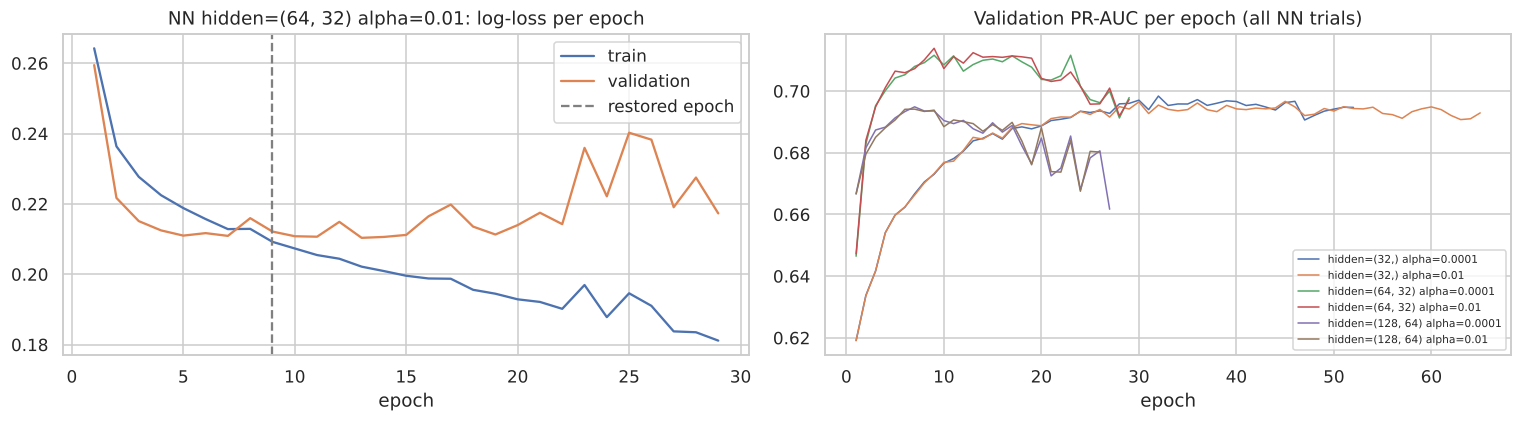

In [46]:
nn_runs, nn_models = [], {}
for hidden in [(32,), (64, 32), (128, 64)]:
    for alpha in [1e-4, 1e-2]:
        name = f'NN hidden={hidden} alpha={alpha}'
        r, m, _ = run_model(name, 'shallow NN', ShallowNN(hidden=hidden, alpha=alpha, seed=SEED), nn=True)
        r['best_epoch'] = m.best_epoch_
        nn_runs.append(r); nn_models[name] = m
display(show_runs(nn_runs, cols=('val PR-AUC', 'val ROC-AUC', 'val F1', 'train PR-AUC', 'best_epoch')))

best_nn_name = max(nn_runs, key=lambda r: r['val PR-AUC'])['model']
h = nn_models[best_nn_name].history_
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(h.epoch, h.train_loss, label='train'); axes[0].plot(h.epoch, h.val_loss, label='validation')
axes[0].axvline(nn_models[best_nn_name].best_epoch_, ls='--', c='grey', label='restored epoch')
axes[0].set_title(f'{best_nn_name}: log-loss per epoch'); axes[0].set_xlabel('epoch'); axes[0].legend()
for name, m in nn_models.items():
    axes[1].plot(m.history_.epoch, m.history_.val_pr_auc, label=name.replace('NN ', ''), lw=1)
axes[1].set_title('Validation PR-AUC per epoch (all NN trials)'); axes[1].set_xlabel('epoch'); axes[1].legend(fontsize=7)
savefig('nn_training_curves')

### 8.6 Model comparison: train / validation / unseen test
For each family, the configuration with the best **validation PR-AUC** is selected. Each is refitted with the same seed (identical to its trial) and evaluated **once** on the test seasons.

In [47]:
def best_of(runs):
    return max(runs, key=lambda r: r['val PR-AUC'])

def make_model(run_name):
    """Rebuild a model from its trial name (all trials are deterministic)."""
    if run_name.startswith('LogReg'):
        C = float(run_name.split('C=')[1].split()[0]); cw = run_name.split('cw=')[1]; cw = None if cw == 'None' else cw
        return Pipeline([('prep', make_prep(scale=True)), ('clf', LogisticRegression(C=C, class_weight=cw, max_iter=2000))]), False
    if run_name.startswith('RF'):
        d = run_name.split('depth=')[1].split()[0]; leaf = int(run_name.split('leaf=')[1])
        return Pipeline([('prep', make_prep(scale=False)), ('clf', RandomForestClassifier(
            n_estimators=400, max_depth=None if d == 'None' else int(d), min_samples_leaf=leaf, max_features='sqrt',
            n_jobs=-1, random_state=SEED))]), False
    if run_name.startswith('LGBM'):
        leaves = int(run_name.split('leaves=')[1].split()[0]); lr_ = float(run_name.split('lr=')[1].split()[0]); n = int(run_name.split('n=')[1])
        return Pipeline([('prep', make_prep(scale=False)), ('clf', lgb.LGBMClassifier(
            n_estimators=n, learning_rate=lr_, num_leaves=leaves, min_child_samples=30, subsample=0.8, subsample_freq=1,
            colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, verbose=-1))]), False
    if run_name.startswith('NN'):
        hidden = eval(run_name.split('hidden=')[1].split(' alpha')[0]); alpha = float(run_name.split('alpha=')[1])
        return ShallowNN(hidden=hidden, alpha=alpha, seed=SEED), True
    raise ValueError(run_name)

BEST = {'Baseline 0: grid rule': None}
for fam, runs in [('Logistic regression (baseline)', lr_runs), ('Random forest', rf_runs),
                  ('LightGBM', gb_runs), ('Shallow NN', nn_runs)]:
    BEST[fam] = best_of(runs)['model']
final_models, final_probs, final_res = {}, {}, []
for fam, run_name in BEST.items():
    if run_name is None:
        r, m, p = run_model(fam, 'heuristic', GridRule(), record=False)
    else:
        mdl, is_nn = make_model(run_name)
        r, m, p = run_model(fam, run_name, mdl, nn=is_nn, record=False)
    r['config'] = run_name or 'score = 1/grid'
    final_models[fam], final_probs[fam] = m, p; final_res.append(r)
comp = pd.DataFrame(final_res).set_index('model')
rows = []
for fam in comp.index:
    for s in ['train', 'val', 'test']:
        rows.append({'model': fam, 'split': s, **{k: comp.loc[fam, f'{s} {k}'] for k in METRICS},
                     'top-3 hit rate': comp.loc[fam, f'{s} top3'] if s != 'train' else np.nan,
                     'threshold (from val)': comp.loc[fam, 'threshold']})
comparison = pd.DataFrame(rows)
display(comp[['config']])
display(comparison.round(4))
comparison.to_csv(os.path.join(OUT_DIR, 'model_comparison.csv'), index=False)
pd.DataFrame(ALL_RUNS).to_csv(os.path.join(OUT_DIR, 'all_model_trials.csv'), index=False)
RESULTS['comparison'] = comparison.round(4).to_dict(orient='records')
RESULTS['n_trials'] = len(ALL_RUNS)

,config
model,
Baseline 0: grid rule,score = 1/grid
Logistic regression (baseline),LogReg C=1 cw=None
Random forest,RF depth=None leaf=10
LightGBM,LGBM leaves=15 lr=0.02 n=300
Shallow NN,"NN hidden=(64, 32) alpha=0.01"


,model,split,ROC-AUC,PR-AUC,F1,Precision,Recall,top-3 hit rate,threshold (from val)
0,Baseline 0: grid rule,train,0.9044,0.6092,0.6281,0.6281,0.6281,NaN,0.3333
1,Baseline 0: grid rule,val,0.9255,0.6851,0.7146,0.7161,0.7131,0.7173,0.3333
2,Baseline 0: grid rule,test,0.9113,0.6460,0.6605,0.6617,0.6593,0.6630,0.3333
3,Logistic regression (baseline),train,0.9306,0.6961,0.6495,0.6680,0.6319,NaN,0.4361
4,Logistic regression (baseline),val,0.9408,0.7082,0.7229,0.6396,0.8312,0.6709,0.4361
5,Logistic regression (baseline),test,0.9374,0.7120,0.6678,0.6325,0.7074,0.6556,0.4361
6,Random forest,train,0.9672,0.8296,0.7427,0.7442,0.7413,NaN,0.4158
7,Random forest,val,0.9439,0.7275,0.7211,0.6830,0.7637,0.7131,0.4158
8,Random forest,test,0.9396,0.7200,0.6767,0.6870,0.6667,0.6630,0.4158
9,LightGBM,train,0.9711,0.8491,0.7744,0.7019,0.8636,NaN,0.3236


Model selected on validation PR-AUC: Random forest -> RF depth=None leaf=10


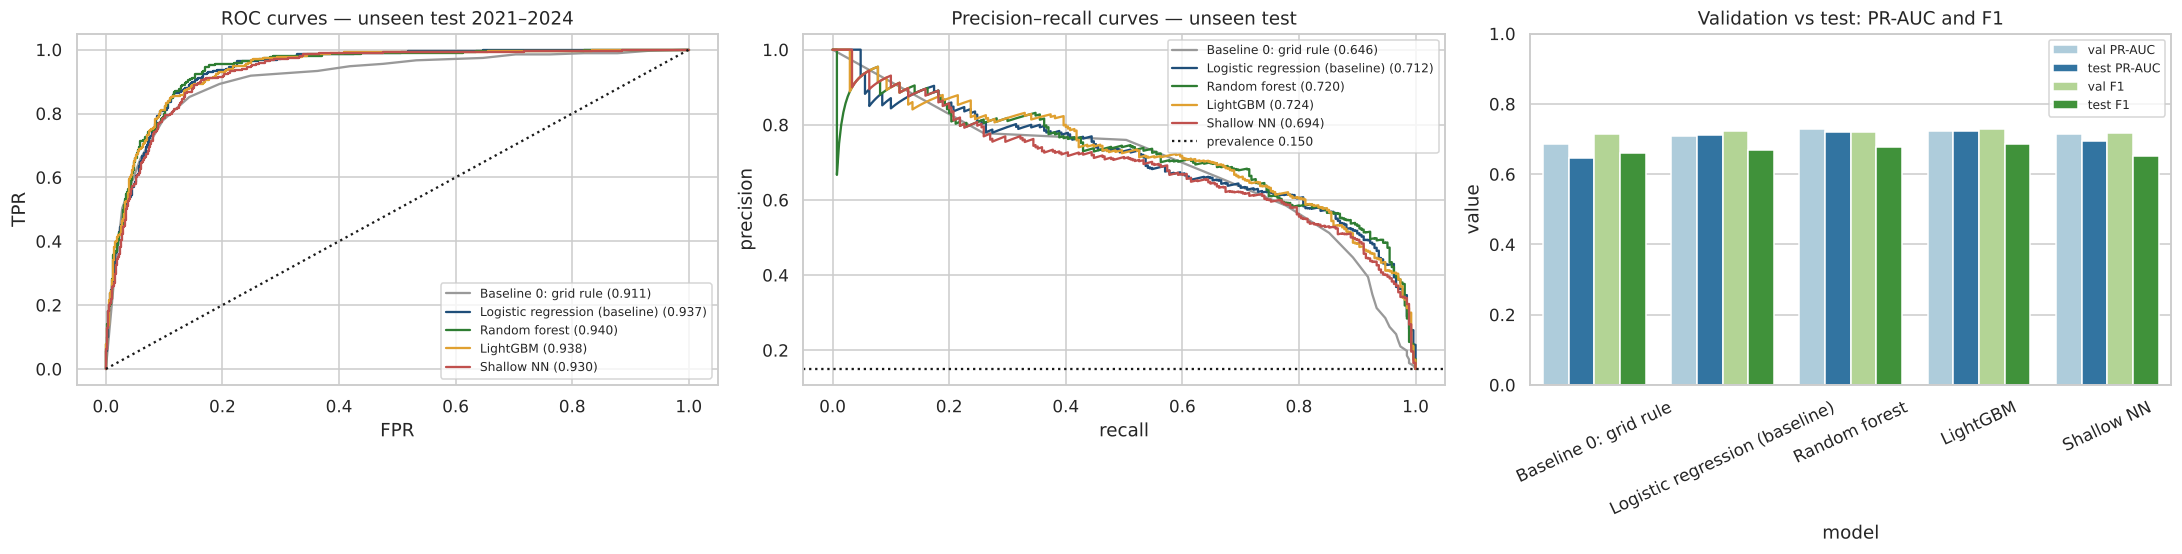

In [48]:
FINAL_NAME = comp.drop(index='Baseline 0: grid rule')['val PR-AUC'].idxmax()
print('Model selected on validation PR-AUC:', FINAL_NAME, '->', comp.loc[FINAL_NAME, 'config'])
RESULTS['final_model'] = dict(name=FINAL_NAME, config=comp.loc[FINAL_NAME, 'config'], threshold=float(comp.loc[FINAL_NAME, 'threshold']))

fig, axes = plt.subplots(1, 3, figsize=(20, 5.2))
cols = dict(zip(comp.index, ['#999999', '#1f4e79', '#2e7d32', '#e0a030', '#c0504d']))
for fam in comp.index:
    p = final_probs[fam]['test']
    fpr, tpr, _ = roc_curve(y_te, p); pr, rc, _ = precision_recall_curve(y_te, p)
    axes[0].plot(fpr, tpr, label=f"{fam} ({comp.loc[fam, 'test ROC-AUC']:.3f})", c=cols[fam])
    axes[1].plot(rc, pr, label=f"{fam} ({comp.loc[fam, 'test PR-AUC']:.3f})", c=cols[fam])
axes[0].plot([0, 1], [0, 1], 'k:'); axes[0].set_title('ROC curves — unseen test 2021–2024'); axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
axes[1].axhline(y_te.mean(), c='k', ls=':', label=f'prevalence {y_te.mean():.3f}')
axes[1].set_title('Precision–recall curves — unseen test'); axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision')
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
m_ = comparison.melt(id_vars=['model', 'split'], value_vars=['PR-AUC', 'F1'], var_name='metric')
m_ = m_[m_.split != 'train']
sns.barplot(data=m_, x='model', y='value', hue=m_.split + ' ' + m_.metric, ax=axes[2], palette='Paired')
axes[2].set_title('Validation vs test: PR-AUC and F1'); axes[2].tick_params(axis='x', rotation=25); axes[2].set_ylim(0, 1)
axes[2].legend(fontsize=8)
savefig('model_comparison')

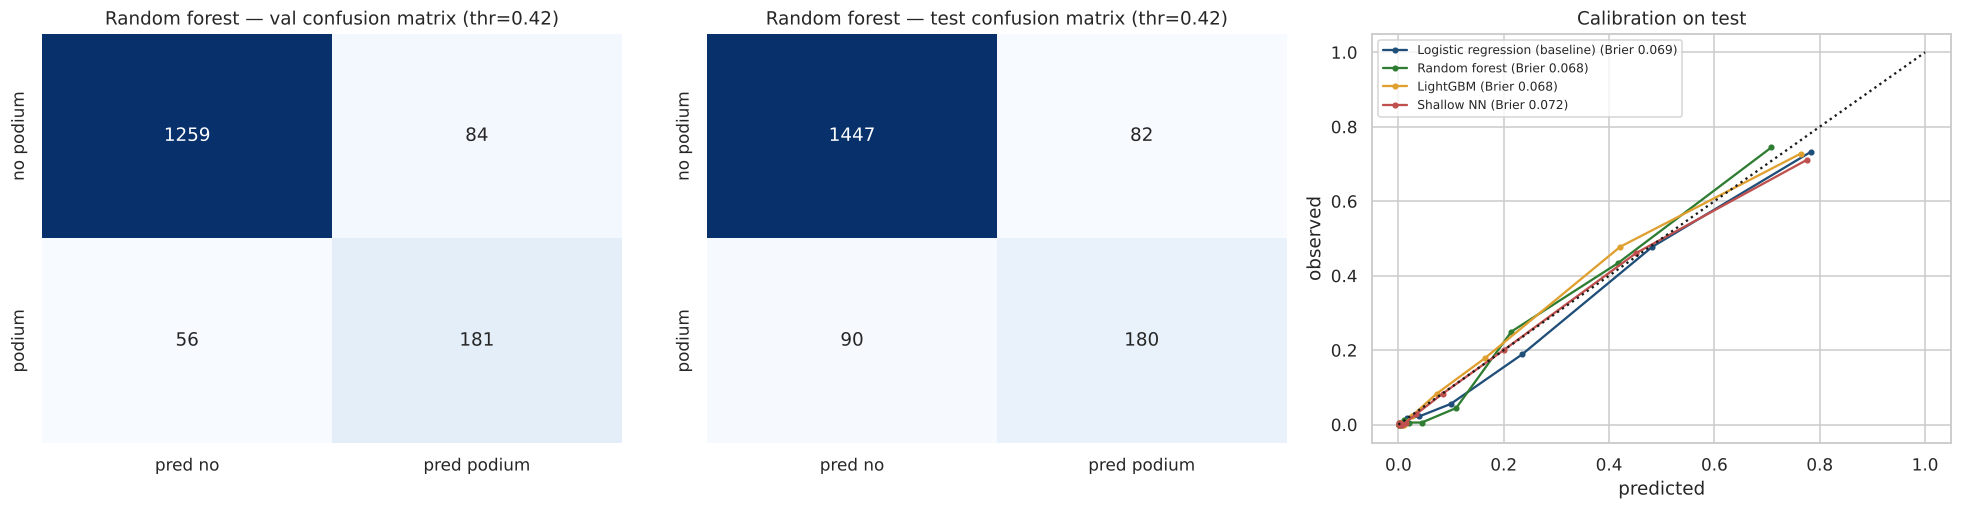

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
p_final = final_probs[FINAL_NAME]; thr_final = comp.loc[FINAL_NAME, 'threshold']
for ax, (s, y) in zip(axes[:2], [('val', y_va), ('test', y_te)]):
    cmx = confusion_matrix(y, (p_final[s] >= thr_final).astype(int))
    sns.heatmap(cmx, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['pred no', 'pred podium'], yticklabels=['no podium', 'podium'])
    ax.set_title(f'{FINAL_NAME} — {s} confusion matrix (thr={thr_final:.2f})')
for fam in comp.index.drop('Baseline 0: grid rule'):
    fr, mp = calibration_curve(y_te, final_probs[fam]['test'], n_bins=10, strategy='quantile')
    axes[2].plot(mp, fr, marker='o', ms=3, label=f"{fam} (Brier {brier_score_loss(y_te, final_probs[fam]['test']):.3f})", c=cols[fam])
axes[2].plot([0, 1], [0, 1], 'k:'); axes[2].set_title('Calibration on test'); axes[2].set_xlabel('predicted'); axes[2].set_ylabel('observed')
axes[2].legend(fontsize=8)
savefig('final_confusion_calibration')

,season,split,PR-AUC,ROC-AUC,top-3 hit rate
0,2017,val,0.751,0.944,0.750
1,2018,val,0.706,0.947,0.683
2,2019,val,0.746,0.946,0.714
3,2020,val,0.713,0.924,0.706
4,2021,test,0.779,0.940,0.697
5,2022,test,0.675,0.946,0.667
6,2023,test,0.770,0.932,0.652
7,2024,test,0.672,0.936,0.639


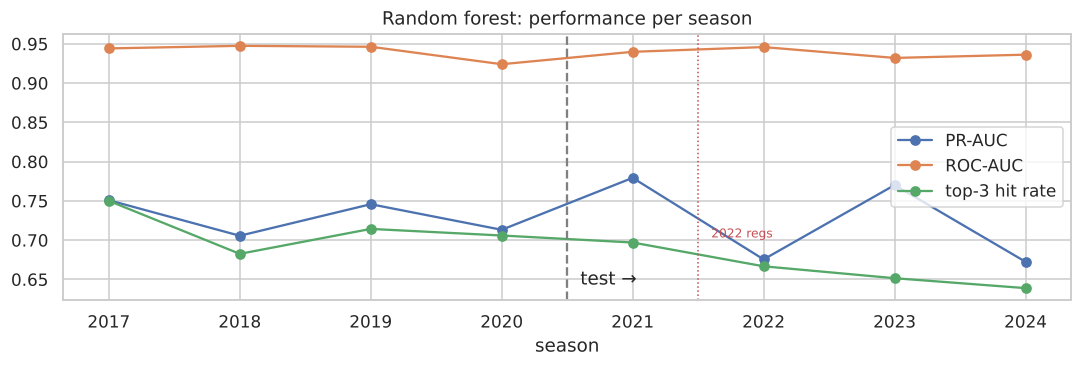

In [50]:
# Per-season stability of the selected model on validation + test seasons
season_rows = []
for s, d, p in [('val', va, p_final['val']), ('test', te, p_final['test'])]:
    for yv, g in d.assign(p=p).groupby('year'):
        season_rows.append({'season': yv, 'split': s, 'PR-AUC': average_precision_score(g[TARGET], g.p),
                            'ROC-AUC': roc_auc_score(g[TARGET], g.p), 'top-3 hit rate': top3_hit_rate(g.raceId, g[TARGET], g.p)})
season_perf = pd.DataFrame(season_rows)
display(season_perf.round(3))
fig, ax = plt.subplots(figsize=(10, 3.5))
season_perf.set_index('season')[['PR-AUC', 'ROC-AUC', 'top-3 hit rate']].plot(marker='o', ax=ax)
ax.axvline(2020.5, c='grey', ls='--'); ax.text(2020.6, ax.get_ylim()[0] + .02, 'test →'); ax.axvline(2021.5, c='r', ls=':', lw=1)
ax.text(2021.6, ax.get_ylim()[0] + .08, '2022 regs', color='r', fontsize=8); ax.set_title(f'{FINAL_NAME}: performance per season')
savefig('season_stability')
RESULTS['season_perf'] = season_perf.round(4).to_dict(orient='records')

### 8.7 How the models work, and their limitations
| model | how it works | strengths here | limitations |
|---|---|---|---|
| Grid rule | score = 1/grid | free, transparent | ignores car, form and penalties; cannot rank between equal grids across races |
| Logistic regression | linear log-odds, L2 penalty | calibrated, interpretable coefficients, hard to overfit | only additive monotone effects; cannot express "front row × top team" interactions |
| Random forest | average of 400 de-correlated deep trees | captures interactions and thresholds; robust to scale and outliers | train scores are optimistic (it partly memorises); probabilities are less smooth; large model |
| LightGBM | sequentially boosted shallow trees | strong on tabular data, handles interactions | many hyper-parameters; overfits with too many trees or leaves |
| Shallow NN | 2 ReLU layers, Adam, L2, early stopping | smooth non-linear function | needs scaling and imputation; ~6k training rows is small for a NN; sensitive to the seed; least interpretable |

**Reading the comparison.**
* On the unseen test seasons, every learned model beats the grid-only baseline on PR-AUC (0.69–0.72 vs 0.65) and ROC-AUC (0.93–0.94 vs 0.91).
* The four learned models are close. Logistic regression is already strong because most of the signal is a near-monotone function of grid, qualifying and car strength. The random forest (selected on validation) and LightGBM are best, and the NN is slightly behind (small data for a neural network).
* The tree ensembles score much higher on train than on validation (they partly memorise), but their validation and test scores agree, so they generalise, including to the new 2022 regulations.
* The **top-3 hit rate** shows an honest limit: per race, the three highest-rated drivers reach the podium about 64–71% of the time. That is about the same as simply picking the top 3 on the grid. The models are better at estimating *how likely* a podium is across all drivers (which PR-AUC rewards) than at re-ordering the front of a single grid.
* Validation scores are slightly optimistic because hyper-parameters and the threshold were chosen on them. **The test scores are the honest estimate.**

> **Key takeaway:** the selected random forest reaches test PR-AUC 0.720, ROC-AUC 0.940 and F1 0.677, against 0.646 / 0.911 / 0.661 for the grid-only baseline.

## 9. Experiments
### 9.1 Feature-group ablation
Remove **one feature group at a time**, retrain (same rows, same hyper-parameters, threshold re-chosen on validation) and measure the drop. This is done for the selected model **and** for the logistic-regression baseline, to see whether the conclusions depend on the model family.

,model,removed group,n features,val PR-AUC,val ROC-AUC,val F1,test PR-AUC,test ROC-AUC,test F1,Δ val PR-AUC,Δ test PR-AUC,Δ val F1,Δ test F1
0,Random forest,(none — full model),28,0.7275,0.9439,0.7211,0.7200,0.9396,0.6767,0.0000,0.0000,0.0000,0.0000
1,Random forest,grid,26,0.7136,0.9410,0.7070,0.7052,0.9357,0.6700,-0.0139,-0.0148,-0.0142,-0.0067
2,Random forest,qualifying,24,0.7193,0.9426,0.7222,0.7209,0.9361,0.6465,-0.0082,0.0009,0.0011,-0.0302
3,Random forest,standings,20,0.7082,0.9440,0.7220,0.7121,0.9389,0.6944,-0.0193,-0.0079,0.0009,0.0177
4,Random forest,driver_form,24,0.7326,0.9434,0.7251,0.7183,0.9403,0.6628,0.0051,-0.0017,0.0039,-0.0139
5,Random forest,constructor_form,25,0.7290,0.9425,0.7168,0.7132,0.9399,0.6767,0.0015,-0.0068,-0.0043,0.0001
6,Random forest,experience,23,0.7291,0.9449,0.7168,0.7233,0.9390,0.6798,0.0015,0.0032,-0.0044,0.0031
7,Random forest,context,26,0.7279,0.9436,0.7137,0.7193,0.9403,0.6866,0.0004,-0.0007,-0.0074,0.0099
8,Logistic regression (baseline),(none — full model),28,0.7082,0.9408,0.7229,0.7120,0.9374,0.6678,0.0000,0.0000,0.0000,0.0000
9,Logistic regression (baseline),grid,26,0.7084,0.9407,0.7206,0.7122,0.9372,0.6678,0.0002,0.0002,-0.0023,0.0000


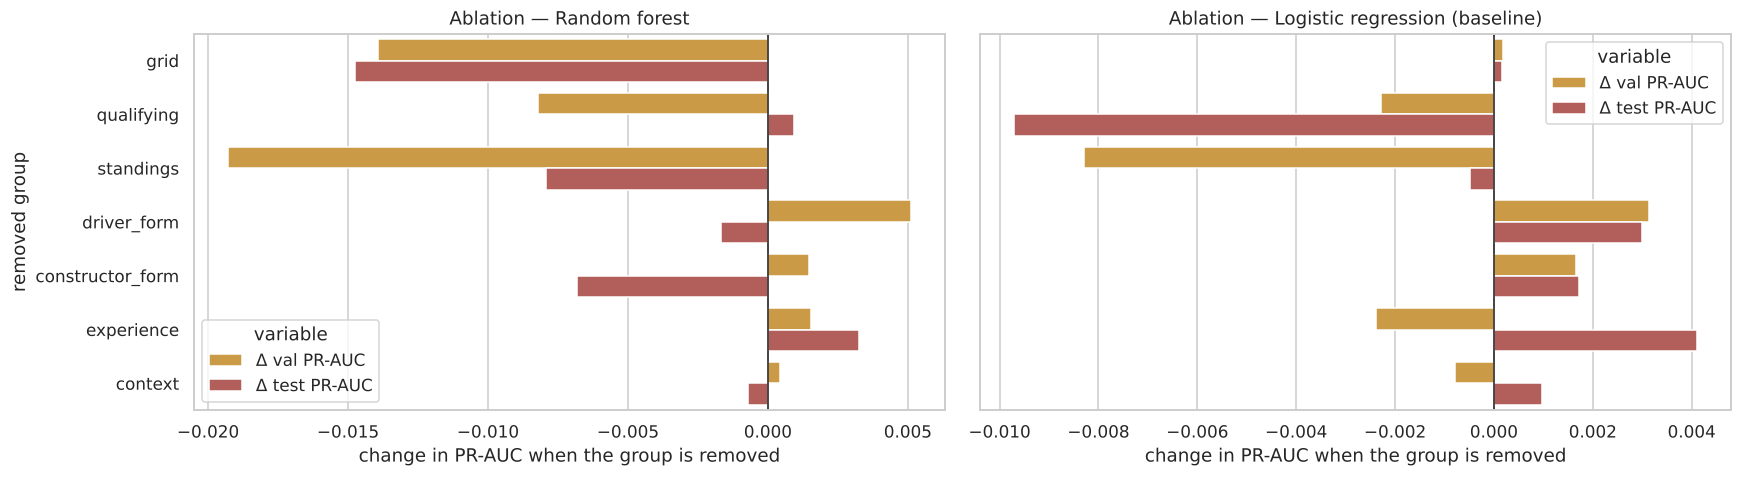

In [51]:
def model_factory(fam):
    mdl, is_nn = make_model(BEST[fam])
    return mdl, is_nn

abl_rows = []
for fam in [FINAL_NAME, 'Logistic regression (baseline)']:
    for group in ['(none — full model)'] + list(FEATURE_GROUPS):
        feats = FEATURES if group.startswith('(none') else [f for f in FEATURES if f not in FEATURE_GROUPS[group]]
        mdl, is_nn = model_factory(fam)
        r, _, _ = run_model(f'{fam} − {group}', 'ablation', mdl, X_tr[feats], X_va[feats], X_te[feats], nn=is_nn, record=False)
        abl_rows.append({'model': fam, 'removed group': group, 'n features': len(feats),
                         **{f'{s} {k}': r[f'{s} {k}'] for s in ['val', 'test'] for k in ['PR-AUC', 'ROC-AUC', 'F1']}})
ablation = pd.DataFrame(abl_rows)
for fam in ablation.model.unique():
    base = ablation[(ablation.model == fam) & ablation['removed group'].str.startswith('(none')].iloc[0]
    for c in ['val PR-AUC', 'test PR-AUC', 'val F1', 'test F1']:
        ablation.loc[ablation.model == fam, f'Δ {c}'] = ablation.loc[ablation.model == fam, c] - base[c]
display(ablation.round(4))
ablation.to_csv(os.path.join(OUT_DIR, 'ablation.csv'), index=False)
RESULTS['ablation'] = ablation.round(4).to_dict(orient='records')

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
for ax, fam in zip(axes, ablation.model.unique()):
    d = ablation[(ablation.model == fam) & ~ablation['removed group'].str.startswith('(none')]
    d = d.melt(id_vars='removed group', value_vars=['Δ val PR-AUC', 'Δ test PR-AUC'])
    sns.barplot(data=d, y='removed group', x='value', hue='variable', ax=ax, palette=['#e0a030', '#c0504d'])
    ax.axvline(0, c='k', lw=1); ax.set_title(f'Ablation — {fam}'); ax.set_xlabel('change in PR-AUC when the group is removed')
savefig('ablation')

**Reading the ablation** (negative Δ = the group helps, because removing it hurts):
* **Random forest:** removing **standings** (−0.019 val / −0.008 test) or **grid** (−0.014 / −0.015) hurts most. Qualifying hurts on validation and costs 0.03 F1 on test.
* **Logistic regression:** only **standings** (val) and **qualifying** (test) matter clearly. Removing grid costs nothing, because the linear model gets the same information from `quali_pos`.
* **Driver form, constructor form, experience, context:** changes stay within about ±0.007, the same size as run-to-run noise (just re-ordering the columns changes the forest's PR-AUC by about 0.001–0.005). Their extra contribution is not measurable once grid, qualifying and standings are present. `home_race` (context) adds nothing, as Q2 predicted.

In [52]:
# Redundancy check: remove grid AND qualifying together (all starting-position information)
pairs = {'grid + qualifying': FEATURE_GROUPS['grid'] + FEATURE_GROUPS['qualifying'],
         'standings + constructor_form': FEATURE_GROUPS['standings'] + FEATURE_GROUPS['constructor_form'],
         'ONLY grid + qualifying': [f for f in FEATURES if f not in FEATURE_GROUPS['grid'] + FEATURE_GROUPS['qualifying']]}
pair_rows = []
for label, drop in pairs.items():
    feats = [f for f in FEATURES if f not in drop]
    mdl, is_nn = model_factory(FINAL_NAME)
    r, _, _ = run_model(label, 'ablation', mdl, X_tr[feats], X_va[feats], X_te[feats], nn=is_nn, record=False)
    pair_rows.append({'removed': label if not label.startswith('ONLY') else 'everything except grid + qualifying',
                      'n features': len(feats), 'val PR-AUC': r['val PR-AUC'], 'test PR-AUC': r['test PR-AUC']})
pair_abl = pd.DataFrame(pair_rows); display(pair_abl.round(4))
RESULTS['pair_ablation'] = pair_abl.round(4).to_dict(orient='records')

,removed,n features,val PR-AUC,test PR-AUC
0,grid + qualifying,22,0.6214,0.6098
1,standings + constructor_form,17,0.7086,0.7030
2,everything except grid + qualifying,6,0.7042,0.6638


Removing grid **and** qualifying together drops validation PR-AUC from 0.728 to **0.621**, a much larger loss than removing either alone (−0.014, −0.008). The two groups are **substitutes**: each can stand in for the other. A model with **only** these 6 features reaches 0.704 (val) / 0.664 (test). The other groups add car-strength and form context worth about +0.02 to +0.06 PR-AUC.

> **Key takeaway:** starting position (grid/qualifying) and car strength (standings) are the groups the model needs. Form, experience and context add little on top.

### 9.2 Preprocessing-order experiments
Each experiment changes only *where* or *in which order* a preprocessing step happens, keeping the model (logistic regression, which is the most sensitive to preprocessing) fixed.
* **P1: fit the imputer and scaler before vs after splitting.** The leaky version fits medians, means and standard deviations on all of 2003–2024, so test-season statistics leak into training.
* **P2: impute → scale vs scale → impute** with a constant fill of 0. Imputing 0 before scaling plants an artificial value (e.g. "0 points share" or "quali position 0"). Imputing 0 *after* scaling means "the training mean".
* **P3: feature selection before vs after splitting.** `SelectKBest(mutual information, k=12)` is fitted on all rows including validation and test labels (leaky) vs on training rows only.

,experiment,variant,val PR-AUC,val ROC-AUC,val F1,test PR-AUC,test ROC-AUC,test F1
0,P1 fit-before/after split,fit on TRAIN only (correct),0.7082,0.9408,0.7229,0.7120,0.9374,0.6678
1,P1 fit-before/after split,fit on ALL seasons (leaky),0.7074,0.9408,0.7256,0.7114,0.9374,0.6643
2,P2 impute/scale order,impute 0 → scale,0.7057,0.9380,0.7206,0.7075,0.9354,0.6678
3,P2 impute/scale order,scale → impute 0 (= mean),0.7060,0.9378,0.7216,0.7088,0.9360,0.6667
4,P3 feature-selection order,select on TRAIN only (correct),0.6914,0.9338,0.7269,0.7105,0.9338,0.6689
5,P3 feature-selection order,select on ALL rows incl. test labels (leaky),0.6914,0.9338,0.7269,0.7105,0.9338,0.6689


P3 features chosen only when test labels are visible: []
P1 largest shifts in scaler means (train-only vs all-data):


,train-only mean,all-data mean,shift
drv_prior_starts,90.677,103.959,13.281
field_size,21.707,21.062,-0.645
quali_pos,11.316,11.002,-0.313
grid_pos,11.358,11.048,-0.309
drv_champ_pos,11.419,11.114,-0.304


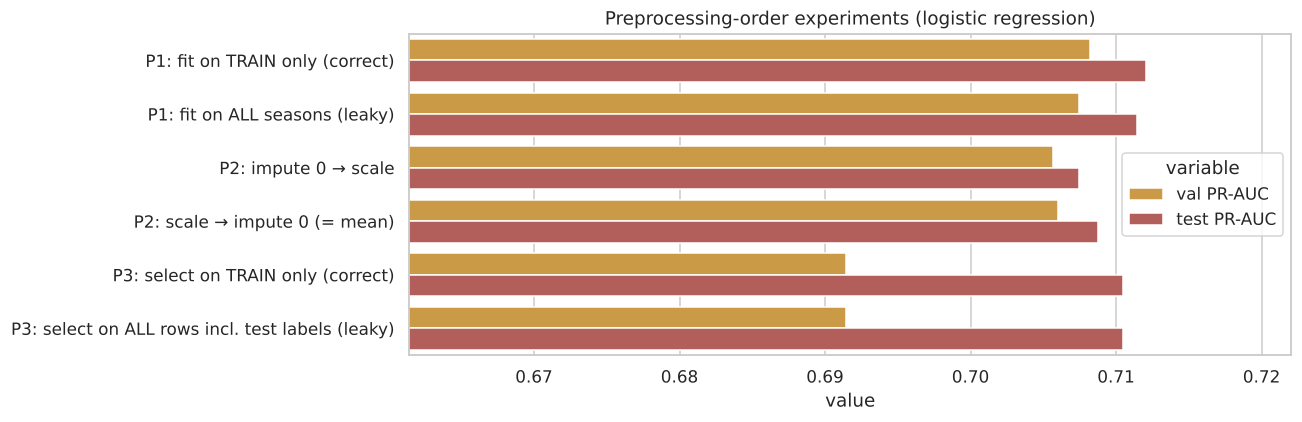

In [53]:
best_lr = make_model(BEST['Logistic regression (baseline)'])[0].named_steps['clf']
C_best, cw_best = best_lr.C, best_lr.class_weight
def lr_clf(): return LogisticRegression(C=C_best, class_weight=cw_best, max_iter=2000)

class Prefit:
    """Wrap an already fitted transformer so Pipeline.fit does not refit it (used for the leaky variants)."""
    def __init__(self, t): self.t = t
    def fit(self, X, y=None): return self
    def transform(self, X): return self.t.transform(X)

X_all = pd.concat([X_tr, X_va, X_te]); y_all = np.r_[y_tr, y_va, y_te]
exp_rows = []
def record(exp, variant, model):
    r, _, _ = run_model(f'{exp}: {variant}', 'preprocessing experiment', model, record=False)
    exp_rows.append({'experiment': exp, 'variant': variant, **{f'{s} {k}': r[f'{s} {k}'] for s in ['val', 'test'] for k in ['PR-AUC', 'ROC-AUC', 'F1']}})

# P1
record('P1 fit-before/after split', 'fit on TRAIN only (correct)', Pipeline([('prep', make_prep(True)), ('clf', lr_clf())]))
leaky_prep = make_prep(True).fit(X_all)
record('P1 fit-before/after split', 'fit on ALL seasons (leaky)', Pipeline([('prep', Prefit(leaky_prep)), ('clf', lr_clf())]))
drift = pd.DataFrame({'train-only mean': make_prep(True).fit(X_tr).named_steps['scale'].mean_[:len(FEATURES)],
                      'all-data mean': leaky_prep.named_steps['scale'].mean_[:len(FEATURES)]}, index=FEATURES)
drift['shift'] = drift['all-data mean'] - drift['train-only mean']
# P2
record('P2 impute/scale order', 'impute 0 → scale', Pipeline([('w', Winsorizer(WINSOR_COLS)), ('imp', SimpleImputer(strategy='constant', fill_value=0)),
                                                         ('sc', StandardScaler()), ('clf', lr_clf())]))
record('P2 impute/scale order', 'scale → impute 0 (= mean)', Pipeline([('w', Winsorizer(WINSOR_COLS)), ('sc', StandardScaler()),
                                                                  ('imp', SimpleImputer(strategy='constant', fill_value=0)), ('clf', lr_clf())]))
# P3
sel_train = SelectKBest(lambda X, y: mutual_info_classif(X, y, random_state=SEED), k=12)
record('P3 feature-selection order', 'select on TRAIN only (correct)',
       Pipeline([('prep', make_prep(True)), ('sel', sel_train), ('clf', lr_clf())]))
prep_all = make_prep(True).fit(X_all)
sel_all = SelectKBest(lambda X, y: mutual_info_classif(X, y, random_state=SEED), k=12).fit(prep_all.transform(X_all), y_all)
record('P3 feature-selection order', 'select on ALL rows incl. test labels (leaky)',
       Pipeline([('prep', make_prep(True)), ('sel', Prefit(sel_all)), ('clf', lr_clf())]))
prep_order = pd.DataFrame(exp_rows)
display(prep_order.round(4))
prep_tr_ = make_prep(True).fit(X_tr)
sel_names_tr = np.array(names_out)[SelectKBest(lambda X, y: mutual_info_classif(X, y, random_state=SEED), k=12)
                                   .fit(prep_tr_.transform(X_tr), y_tr).get_support()]
sel_names_all = np.array(names_out)[sel_all.get_support()]
print('P3 features chosen only when test labels are visible:', sorted(set(sel_names_all) - set(sel_names_tr)))
print('P1 largest shifts in scaler means (train-only vs all-data):'); display(drift.reindex(drift['shift'].abs().sort_values(ascending=False).index).head(5).round(3))
prep_order.to_csv(os.path.join(OUT_DIR, 'preprocessing_order.csv'), index=False)
RESULTS['prep_order'] = prep_order.round(4).to_dict(orient='records')

fig, ax = plt.subplots(figsize=(12, 4))
d = prep_order.melt(id_vars=['experiment', 'variant'], value_vars=['val PR-AUC', 'test PR-AUC'])
d['label'] = d.experiment.str.split(' ').str[0] + ': ' + d.variant
sns.barplot(data=d, y='label', x='value', hue='variable', ax=ax, palette=['#e0a030', '#c0504d'])
ax.set_xlim(d.value.min() - .03, d.value.max() + .01); ax.set_title('Preprocessing-order experiments (logistic regression)'); ax.set_ylabel('')
savefig('preprocessing_order')

**Reading the preprocessing-order experiments.**
* **P1 (fit before vs after split):** almost no difference here (val PR-AUC 0.7082 vs 0.7074), because 2003–2024 statistics are close to 2003–2016 statistics. One feature does drift: the mean of `drv_prior_starts` moves from 90.7 to 104.0, because careers keep getting longer. The leaky version is still wrong in principle: it uses future seasons to set the scaling.
* **P2 (impute → scale vs scale → impute, constant 0):** a small difference (0.7057 vs 0.7060). Both are *worse* than our pipeline (median + missing indicators: 0.7082). Imputing 0 before scaling plants impossible values such as "previous-season position 0" for every rookie.
* **P3 (feature selection before vs after split):** identical results here, because the same 12 features are chosen either way (the strongest features are obvious). The leak is still real. With weaker or more numerous features, selecting on test labels would inflate the test score. So selection always sits inside the training-only pipeline.

> **Key takeaway:** on this data the leaky orders only change scores in the third decimal, but they are wrong in principle. The correct order (fit on train only, median + indicator imputation before scaling) is also the best-scoring variant.

### 9.3 Training-window experiment (qualifying-coverage drift)
Section 1.2 found that qualifying data is patchy in 1994–2002. Does adding those seasons (more rows, but missing qualifying features) help or hurt? We train the selected model on 1994–2016 vs 2003–2016 and evaluate both on the same validation and test seasons.

In [54]:
win_rows = []
for start in [1994, 2003]:
    trw = feat_all[feat_all.year.between(start, TRAIN_YEARS[1])]
    mdl, is_nn = model_factory(FINAL_NAME)
    mdl.fit(trw[FEATURES], trw[TARGET].values) if not is_nn else mdl.fit(trw[FEATURES], trw[TARGET].values, X_va, y_va)
    pv, pt = mdl.predict_proba(X_va)[:, 1], mdl.predict_proba(X_te)[:, 1]
    thr = best_f1_threshold(y_va, pv)
    win_rows.append({'train window': f'{start}–{TRAIN_YEARS[1]}', 'train rows': len(trw),
                     'quali_pos missing in train %': trw.quali_pos.isna().mean() * 100,
                     **{f'val {k}': v for k, v in evaluate(y_va, pv, thr).items() if k in ['PR-AUC', 'ROC-AUC', 'F1']},
                     **{f'test {k}': v for k, v in evaluate(y_te, pt, thr).items() if k in ['PR-AUC', 'ROC-AUC', 'F1']}})
window_exp = pd.DataFrame(win_rows); display(window_exp.round(4))
RESULTS['window_exp'] = window_exp.round(4).to_dict(orient='records')

,train window,train rows,quali_pos missing in train %,val ROC-AUC,val PR-AUC,val F1,test ROC-AUC,test PR-AUC,test F1
0,1994–2016,8979,20.7039,0.9435,0.7241,0.7159,0.9397,0.7213,0.7061
1,2003–2016,5591,0.3398,0.9439,0.7275,0.7211,0.9396,0.7200,0.6767


### 9.4 Feature-subset trial (empirical selection check)
Instead of deleting features by intuition, we try keeping only the top-k features ranked by training-set mutual information (Section 6.1) and compare validation PR-AUC. If a small subset matched the full set, the extra features would be unnecessary.

,k,val PR-AUC,val F1,test PR-AUC
0,4,0.7271,0.7031,0.6846
1,8,0.7228,0.7143,0.7129
2,12,0.7272,0.7194,0.7171
3,16,0.7301,0.7146,0.7275
4,20,0.7321,0.7177,0.7205
5,28,0.7266,0.7191,0.7186


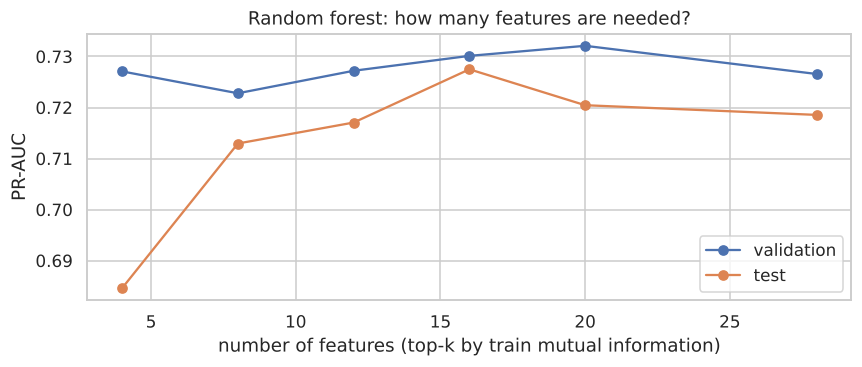

In [55]:
mi_rank = evidence.sort_values('mutual information', ascending=False).feature.tolist()
k_rows = []
for k in [4, 8, 12, 16, 20, len(FEATURES)]:
    feats = mi_rank[:k]
    mdl, is_nn = model_factory(FINAL_NAME)
    r, _, _ = run_model(f'top-{k} MI features', 'feature subset', mdl, X_tr[feats], X_va[feats], X_te[feats], nn=is_nn, record=False)
    k_rows.append({'k': k, 'val PR-AUC': r['val PR-AUC'], 'val F1': r['val F1'], 'test PR-AUC': r['test PR-AUC']})
k_exp = pd.DataFrame(k_rows); display(k_exp.round(4))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(k_exp.k, k_exp['val PR-AUC'], marker='o', label='validation'); ax.plot(k_exp.k, k_exp['test PR-AUC'], marker='o', label='test')
ax.set_xlabel('number of features (top-k by train mutual information)'); ax.set_ylabel('PR-AUC'); ax.legend()
ax.set_title(f'{FINAL_NAME}: how many features are needed?')
savefig('k_best_trial')
RESULTS['k_exp'] = k_exp.round(4).to_dict(orient='records')

**Reading the window experiment (9.3).** Adding 1994–2002 (60% more rows, but 21% of them without qualifying data) gives slightly *lower* validation PR-AUC (0.724 vs 0.728) and about the same test PR-AUC (0.721 vs 0.720). Validation is our selection criterion, so we keep **2003–2024**. The broader window gave a higher test F1 (0.706 vs 0.677), which is worth re-testing in the next milestone.

**Reading the subset trial (9.4).** Only 4 features (grid, qualifying, gap to pole, driver standing) already reach validation PR-AUC 0.727. Between k = 12 and k = 28 the scores move within about ±0.005. That is noise: the full set with columns in a different order scores 0.7266 instead of 0.7275. No subset is *clearly* better, so we keep all 28 leakage-safe features, which cost nothing at prediction time.

> **Key takeaway:** the 2003+ window and the full feature set are confirmed empirically. A handful of features carries most of the signal.

## 10. Explainability (XAI)
> **Important: explanations describe the model, not the sport.** A feature being important means the *model relies on it to make predictions*. It is **not** evidence that the feature *causes* podium finishes. For example, `con_pts_share` is important because points share is a proxy for car speed, which is the real (unobserved) driver of results. Many features are correlated (grid ↔ qualifying, standings ↔ constructor form), so importance can be split arbitrarily between them. None of the plots below should be read as "changing X would change the outcome".

The explanations are computed for the **selected model**, with permutation importance also shown for the logistic baseline as a cross-check.

### 10.1 Global: permutation importance (validation set, PR-AUC drop)

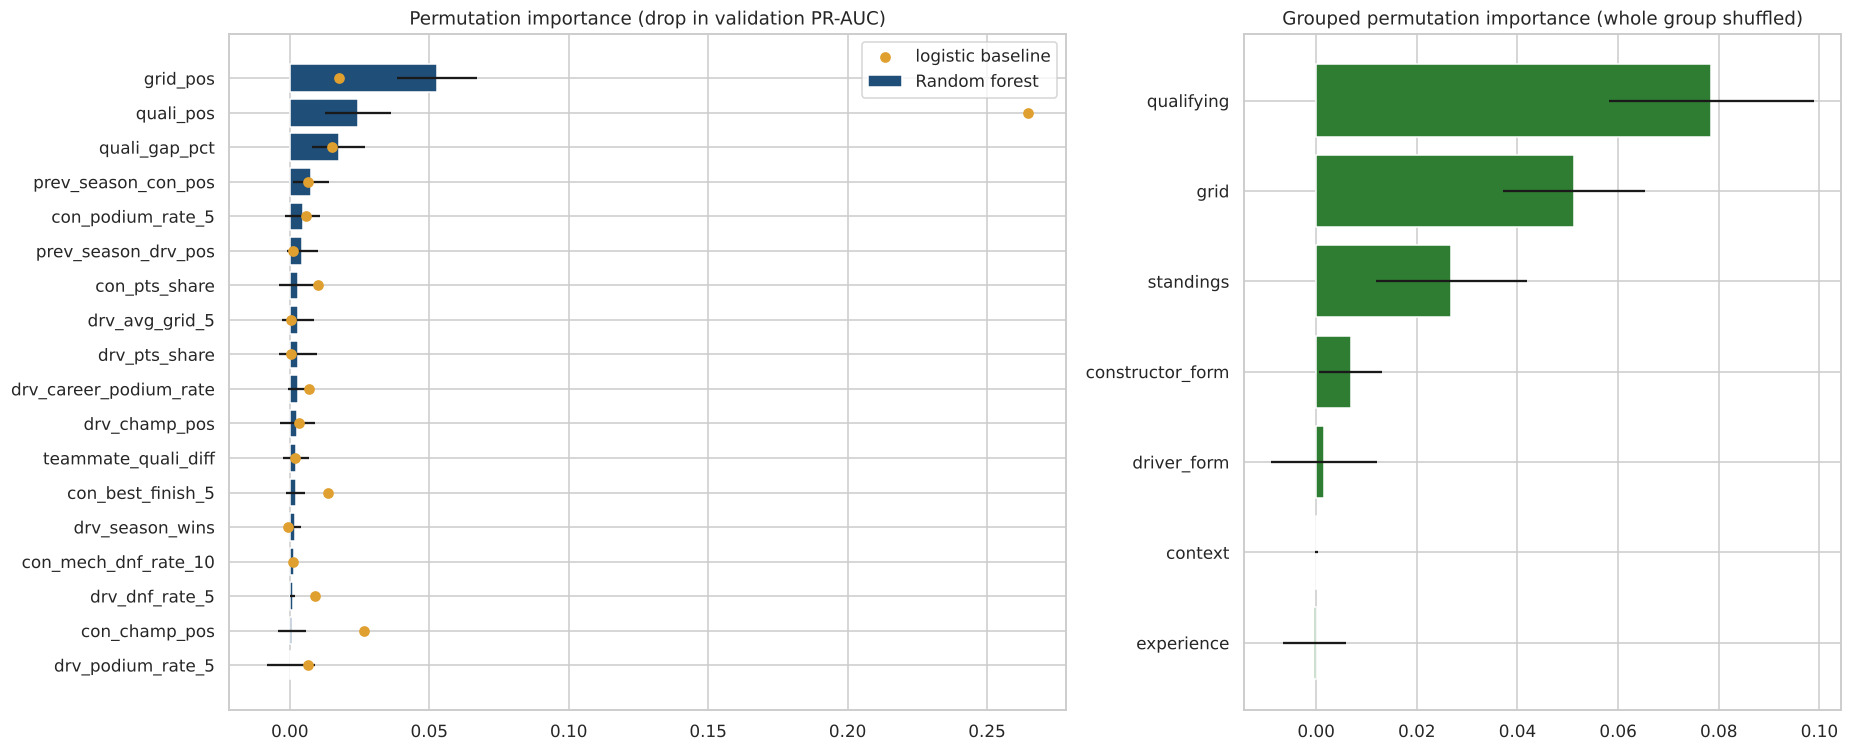

,feature,mean,std,mean (logistic baseline)
0,grid_pos,0.0528,0.0144,0.0175
2,quali_pos,0.0246,0.0118,0.2646
3,quali_gap_pct,0.0175,0.0095,0.0153
12,prev_season_con_pos,0.0076,0.0065,0.0065
18,con_podium_rate_5,0.0046,0.0062,0.0058
11,prev_season_drv_pos,0.0045,0.0054,0.0010
9,con_pts_share,0.0030,0.0070,0.0101
17,drv_avg_grid_5,0.0029,0.0056,0.0006
6,drv_pts_share,0.0029,0.0068,0.0004
22,drv_career_podium_rate,0.0029,0.0036,0.0069


,group,PR-AUC drop,std
1,qualifying,0.0785,0.0204
0,grid,0.0512,0.0141
2,standings,0.0269,0.0151
4,constructor_form,0.0068,0.0063
3,driver_form,0.0016,0.0105
6,context,0.0001,0.0002
5,experience,-0.0003,0.0063


In [56]:
final_model = final_models[FINAL_NAME]
pi = permutation_importance(final_model, X_va, y_va, scoring='average_precision', n_repeats=15, random_state=SEED, n_jobs=-1)
pi_df = pd.DataFrame({'feature': FEATURES, 'mean': pi.importances_mean, 'std': pi.importances_std}).sort_values('mean', ascending=False)
pi_lr = permutation_importance(final_models['Logistic regression (baseline)'], X_va, y_va, scoring='average_precision',
                               n_repeats=15, random_state=SEED, n_jobs=-1)
pi_df['mean (logistic baseline)'] = pd.Series(pi_lr.importances_mean, index=FEATURES).reindex(pi_df.feature).values

# grouped permutation: shuffle all columns of a group together (handles correlated features within a group)
rng = np.random.default_rng(SEED); base_ap = average_precision_score(y_va, final_model.predict_proba(X_va)[:, 1])
grp_rows = []
for g, fs in FEATURE_GROUPS.items():
    drops = []
    for _ in range(15):
        Xp = X_va.copy(); idx = rng.permutation(len(Xp)); Xp[fs] = Xp[fs].values[idx]
        drops.append(base_ap - average_precision_score(y_va, final_model.predict_proba(Xp)[:, 1]))
    grp_rows.append({'group': g, 'PR-AUC drop': np.mean(drops), 'std': np.std(drops)})
grp_pi = pd.DataFrame(grp_rows).sort_values('PR-AUC drop', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={'width_ratios': [1.4, 1]})
top = pi_df.head(18).iloc[::-1]
axes[0].barh(top.feature, top['mean'], xerr=top['std'], color='#1f4e79', label=FINAL_NAME)
axes[0].scatter(top['mean (logistic baseline)'], top.feature, color='#e0a030', zorder=3, label='logistic baseline')
axes[0].set_title('Permutation importance (drop in validation PR-AUC)'); axes[0].legend()
axes[1].barh(grp_pi.group[::-1], grp_pi['PR-AUC drop'][::-1], xerr=grp_pi['std'][::-1], color='#2e7d32')
axes[1].set_title('Grouped permutation importance (whole group shuffled)')
savefig('xai_permutation')
display(pi_df.head(12).round(4)); display(grp_pi.round(4))
RESULTS['perm_top'] = pi_df.head(10)[['feature', 'mean']].round(4).values.tolist()
RESULTS['perm_groups'] = grp_pi.round(4).values.tolist()

**Interpretation.**
* For the random forest, `grid_pos` is the single most important feature (shuffling it costs 0.053 PR-AUC), followed by `quali_pos` and `quali_gap_pct`, then previous-season constructor position and recent constructor podium rate.
* The logistic baseline leans mostly on `quali_pos` (0.26). It uses grid and qualifying as one combined signal. Both models rely on the same kind of information.
* Single-feature importance *understates* correlated features (shuffling one leaves its twin intact). The **grouped** version shuffles whole groups: qualifying (−0.079), grid (−0.051) and standings (−0.027) matter, while driver form, experience and context are ≈ 0. This agrees with the ablation in 9.1.

### 10.2 Global: SHAP
SHAP decomposes each prediction (in log-odds for boosting, probability for forests) into additive contributions per input that sum to the prediction minus the average. We use the exact `TreeExplainer` on the model's transformed inputs (features + missing indicators), for a sample of test rows.

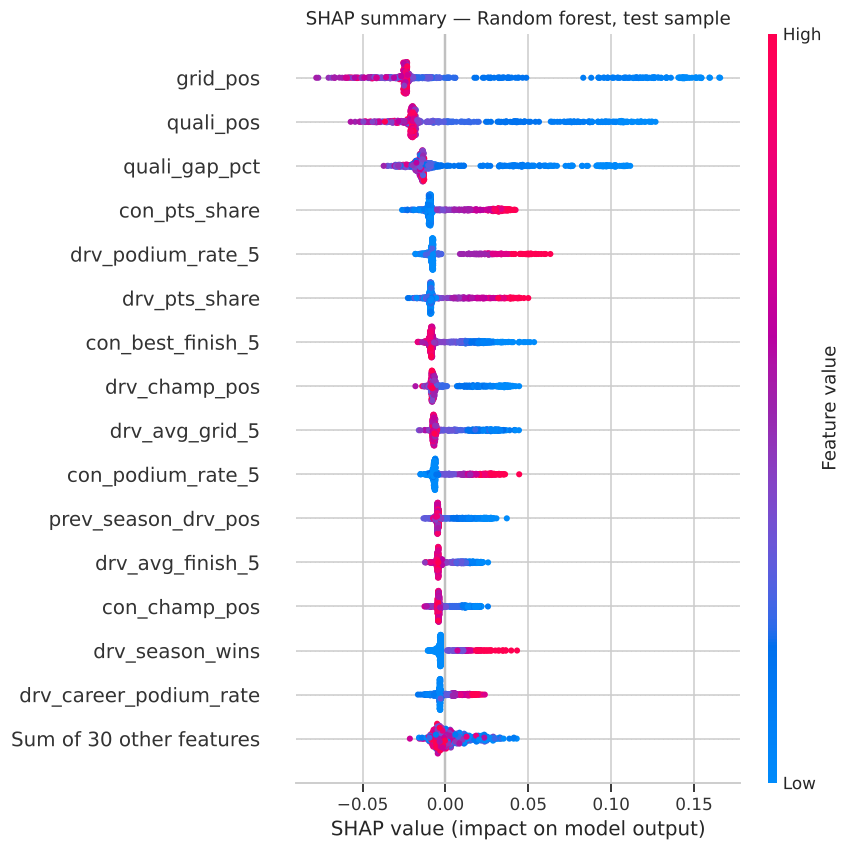

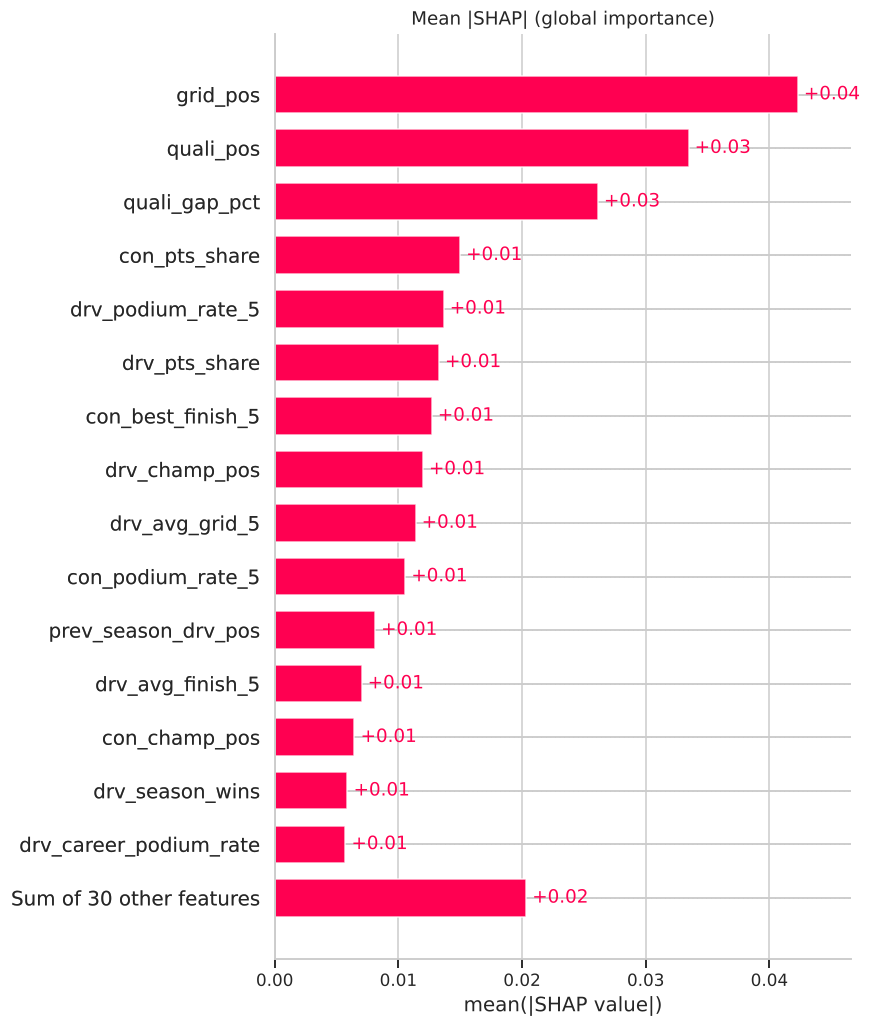

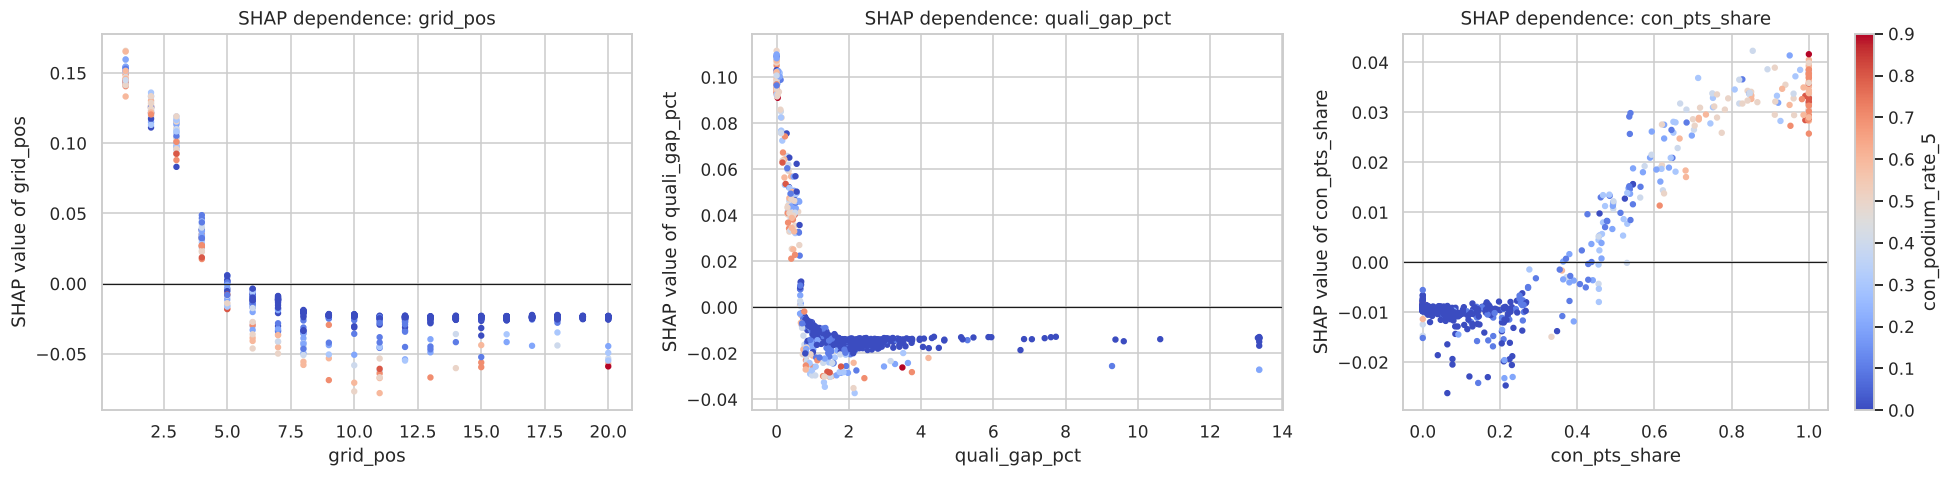

In [57]:
import shap
tree_pipe = final_model if hasattr(final_model, 'named_steps') else final_models['LightGBM']
xai_name = FINAL_NAME if tree_pipe is final_model else 'LightGBM'
prep_fitted, clf_fitted = tree_pipe.named_steps['prep'], tree_pipe.named_steps['clf']
feat_names_t = list(FEATURES) + [f'missing_{FEATURES[i]}' for i in prep_fitted.named_steps['impute'].indicator_.features_]
Xt_te = pd.DataFrame(prep_fitted.transform(X_te), columns=feat_names_t)
Xt_tr = pd.DataFrame(prep_fitted.transform(X_tr), columns=feat_names_t)
sample_idx = np.random.default_rng(SEED).choice(len(Xt_te), size=min(600, len(Xt_te)), replace=False)
explainer = shap.TreeExplainer(clf_fitted)
sv = explainer(Xt_te.iloc[sample_idx])
if sv.values.ndim == 3:                       # random forest: (rows, features, classes) -> class 1
    sv = shap.Explanation(sv.values[:, :, 1], base_values=sv.base_values[:, 1], data=sv.data, feature_names=feat_names_t)
plt.figure(); shap.plots.beeswarm(sv, max_display=16, show=False); plt.title(f'SHAP summary — {xai_name}, test sample'); savefig('xai_shap_beeswarm')
plt.figure(); shap.plots.bar(sv, max_display=16, show=False); plt.title('Mean |SHAP| (global importance)'); savefig('xai_shap_bar')
mean_abs = pd.Series(np.abs(sv.values).mean(0), index=feat_names_t).sort_values(ascending=False)
RESULTS['shap_top'] = mean_abs.head(10).round(4).reset_index().values.tolist()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, f in zip(axes, ['grid_pos', 'quali_gap_pct', 'con_pts_share']):
    j = feat_names_t.index(f)
    sc = ax.scatter(sv.data[:, j], sv.values[:, j], c=sv.data[:, feat_names_t.index('con_podium_rate_5')], cmap='coolwarm', s=10)
    ax.axhline(0, c='k', lw=.8); ax.set_xlabel(f); ax.set_ylabel(f'SHAP value of {f}'); ax.set_title(f'SHAP dependence: {f}')
plt.colorbar(sc, ax=axes[-1], label='con_podium_rate_5')
savefig('xai_shap_dependence')

**Interpretation of SHAP** (each dot = one test driver-race; to the right = pushes towards "podium"):
* **Grid position:** P1–P3 push strongly up (+0.10 to +0.15 probability). The effect drops sharply at P4–P5 and is flat beyond about P8. The model has learned "outside the top 8, the exact slot hardly matters".
* **Gap to pole:** being within about 0.5% of pole pushes up by up to +0.10. Beyond about 1% the contribution is flat and slightly negative.
* **Constructor points share:** rises steadily from about 0.3 to 1.0. The stronger the car so far this season, the higher the prediction.
* SHAP and permutation importance agree on the top features, which makes the global picture more credible.
* **Reminder:** these describe how the model uses the features, not causal effects.

### 10.3 Local explanations: one prediction with SHAP (waterfall) and LIME
We explain a single test prediction: a driver who did **not** start from the front row but whom the model still rates as a likely podium finisher. This is the interesting kind of call, where the model goes beyond the grid rule.

Explained row: Belgian Grand Prix 2023 — driver max_verstappen (Red Bull), grid 6, predicted P(podium) = 0.658, actual finishing position = 1


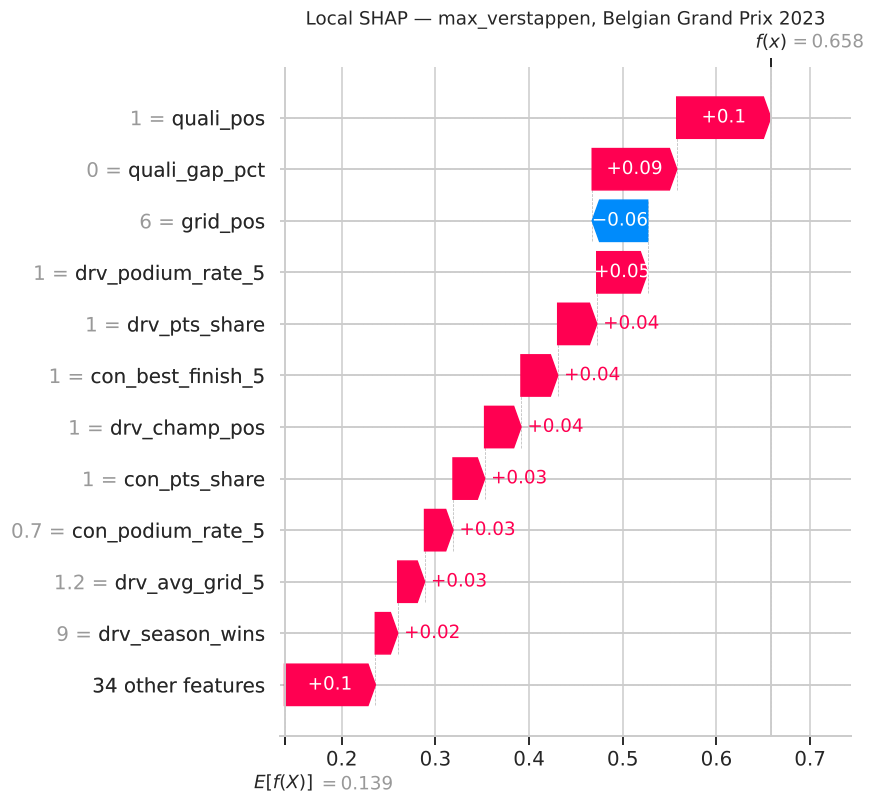

In [58]:
te_pred = te.assign(p=final_probs[FINAL_NAME]['test'])
cand = te_pred[(te_pred.grid_pos >= 4) & (te_pred.p >= comp.loc[FINAL_NAME, 'threshold'])].sort_values('p', ascending=False)
row_i = int(cand.index[0]) if len(cand) else int(te_pred.p.idxmax())
row = te_pred.loc[row_i]
print(f"Explained row: {row['name']} {int(row.year)} — driver {row.driverRef} ({row.constructor}), grid {int(row.grid_pos)}, "
      f"predicted P(podium) = {row.p:.3f}, actual finishing position = {int(row.positionOrder)}")
sv_row = explainer(Xt_te.iloc[[row_i]])
if sv_row.values.ndim == 3:
    sv_row = shap.Explanation(sv_row.values[:, :, 1], base_values=sv_row.base_values[:, 1], data=sv_row.data, feature_names=feat_names_t)
plt.figure(); shap.plots.waterfall(sv_row[0], max_display=12, show=False)
plt.title(f"Local SHAP — {row.driverRef}, {row['name']} {int(row.year)}"); savefig('xai_local_shap')
RESULTS['local_row'] = dict(race=f"{row['name']} {int(row.year)}", driver=row.driverRef, constructor=row.constructor,
                            grid=int(row.grid_pos), p=float(row.p), finish=int(row.positionOrder))

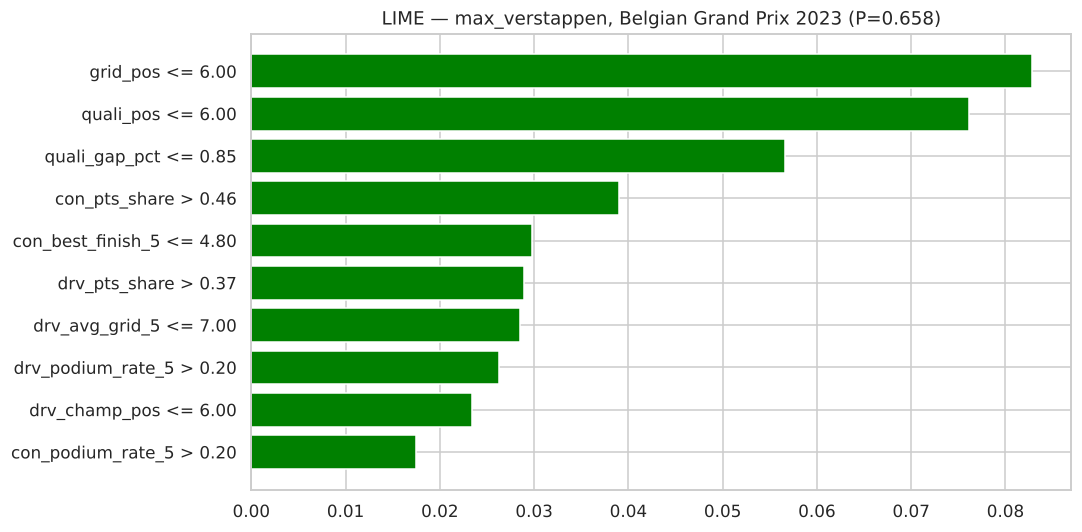

,condition,weight
0,grid_pos <= 6.00,0.0829
1,quali_pos <= 6.00,0.0761
2,quali_gap_pct <= 0.85,0.0566
3,con_pts_share > 0.46,0.0390
4,con_best_finish_5 <= 4.80,0.0298
5,drv_pts_share > 0.37,0.0290
6,drv_avg_grid_5 <= 7.00,0.0285
7,drv_podium_rate_5 > 0.20,0.0263
8,drv_champ_pos <= 6.00,0.0234
9,con_podium_rate_5 > 0.20,0.0175


LIME local surrogate R^2: 0.733


In [59]:
from lime.lime_tabular import LimeTabularExplainer
lime_exp = LimeTabularExplainer(Xt_tr.values, feature_names=feat_names_t, class_names=['no podium', 'podium'],
                                mode='classification', discretize_continuous=True, random_state=SEED)
exp = lime_exp.explain_instance(Xt_te.iloc[row_i].values, clf_fitted.predict_proba, num_features=10, num_samples=4000)
fig = exp.as_pyplot_figure(label=1); fig.set_size_inches(10, 5)
plt.title(f"LIME — {row.driverRef}, {row['name']} {int(row.year)} (P={exp.predict_proba[1]:.3f})"); savefig('xai_local_lime')
lime_tab = pd.DataFrame(exp.as_list(label=1), columns=['condition', 'weight'])
display(lime_tab.round(4))
print('LIME local surrogate R^2:', round(exp.score, 3))
RESULTS['lime'] = lime_tab.round(4).values.tolist()

**Interpretation of the local explanations (Verstappen, Belgian GP 2023).**
* He qualified **P1** but started **P6** after a gearbox penalty, so the grid-only rule would not have picked him.
* The SHAP waterfall starts from the average podium probability (0.14). **Pole position in qualifying (+0.10)** and a **zero gap to pole (+0.09)** push up, along with strong form (`drv_podium_rate_5`, +0.05) and standings. The **grid slot P6 pulls down (−0.06)**. The final probability is 0.66, above the threshold, so the model predicts a podium. He won the race.
* LIME tells the same story with simple rules: `grid_pos ≤ 6`, `quali_pos ≤ 6` and `quali_gap_pct ≤ 0.85` carry the largest positive weights, followed by car and driver strength. The local surrogate fits reasonably (R² ≈ 0.73).
* This is the value of keeping **qualifying and grid as separate features** (the Q1 finding). Again, this explains the *model's* reasoning, not why the race went the way it did.

> **Key takeaway:** global explanations (permutation importance, SHAP) and local explanations (SHAP waterfall, LIME) agree. The model relies on starting position, qualifying pace and car strength.

## 11. Saved artifacts, reusable pipeline and inference function
### 11.1 Persist everything a later milestone needs
* `artifacts/model.joblib`: the selected, fitted pipeline (preprocessing + model).
* `artifacts/feature_spec.json`: feature list, groups, threshold, training medians, split years, and the metrics on validation and test.
* `artifacts/modelling_table.csv.gz` and `artifacts/clean/*.csv.gz`: the leakage-safe modelling table and the cleaned relational tables.

A later milestone (API, dashboard, new model) can start from these files without re-running this notebook.

In [60]:
import joblib
os.makedirs('artifacts/clean', exist_ok=True)
joblib.dump(final_model, 'artifacts/model.joblib')
for fam, m in final_models.items():
    if fam != 'Baseline 0: grid rule':
        joblib.dump(m, f"artifacts/model_{fam.split(' ')[0].lower()}.joblib")
train_medians = X_tr.median(numeric_only=True).round(6).to_dict()
spec = {'version': '1.0.0', 'target': 'podium = positionOrder <= 3', 'cutoff': 'after qualifying, before race start',
        'final_model': FINAL_NAME, 'config': comp.loc[FINAL_NAME, 'config'], 'threshold': float(comp.loc[FINAL_NAME, 'threshold']),
        'features': FEATURES, 'feature_groups': FEATURE_GROUPS, 'train_medians': train_medians,
        'splits': {'train': TRAIN_YEARS, 'val': VAL_YEARS, 'test': TEST_YEARS}, 'model_start_season': MODEL_START,
        'metrics': {s: {k: float(comp.loc[FINAL_NAME, f'{s} {k}']) for k in METRICS} for s in ['val', 'test']}}
json.dump(spec, open('artifacts/feature_spec.json', 'w'), indent=2, default=str)
df_model[META + FEATURES + [TARGET, 'split']].to_csv('artifacts/modelling_table.csv.gz', index=False)
for t in ['races', 'circuits', 'drivers', 'constructors', 'status', 'qualifying', 'driver_standings', 'constructor_standings',
          'pit_stops', 'sprint_results', 'seasons', 'constructor_results', 'lap_times']:
    clean[t].to_csv(f'artifacts/clean/{t}.csv.gz', index=False)
clean['results_u'].to_csv('artifacts/clean/results_unique.csv.gz', index=False)
print(sorted(os.listdir('artifacts')))

['clean', 'feature_spec.json', 'model.joblib', 'model_lightgbm.joblib', 'model_logistic.joblib', 'model_random.joblib', 'model_shallow.joblib', 'modelling_table.csv.gz']


### 11.2 Reusable end-to-end pipeline (raw CSV folder → modelling table)
The whole cleaning and feature chain is packaged as one function. We verify that it reproduces the notebook's modelling table **exactly**, so the package can be trusted in later milestones (for example, to rebuild features when new races are added).

In [61]:
%%writefile f1podium/pipeline.py
"""One call from the raw CSV folder to the leakage-safe modelling table."""
from f1podium import cleaning, grain, entries, features


def load_clean(data_dir, last_season=2024):
    raw = cleaning.load_raw(data_dir)
    clean = {t: cleaning.clean_table(raw[t], cleaning.SCHEMA[t]) for t in cleaning.TABLES}
    cleaning.apply_scope(clean, last_season)
    cleaning.fix_implausible_quali(clean)
    cleaning.canonicalise(clean)
    cleaning.drop_duplicate_laps(clean)
    clean['results_u'] = grain.dedupe_results(clean['results'])
    return clean


def build_all(data_dir, last_season=2024):
    """Returns (clean tables, joined entries, feature table for ALL seasons)."""
    clean = load_clean(data_dir, last_season)
    ent = entries.build_entries(clean)
    feat = features.build_features(ent, clean['driver_standings'], clean['constructor_standings'], clean['races'])
    return clean, ent, feat


def build_modelling_table(data_dir, start=2003, last_season=2024):
    _, _, feat = build_all(data_dir, last_season)
    return feat[feat.year.between(start, last_season)].reset_index(drop=True)

Writing f1podium/pipeline.py


In [62]:
import f1podium.pipeline as fpl; importlib.reload(fpl)
rebuilt = fpl.build_modelling_table(DATA_DIR, start=MODEL_START, last_season=LAST_SEASON)
pd.testing.assert_frame_equal(rebuilt[['raceId', 'driverId'] + FEATURES + [TARGET]].reset_index(drop=True),
                              df_model[['raceId', 'driverId'] + FEATURES + [TARGET]].reset_index(drop=True), check_dtype=False)
print('f1podium.pipeline reproduces the modelling table exactly:', rebuilt.shape)

f1podium.pipeline reproduces the modelling table exactly: (8970, 78)


### 11.3 Inference function
`predict_podium(record)` takes a plain dictionary of **pre-race** inputs, the same interface a web API or app would use.
* It **rejects leakage fields** (e.g. `points`, `positionOrder`, `laps`, `statusId`). Passing post-race information is an error, not a silent mistake.
* Missing keys are allowed. A simple domain rule fills `grid_pos` from `quali_pos` (assuming no penalty) when only qualifying is known. Everything else is filled by the pipeline's training medians, and the missing indicators flag it. The function reports which inputs were imputed, so the user knows how much of the answer is guesswork.
* It returns the probability, the yes/no call at the validation-chosen threshold, and the list of imputed fields.

In [63]:
%%writefile f1podium/inference.py
"""Load the saved model + spec and predict P(podium) for one pre-race record (dict) or a DataFrame."""
import json
import os
import numpy as np
import pandas as pd

LEAKAGE_FIELDS = {'positionOrder', 'position', 'positionText', 'points', 'laps', 'time', 'milliseconds', 'statusId',
                  'status', 'fastestLap', 'fastestLapTime', 'fastestLapSpeed', 'rank', 'podium', 'pit_stops', 'lap_times'}


class PodiumPredictor:
    def __init__(self, model, spec):
        self.model, self.spec = model, spec
        self.features, self.threshold = spec['features'], float(spec['threshold'])

    @classmethod
    def load(cls, artifact_dir='artifacts'):
        import joblib
        model = joblib.load(os.path.join(artifact_dir, 'model.joblib'))
        spec = json.load(open(os.path.join(artifact_dir, 'feature_spec.json')))
        return cls(model, spec)

    def _frame(self, record):
        leak = LEAKAGE_FIELDS & set(record)
        if leak:
            raise ValueError(f'post-race (leakage) fields are not allowed at prediction time: {sorted(leak)}')
        unknown = set(record) - set(self.features) - {'raceId', 'driverId', 'driver', 'race'}
        rec = {f: record.get(f, np.nan) for f in self.features}
        rec = {k: (np.nan if v is None else v) for k, v in rec.items()}
        derived = []
        if pd.isna(rec.get('grid_pos')) and not pd.isna(rec.get('quali_pos')):
            rec['grid_pos'] = rec['quali_pos']; derived.append('grid_pos<-quali_pos')
            if pd.isna(rec.get('grid_penalty')):
                rec['grid_penalty'] = 0.0; derived.append('grid_penalty<-0')
        if pd.isna(rec.get('pitlane_start')) and not pd.isna(rec.get('grid_pos')):
            rec['pitlane_start'] = 0; derived.append('pitlane_start<-0')
        X = pd.DataFrame([rec], columns=self.features).astype(float)
        imputed = [f for f in self.features if pd.isna(X.at[0, f])]
        return X, imputed, derived, sorted(unknown)

    def predict(self, record):
        X, imputed, derived, unknown = self._frame(record)
        p = float(self.model.predict_proba(X)[0, 1])
        return {'p_podium': round(p, 4), 'podium': bool(p >= self.threshold), 'threshold': round(self.threshold, 4),
                'n_inputs_given': len(self.features) - len(imputed) - len(derived),
                'imputed_by_model': imputed, 'derived_by_rule': derived, 'ignored_unknown_keys': unknown}

    def predict_frame(self, df):
        return self.model.predict_proba(df[self.features].astype(float))[:, 1]


_DEFAULT = None


def predict_podium(record, predictor=None, artifact_dir='artifacts'):
    """Convenience wrapper: predict_podium({'grid_pos': 2, 'quali_pos': 2, ...})"""
    global _DEFAULT
    if predictor is None:
        if _DEFAULT is None:
            _DEFAULT = PodiumPredictor.load(artifact_dir)
        predictor = _DEFAULT
    return predictor.predict(record)

Writing f1podium/inference.py


In [64]:
import f1podium.inference as finf; importlib.reload(finf)
from f1podium.inference import PodiumPredictor, predict_podium
predictor = PodiumPredictor.load('artifacts')

# (a) COMPLETE record: a real driver-race from the unseen test seasons (all 28 pre-race features present)
complete_rows = te[te[FEATURES].notna().all(axis=1)]
ex = complete_rows[(complete_rows.year == 2024)].sort_values('date').iloc[-1:]
if ex.empty: ex = complete_rows.iloc[-1:]
ex = ex.iloc[0]
record_complete = {f: float(ex[f]) for f in FEATURES}
out_c = predict_podium(record_complete, predictor)
print(f"COMPLETE record — {ex['name']} {int(ex.year)}, {ex.driverRef} ({ex.constructor}), grid {int(ex.grid_pos)}; actual finish P{int(ex.positionOrder)}")
print(json.dumps(out_c, indent=2))
assert abs(out_c['p_podium'] - predictor.predict_frame(te.loc[[ex.name]])[0]) < 1e-4   # same as batch scoring

# (b) PARTIALLY-MISSING record: only what a fan knows right after qualifying
record_partial = {'quali_pos': 3, 'quali_gap_pct': 0.25, 'con_pts_share': 0.85, 'drv_pts_share': 0.6, 'home_race': 0}
out_p = predict_podium(record_partial, predictor)
print('\nPARTIAL record (5 of 28 inputs):', record_partial)
print(json.dumps(out_p, indent=2))

# (c) the same partial record from the back of the grid, and a leakage attempt that must be refused
print('\nSame record but qualifying P15:', predict_podium({**record_partial, 'quali_pos': 15, 'quali_gap_pct': 1.8}, predictor)['p_podium'])
try:
    predict_podium({**record_partial, 'points': 18}, predictor)
except ValueError as e:
    print('Leakage guard works ->', e)
RESULTS['inference'] = dict(complete=out_c, partial=out_p)

COMPLETE record — Abu Dhabi Grand Prix 2024, leclerc (Ferrari), grid 19; actual finish P3
{
  "p_podium": 0.2008,
  "podium": false,
  "threshold": 0.4158,
  "n_inputs_given": 28,
  "imputed_by_model": [],
  "derived_by_rule": [],
  "ignored_unknown_keys": []
}



PARTIAL record (5 of 28 inputs): {'quali_pos': 3, 'quali_gap_pct': 0.25, 'con_pts_share': 0.85, 'drv_pts_share': 0.6, 'home_race': 0}
{
  "p_podium": 0.3832,
  "podium": false,
  "threshold": 0.4158,
  "n_inputs_given": 5,
  "imputed_by_model": [
    "teammate_quali_diff",
    "drv_champ_pos",
    "drv_season_wins",
    "con_champ_pos",
    "prev_season_drv_pos",
    "prev_season_con_pos",
    "first_round",
    "drv_podium_rate_5",
    "drv_avg_finish_5",
    "drv_dnf_rate_5",
    "drv_avg_grid_5",
    "con_podium_rate_5",
    "con_best_finish_5",
    "con_mech_dnf_rate_10",
    "drv_prior_starts",
    "drv_career_podium_rate",
    "drv_circuit_starts",
    "drv_circuit_podium_rate",
    "driver_age",
    "field_size"
  ],
  "derived_by_rule": [
    "grid_pos<-quali_pos",
    "grid_penalty<-0",
    "pitlane_start<-0"
  ],
  "ignored_unknown_keys": []
}



Same record but qualifying P15: 0.0606
Leakage guard works -> post-race (leakage) fields are not allowed at prediction time: ['points']


**Reading the inference demo.**
* **Complete record** (Leclerc, Abu Dhabi 2024, all 28 inputs present): the function reproduces the batch-scoring probability exactly (0.20). He started P19 after a penalty, so the model says "no podium". He actually finished P3, a genuine miss and a reminder that big comebacks are hard to predict before the race.
* **Partial record** (only 5 of 28 inputs): the function still answers. It derives `grid_pos` from `quali_pos`, fills the other 20 inputs with training medians plus missing indicators, and lists every filled field. A P3 qualifier in a top car gets 0.38, a contender just under the 0.42 threshold. The same inputs from P15 drop to 0.06.
* Passing a post-race field (`points`) is refused.

## 12. Analytical report
*(The same content, with figures, is in the separate PDF report.)*

### 12.1 Data-engineering answers
**Q1: front-row conversion by circuit.** A front-row **grid** start became a podium 68% of the time in 2003–2013 and 76% in 2014–2024. The highest-converting circuits were Magny-Cours, Istanbul, Monaco and Monza before 2014, and Suzuka, Yas Marina, Monaco, Spa and Barcelona after. The ranking **does change**: Spearman ρ = 0.30 (p = 0.29) across the 14 circuits ranked in both eras, and only Monaco stays near the top. Qualifying and grid front rows disagree in 74 cases because of penalties, and grid-based conversion is slightly higher, so **the grid is the better pre-race signal** (figure `q1_front_row_conversion`).

**Q2: home advantage.** Raw podium rates are 11.4% at home vs 13.8% away, but home drivers start further back (grid 13.3 vs 11.7). Within the same grid bands the rates are almost identical. CMH OR = 0.94 (p = 0.42); logistic OR = 0.92 [0.78, 1.08]. **There is no evidence of a home advantage once starting position is controlled for** (figure `q2_home_advantage`).

**Q3: mechanical retirements.** The rate fell from 9.6% of starts (2014–2021) to 6.0% (2022–2024). The worst teams in 2014–2021 were Caterham 23.5%, Lotus 17.3%, Toro Rosso 16.1%, McLaren 14.5% and Renault 14.0%. In 2022–2024 they were Alfa Romeo 12.5%, Alpine 11.0% and AlphaTauri 8.0%. Mercedes (2014–21) and Red Bull/McLaren (2022–24) were the most reliable. The generic "Retired" code is excluded and shown as an upper bound (figure `q3_mechanical_retirements`).

### 12.2 Selected features and why each is valid at the pre-race cutoff

In [65]:
validity = {
    'grid_pos': 'official starting grid (after penalties) is published before the start; grid 0 → back of field',
    'pitlane_start': 'known from the published grid',
    'quali_pos': 'qualifying session result (Saturday)',
    'quali_gap_pct': 'computed from the qualifying lap times of this weekend',
    'grid_penalty': 'grid − qualifying position; both known before the start',
    'teammate_quali_diff': 'both drivers\' qualifying positions are known after qualifying',
    'drv_pts_share': 'driver standings after the PREVIOUS round, divided by the leader',
    'drv_champ_pos': 'championship position after the previous round',
    'drv_season_wins': 'wins so far this season, before this race',
    'con_pts_share': 'constructor standings after the previous round',
    'con_champ_pos': 'constructor position after the previous round',
    'prev_season_drv_pos': 'final position in the previous season',
    'prev_season_con_pos': 'final constructor position in the previous season',
    'first_round': 'calendar fact (no standings yet)',
    'drv_podium_rate_5': 'last 5 races of the driver, shift(1): excludes this race',
    'drv_avg_finish_5': 'last 5 races, shift(1)',
    'drv_dnf_rate_5': 'last 5 races, shift(1)',
    'drv_avg_grid_5': 'last 5 races, shift(1)',
    'con_podium_rate_5': 'team results aggregated per race, then the last 5 races, shift(1) (team-mate\'s current result excluded)',
    'con_best_finish_5': 'as above',
    'con_mech_dnf_rate_10': 'team mechanical DNFs in the last 10 races, shift(1)',
    'drv_prior_starts': 'count of earlier starts',
    'drv_career_podium_rate': 'expanding mean of earlier races, shift(1)',
    'drv_circuit_starts': 'earlier starts at this circuit',
    'drv_circuit_podium_rate': 'earlier podium rate at this circuit, shift(1)',
    'driver_age': 'date of birth and race date (static)',
    'home_race': 'nationality and circuit country (static)',
    'field_size': 'number of entrants on the grid',
}
feat_table = pd.DataFrame([{'group': g, 'feature': f, 'why it is valid before the race': validity[f],
                            'univariate AUC (train)': float(evidence.set_index('feature').loc[f, 'univariate AUC']),
                            'perm. importance (val)': float(pi_df.set_index('feature').loc[f, 'mean'])}
                           for g, fs in FEATURE_GROUPS.items() for f in fs])
feat_table.to_csv(os.path.join(OUT_DIR, 'feature_validity.csv'), index=False)
feat_table.round(3)

,group,feature,why it is valid before the race,univariate AUC (train),perm. importance (val)
0,grid,grid_pos,official starting grid (after penalties) is pu...,0.904,0.053
1,grid,pitlane_start,known from the published grid,0.501,0.000
2,qualifying,quali_pos,qualifying session result (Saturday),0.907,0.025
3,qualifying,quali_gap_pct,computed from the qualifying lap times of this...,0.886,0.017
4,qualifying,grid_penalty,grid − qualifying position; both known before ...,0.552,0.000
5,qualifying,teammate_quali_diff,both drivers' qualifying positions are known a...,0.602,0.002
6,standings,drv_pts_share,"driver standings after the PREVIOUS round, div...",0.848,0.003
7,standings,drv_champ_pos,championship position after the previous round,0.886,0.003
8,standings,drv_season_wins,"wins so far this season, before this race",0.745,0.002
9,standings,con_pts_share,constructor standings after the previous round,0.852,0.003


### 12.3 Modelling summary
* **Primary metric: PR-AUC** (rare positive class; it rewards ranking the real contenders). **Secondary: F1** at the threshold chosen on validation (the yes/no call a companion app makes).
* **Selected model: random forest** (400 trees, min 10 samples per leaf), with **test PR-AUC 0.720, ROC-AUC 0.940, F1 0.677**. The grid-only baseline gets 0.646 / 0.911 / 0.661 and the logistic-regression baseline 0.712 / 0.937 / 0.668. LightGBM (0.724 test PR-AUC) and the shallow NN (0.694) are close, so the result does not depend on one family.
* **Ablation and XAI agree:** grid/qualifying (as substitutes) and standings carry the predictive information. Driver form, experience and context add little once these are known.

### 12.4 Known limitations
1. **Qualifying-coverage drift.** Qualifying is complete only from 2003, so the model ignores 1950–2002 as training rows (that history is still used for career features). Earlier eras would need a different feature set.
2. **Era sensitivity.** Regulation changes (2009, 2014, 2017, 2022), points systems (handled by normalising points by the leader) and dominant-team periods shift the base rates. Performance dips in 2022 and 2024, the most competitive seasons. The model should be retrained as new seasons arrive.
3. **Small and dependent sample.** About 9k rows, 3 positives per race, team-mates sharing a car. The differences between the top models (about 0.01 PR-AUC) are within season-to-season variation.
4. **Limited within-race re-ordering.** The top-3 hit rate is about the same as the grid rule. The model estimates podium likelihood well but rarely beats "the top 3 on the grid" at picking the exact podium of a race. Race-relative features (each driver's strength *relative to the rest of the field*) are a natural next step.
5. **Unknowable events.** Crashes, safety cars, weather and strategy happen after the cutoff. Big comebacks (e.g. Leclerc P19 → P3, Abu Dhabi 2024) will be missed by design.
6. **Data definitions.** "Home race" uses nationality, not residence. The mechanical-retirement list is a documented judgement, and the generic "Retired" code is ambiguous. Renamed constructors (Toro Rosso → AlphaTauri → RB) do not share history across IDs.
7. **Explanations are not causal.** Importance shows what the model relies on. Car speed is the real driver of results, and the standings features are proxies for it.

### 12.5 Ready for the next milestones
* `f1podium/` package: `pipeline.build_modelling_table(data_dir)` rebuilds the whole table from raw CSVs, and `inference.predict_podium(record)` scores one record. Both are tested in this notebook.
* `artifacts/`: the fitted model (`model.joblib`), `feature_spec.json` (features, threshold, metrics), the modelling table and the cleaned tables.
* Every model shares one interface (`fit` / `predict_proba`), so a new model can drop in without touching the rest.

In [66]:
json.dump(RESULTS, open(os.path.join(OUT_DIR, 'results.json'), 'w'), indent=2, default=str)
print('saved', os.path.join(OUT_DIR, 'results.json'))

saved outputs/results.json
